# Single-epoch walkthrough: from raw data to the replay-content regressions

This notebook walks the **base non-local analysis pipeline for one session** —
`chimi`, day `20200213`, epoch `02_r1`, hippocampus (HPC) — from the
canonical decoder and behavioral-belief artifacts through four regression-
model families: arm content (M), patch content (P), per-stop event rate (R,
Family A), and next-arm choice (C). The arm/patch sections include the
Beta-Bernoulli value and uncertainty branches that are central to the story.

Not covered here: the per-bin conditional-intensity rate ladder (Family B,
`MODEL_PER_BIN_RATE`), the dedicated SWR-contrast ladders, and event-source
comparisons. See `docs/models_table.md` for the full model catalog.

**Why one epoch is the right fitting unit.** The production pipeline
(`scripts/replay_models/content/fit_replay_content_models.py`,
`scripts/replay_models/content/compare_event_source_models.py`, and
`scripts/replay_models/rate/fit_per_stop_rate_models.py`) fits models separately for each
`(animal, day, epoch)`. The population result aggregates those session fits;
this notebook reproduces one fitting unit, not population inference.

**Decoding is loaded, not re-run.** The non-local state-space decoder is
GPU-heavy and runs for hours per epoch. Its outputs are already on disk
(`Processed-Data/*_results.nc`, `*_environment.pkl`,
`*_data_over_time.pkl`). We *show* the decode call for reference but **load**
its outputs. Building the posterior-weighted tables is still memory-intensive.
The externally fitted behavioral model is likewise **loaded, not re-fit**:
`qvals_table.parquet` carries its pre-outcome trial beliefs, and the persisted
all-session reference supplies the correct global standardization.

**Current canonical assembly.** Table construction mirrors
`continuum_swr_replay.analysis.event_tables.prepare_data`: validate `dot`, build the
zero-inclusive stop denominator first, construct event/arm/sequence tables,
merge retrospective metrics, derive the SWR/non-SWR stop split, and check
cross-table invariants. Model fits use the package fitters and freeze one
comparison-valid complete-case cohort per block. The rate section separately
reports the same per-rung cross-validation metric as its production runner.

## Pipeline

```
load_data(trials only; position is always loaded)
             │
precomputed dot + environment + posterior
             │
validate_dot_event_contract
             │
     ┌──────────┴───────────┐
     ▼                     ▼
build_stop_table       build_event_table       qvals + frozen global z
     │                     │                           │
     │             build_event_arm_table ◄────────────┘
     │                │             │
     │                ▼             ▼
     │       event_sequence +    event_patch_table
     │       retrospective merge
     └──────────┬──────────────────┘
                ▼
      invariant + common-cohort gates
       │             │             │          │          │
       ▼             ▼             ▼          ▼          ▼
     M0–M7    M5/Mv/Mu/Mvu      P + Pv    R0–R2/Rlag   C primary
```

In [1]:
import logging
import pickle

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib import patheffects
from matplotlib.lines import Line2D

# --- Data loading + decode outputs ---
from continuum_swr_replay.analysis.event_definition.cohort_selection import freeze_common_cohort
from continuum_swr_replay.analysis.detection.nonlocal_events import (
    validate_dot_event_contract,
)
from continuum_swr_replay.analysis.replay_models.model_specs import add_arm_fixed_effects
from continuum_swr_replay.analysis.replay_models.choice.choice_prediction import (
    build_choice_dataset,
    fit_choice_model,
)
from continuum_swr_replay.analysis.replay_models.covariate_timing import (
    assert_predictor_timing,
)
from continuum_swr_replay.analysis.behavior.covariates import load_contingency

# --- Fitters (statsmodels conditional models / Poisson GLM) ---
from continuum_swr_replay.analysis.replay_models.fitting import fit_conditional_poisson
from continuum_swr_replay.analysis.replay_models.content.model_checking import (
    cross_validate_conditional_poisson,
)

# --- Model specifications (the four families walked here) ---
from continuum_swr_replay.analysis.replay_models.model_specs import (
    MODEL_CHOICE,  # C_*          : next-arm choice
    MODEL_HIERARCHY,  # M0–M7        : arm content
    MODEL_PATCH,  # P0–P4        : patch content
    MODEL_PER_STOP_RATE,  # R0-R2, Rlag  : event rate per stop (Family A)
    N_REWARD_LAGS,
    default_content_model_names,
)
from continuum_swr_replay.analysis.replay_models.rate.per_stop_rate_model import (
    PER_STOP_RATE_OUTCOMES,
    cross_validate_per_stop_rate_model,
    fit_per_stop_rate_model,
)
from continuum_swr_replay.analysis.decode_quality.posterior_analysis import (
    load_conditional_posterior,
)
from continuum_swr_replay.analysis.event_tables.retrospective_metrics import (
    compute_retrospective_metrics,
)
from continuum_swr_replay.tables.standardization import (
    attach_standardized,
    load_reference,
)

# --- Canonical table assembly (same functions as prepare_data) ---
from continuum_swr_replay.analysis.event_tables._common import (
    EVENT_ARM_STANDARDIZED_COLS,
)
from continuum_swr_replay.analysis.event_tables.arm_patch_tables import (
    build_event_arm_table,
    build_event_patch_table,
)
from continuum_swr_replay.analysis.event_tables.event_table import (
    build_event_sequence_table,
    build_event_table,
)
from continuum_swr_replay.analysis.event_tables.stop_table import (
    add_nonlocal_swr_split,
    build_stop_table,
)
from continuum_swr_replay.analysis.replay_models.content.uncertainty_content import (
    build_trial_leaf_table,
    hierarchical_quartile_profile,
)
from continuum_swr_replay.data_loaders import load_data
from continuum_swr_replay.parameters import PROCESSED_DATA_DIR
from continuum_swr_replay.data_types import SessionDataKeys
from continuum_swr_replay.visualization.session_tables import (
    BEHAVIORAL_MODEL_PANELS,
    plot_session_tables,
)

logging.basicConfig(level=logging.WARNING)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# Explicit comparison blocks keep qvals coverage from shrinking unrelated base
# ladders while still fitting the behavioral-belief branches on one fair cohort.
ARM_MODELS = {
    name: MODEL_HIERARCHY[name]
    for name in default_content_model_names(MODEL_HIERARCHY)
}
PATCH_MODELS = {
    name: MODEL_PATCH[name]
    for name in default_content_model_names(MODEL_PATCH)
}
BELIEF_ARM_MODELS = {
    name: MODEL_HIERARCHY[name] for name in ("M5", "Mv", "Mu", "Mvu")
}
BELIEF_PATCH_MODELS = {name: MODEL_PATCH[name] for name in ("P3", "Pv")}
RATE_MODELS = dict(MODEL_PER_STOP_RATE)
CHOICE_MODELS = {
    name: MODEL_CHOICE[name]
    for name in ("C_replay_only", "C_behavior", "C_full")
}
CHOICE_SPLIT_MODELS = {
    name: MODEL_CHOICE[name] for name in ("C_behavior", "C_full_swr_split")
}

for model_block in (
    ARM_MODELS,
    PATCH_MODELS,
    BELIEF_ARM_MODELS,
    BELIEF_PATCH_MODELS,
    RATE_MODELS,
    CHOICE_MODELS,
    CHOICE_SPLIT_MODELS,
):
    for spec in model_block.values():
        assert_predictor_timing(spec.predictors)

/cumulus/edeno/continuum-swr-replay/.venv/lib/python3.11/site-packages/non_local_detector/likelihoods/clusterless_gmm.py:13: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm  # type: ignore[import-untyped]
[2026-08-10 11:57:53,665][INFO]: DataJoint 0.14.6 connected to edeno@lmf-db.cin.ucsf.edu:3306


## 0. Session selection

`chimi20200213_02_r1` — confirmed to have precomputed decoder outputs and a
rich event count. The identifiers below drive every subsequent cell; point
them at another `(nwb_file_name, epoch_name)` to repeat the whole notebook
for a different epoch of the same day (`04_r2`, `06_r3`) or any other
session.

In [2]:
NWB_FILE_NAME = "chimi20200213_.nwb"
EPOCH_NAME = "02_r1"
BRAIN_AREA = "HPC"

SESSION_ID = f"{NWB_FILE_NAME.replace('_.nwb', '')}_{EPOCH_NAME}_{BRAIN_AREA}"
DOT_FILE = PROCESSED_DATA_DIR / f"{SESSION_ID}_80_data_over_time.pkl"
ENV_FILE = PROCESSED_DATA_DIR / f"{SESSION_ID}_environment.pkl"
RESULTS_FILE = PROCESSED_DATA_DIR / f"{SESSION_ID}_results.nc"
REPLAY_CONTENT_DIR = PROCESSED_DATA_DIR / "replay_content"
QVALS_FILE = REPLAY_CONTENT_DIR / "qvals_table.parquet"
ARM_Z_REFERENCE_FILE = REPLAY_CONTENT_DIR / "standardization_reference.json"
HORSERACE_COEFS_FILE = (
    REPLAY_CONTENT_DIR
    / "uncertainty_content"
    / "horserace_session_coefficients.csv"
)

for p in (
    DOT_FILE,
    ENV_FILE,
    RESULTS_FILE,
    QVALS_FILE,
    ARM_Z_REFERENCE_FILE,
    HORSERACE_COEFS_FILE,
):
    print(f"{'OK ' if p.exists() else 'MISSING'} {p.name}")

OK  chimi20200213_02_r1_HPC_80_data_over_time.pkl
OK  chimi20200213_02_r1_HPC_environment.pkl
OK  chimi20200213_02_r1_HPC_results.nc
OK  qvals_table.pkl
OK  standardization_reference.json
OK  horserace_session_coefficients.csv


## 1. Load trials and track geometry from Spyglass

The canonical prep driver asks Spyglass only for `trials` and the track graph;
position is always loaded because it defines the session time bounds. Neural
signals and decoder summaries are already represented in the precomputed
`dot` artifact, so loading them again would add cost without changing any
table below. Production can serve trials/graph from its `_session_cache` for
covariate-only rebuilds; this walkthrough performs the live load.

In [3]:
data = load_data(
    NWB_FILE_NAME,
    EPOCH_NAME,
    include=frozenset({SessionDataKeys.TRIALS}),
)

position_info = data["position_info"]
trials = data["trials"]
track_graph = data["track_graph"]
linear_edge_order = data["linear_edge_order"]
linear_edge_spacing = data["linear_edge_spacing"]

print("loaded keys   :", sorted(data))
print("position_info :", position_info.shape, "| time-indexed in seconds")
print("trials        :", trials.shape)
print("\nposition_info columns:\n", list(position_info.columns))

[2026-08-10 11:58:26,367][WARNING]: Skipped checksum for file with hash: d35d597a-c048-d50d-4027-9240721ee8ac, and path: /stelmo/nwb/raw/chimi20200213_.nwb
[2026-08-10 11:58:26,371][WARNING]: Skipped checksum for file with hash: d35d597a-c048-d50d-4027-9240721ee8ac, and path: /stelmo/nwb/raw/chimi20200213_.nwb
[2026-08-10 11:58:26,374][WARNING]: Skipped checksum for file with hash: d35d597a-c048-d50d-4027-9240721ee8ac, and path: /stelmo/nwb/raw/chimi20200213_.nwb
[2026-08-10 11:58:26,376][WARNING]: Skipped checksum for file with hash: d35d597a-c048-d50d-4027-9240721ee8ac, and path: /stelmo/nwb/raw/chimi20200213_.nwb
[2026-08-10 11:58:26,378][WARNING]: Skipped checksum for file with hash: d35d597a-c048-d50d-4027-9240721ee8ac, and path: /stelmo/nwb/raw/chimi20200213_.nwb
[2026-08-10 11:58:26,380][WARNING]: Skipped checksum for file with hash: d35d597a-c048-d50d-4027-9240721ee8ac, and path: /stelmo/nwb/raw/chimi20200213_.nwb
[2026-08-10 11:58:26,384][WARNING]: Skipped checksum for file wi

loaded keys   : ['linear_edge_order', 'linear_edge_spacing', 'position_info', 'track_graph', 'trials']
position_info : (1807725, 11) | time-indexed in seconds
trials        : (279, 10)

position_info columns:
 ['head_position_x', 'head_position_y', 'head_orientation', 'head_velocity_x', 'head_velocity_y', 'head_speed', 'linear_position', 'track_segment_id', 'projected_x_position', 'projected_y_position', 'patch_id']


In [4]:
trials.head()

,is_reward,start_time,end_time,is_patch_change,from_well,to_well,from_patch,to_patch,duration,goal_arrival_time
trial_number,,,,,,,,,,
1,True,1.581636e+09,1.581636e+09,False,3,2,2,2,36.288432,1.581636e+09
2,True,1.581636e+09,1.581636e+09,True,2,0,2,1,26.921571,1.581636e+09
3,False,1.581636e+09,1.581636e+09,False,0,1,1,1,14.855222,1.581636e+09
4,True,1.581636e+09,1.581636e+09,False,1,0,1,1,13.975665,1.581636e+09
5,True,1.581636e+09,1.581636e+09,True,0,5,1,3,15.334975,1.581636e+09


### 1a. Orientation plots

Linearized position over the whole epoch (left) and the 2-D track-graph
layout with the nine arms the decoder maps replay onto (right). The
"three-legged spider": six leaf arms (well ↔ patch junction, arms 0–5) and
three trunk arms (patch junction ↔ center, arms 6–8).

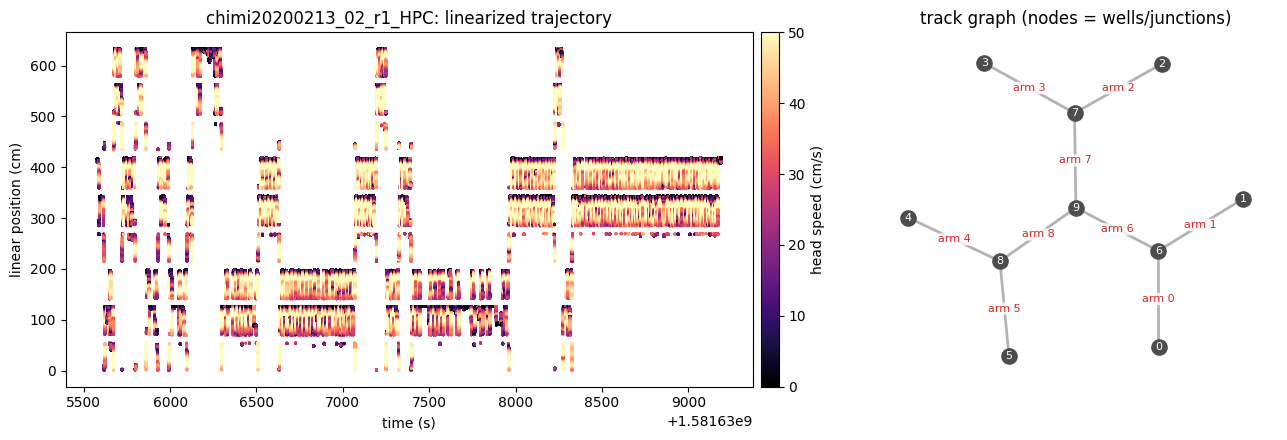

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), width_ratios=[2, 1])

# Linearized position over time, colored by head speed.
ax = axes[0]
sc = ax.scatter(
    position_info.index,
    position_info["linear_position"],
    c=position_info["head_speed"],
    s=1,
    cmap="magma",
    vmin=0,
    vmax=50,
    rasterized=True,
)
ax.set(xlabel="time (s)", ylabel="linear position (cm)",
       title=f"{SESSION_ID}: linearized trajectory")
fig.colorbar(sc, ax=ax, label="head speed (cm/s)", pad=0.01)

# 2-D track graph with arm (edge) ids.
ax = axes[1]
node_pos = {n: track_graph.nodes[n]["pos"] for n in track_graph.nodes}
nx.draw_networkx_edges(track_graph, node_pos, ax=ax, edge_color="0.7", width=2)
nx.draw_networkx_nodes(track_graph, node_pos, ax=ax, node_size=120,
                       node_color="0.3")
nx.draw_networkx_labels(track_graph, node_pos, ax=ax, font_color="white",
                        font_size=8)
for u, v, d in track_graph.edges(data=True):
    if "edge_id" in d:
        mx = 0.5 * (node_pos[u][0] + node_pos[v][0])
        my = 0.5 * (node_pos[u][1] + node_pos[v][1])
        ax.text(mx, my, f"arm {d['edge_id']}", color="C3", fontsize=8,
                ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none",
                          alpha=0.8))
ax.set(title="track graph (nodes = wells/junctions)")
ax.set_aspect("equal")
ax.axis("off")
fig.tight_layout()

max |duration - (end - start)| : 0.0
from_patch/to_patch match wells: True
is_patch_change matches patches: True
goal_arrival_time inside trial : True
wells chain (to[i] == from[i+1]): True


,is_reward,start_time,end_time,is_patch_change,from_well,to_well,from_patch,to_patch,duration,goal_arrival_time
trial_number,,,,,,,,,,
1,True,1.581636e+09,1.581636e+09,False,3,2,2,2,36.288432,1.581636e+09
2,True,1.581636e+09,1.581636e+09,True,2,0,2,1,26.921571,1.581636e+09
3,False,1.581636e+09,1.581636e+09,False,0,1,1,1,14.855222,1.581636e+09
4,True,1.581636e+09,1.581636e+09,False,1,0,1,1,13.975665,1.581636e+09
5,True,1.581636e+09,1.581636e+09,True,0,5,1,3,15.334975,1.581636e+09
...,...,...,...,...,...,...,...,...,...,...
275,True,1.581639e+09,1.581639e+09,False,2,3,2,2,11.979948,1.581639e+09
276,False,1.581639e+09,1.581639e+09,False,3,2,2,2,5.414744,1.581639e+09
277,False,1.581639e+09,1.581639e+09,False,2,3,2,2,5.500945,1.581639e+09


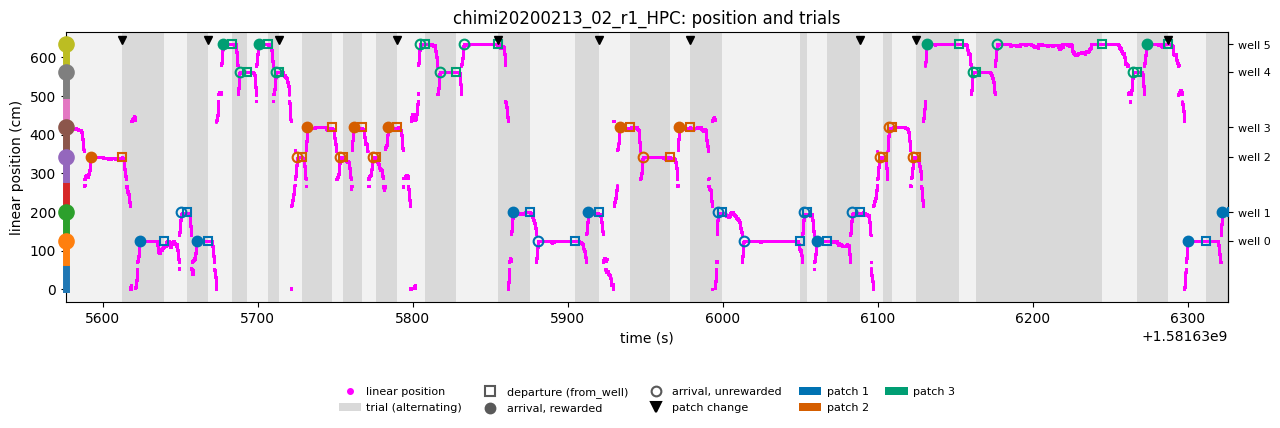

In [6]:
# check that trials make sense
from matplotlib.patches import Patch

from continuum_swr_replay.data_loaders import WELL_PATCH_MAPPING
from continuum_swr_replay.visualization import plot_graph_as_1D

t_start = float(position_info.index[0])
t_stop = t_start + 750.0

# Linear position of each degree-1 node (well), mirroring the cumulative
# arithmetic in plot_graph_as_1D so markers land on the same y axis.
spacing = (
    [float(linear_edge_spacing)] * (len(linear_edge_order) - 1)
    if np.isscalar(linear_edge_spacing)
    else list(linear_edge_spacing)
)
well_linear = {}
edge_start = 0.0
for i, (u, v) in enumerate(np.asarray(linear_edge_order)):
    edge_end = edge_start + track_graph.edges[u, v]["distance"]
    if track_graph.degree(u) == 1:
        well_linear[int(u)] = edge_start
    if track_graph.degree(v) == 1:
        well_linear[int(v)] = edge_end
    edge_start = edge_end + (spacing[i] if i < len(spacing) else 0.0)

PATCH_COLORS = {1: "#0072B2", 2: "#D55E00", 3: "#009E73"}  # Okabe-Ito

fig, ax = plt.subplots(figsize=(15, 3.5))

# spreadsheet-style alternating gray bands, one per trial
for row, (_, trial) in enumerate(trials.iterrows()):
    ax.axvspan(
        trial["movement_start_time"], trial["end_time"],
        color="0.85" if row % 2 else "0.95", linewidth=0, zorder=0,
    )

ax.scatter(
    position_info.index, position_info["linear_position"],
    s=1, color="magenta", rasterized=True, zorder=2,
)

blend = ax.get_xaxis_transform()
for _, trial in trials.iterrows():
    from_well, to_well = int(trial["from_well"]), int(trial["to_well"])
    # departure: open square at from_well, colored by from_patch
    ax.plot(
        trial["movement_start_time"], well_linear[from_well],
        marker="s", ms=6, mfc="none",
        mec=PATCH_COLORS[WELL_PATCH_MAPPING[from_well]], mew=1.5, zorder=4,
    )
    # arrival: circle at destination_first_poke_in_time, filled iff rewarded
    dest_color = PATCH_COLORS[WELL_PATCH_MAPPING[to_well]]
    ax.plot(
        trial["destination_first_poke_in_time"], well_linear[to_well],
        marker="o", ms=7,
        mfc=dest_color if trial["is_reward"] else "none",
        mec=dest_color, mew=1.5, zorder=4,
    )
    if trial["is_patch_change"]:
        ax.plot(
            trial["movement_start_time"], 0.97, marker="v", ms=6, color="black",
            transform=blend, zorder=5,
        )

ax.set(
    xlabel="time (s)", ylabel="linear position (cm)",
    title=f"{SESSION_ID}: position and trials", xlim=(t_start, t_stop),
)
well_axis = ax.secondary_yaxis("right")
well_axis.set_yticks([well_linear[w] for w in sorted(well_linear)])
well_axis.set_yticklabels([f"well {w}" for w in sorted(well_linear)], fontsize=8)


def _marker(marker, filled, label, color="0.35"):
    """Neutral-gray proxy handle — real markers are colored by patch."""
    return Line2D(
        [], [], linestyle="none", marker=marker, ms=7,
        mfc=color if filled else "none", mec=color, mew=1.5, label=label,
    )


legend_handles = [
    Line2D([], [], linestyle="none", marker="o", ms=4, color="magenta",
           label="linear position"),
    Patch(facecolor="0.85", edgecolor="none", label="trial (alternating)"),
    _marker("s", False, "departure (from_well)"),
    _marker("o", True, "arrival, rewarded"),
    _marker("o", False, "arrival, unrewarded"),
    _marker("v", True, "patch change", color="black"),
] + [
    Patch(facecolor=PATCH_COLORS[p], edgecolor="none", label=f"patch {p}")
    for p in sorted(PATCH_COLORS)
]
ax.legend(
    handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.28),
    ncol=5, fontsize=8, frameon=False, handletextpad=0.5, columnspacing=1.5,
)

reward_well_nodes = [n for n in track_graph.nodes if track_graph.degree(n) == 1]
plot_graph_as_1D(
    track_graph, ax=ax,
    edge_order=linear_edge_order, edge_spacing=linear_edge_spacing,
    reward_well_nodes=reward_well_nodes,
    other_axis_start=t_start,
    reward_well_size=120, edge_linewidth=5,
)

# Redundant columns — assert rather than draw.
patch_from = trials["from_well"].map(WELL_PATCH_MAPPING)
patch_to = trials["to_well"].map(WELL_PATCH_MAPPING)
print("max |duration - (end - start)| :",
      float((trials["duration"] - (trials["end_time"] - trials["movement_start_time"])).abs().max()))
print("from_patch/to_patch match wells:",
      bool((patch_from == trials["from_patch"]).all() and (patch_to == trials["to_patch"]).all()))
print("is_patch_change matches patches:",
      bool(((patch_from != patch_to) == trials["is_patch_change"]).all()))
print("destination_first_poke_in_time inside trial :",
      bool(((trials["destination_first_poke_in_time"] >= trials["movement_start_time"])
            & (trials["destination_first_poke_in_time"] <= trials["end_time"])).all()))
print("wells chain (to[i] == from[i+1]):",
      bool((trials["to_well"].values[:-1] == trials["from_well"].values[1:]).all()))

trials


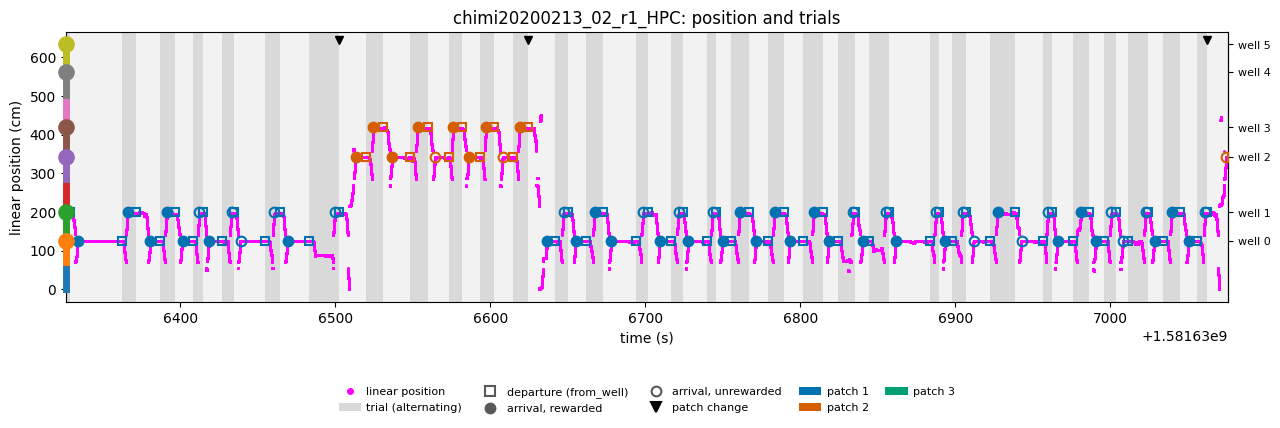

In [7]:
# check that trials make sense
from matplotlib.patches import Patch

from continuum_swr_replay.data_loaders import WELL_PATCH_MAPPING
from continuum_swr_replay.visualization import plot_graph_as_1D

t_start = float(position_info.index[0]) + 750.0
t_stop = t_start + 750.0

# Linear position of each degree-1 node (well), mirroring the cumulative
# arithmetic in plot_graph_as_1D so markers land on the same y axis.
spacing = (
    [float(linear_edge_spacing)] * (len(linear_edge_order) - 1)
    if np.isscalar(linear_edge_spacing)
    else list(linear_edge_spacing)
)
well_linear = {}
edge_start = 0.0
for i, (u, v) in enumerate(np.asarray(linear_edge_order)):
    edge_end = edge_start + track_graph.edges[u, v]["distance"]
    if track_graph.degree(u) == 1:
        well_linear[int(u)] = edge_start
    if track_graph.degree(v) == 1:
        well_linear[int(v)] = edge_end
    edge_start = edge_end + (spacing[i] if i < len(spacing) else 0.0)

PATCH_COLORS = {1: "#0072B2", 2: "#D55E00", 3: "#009E73"}  # Okabe-Ito

fig, ax = plt.subplots(figsize=(15, 3.5))

# spreadsheet-style alternating gray bands, one per trial
for row, (_, trial) in enumerate(trials.iterrows()):
    ax.axvspan(
        trial["movement_start_time"], trial["end_time"],
        color="0.85" if row % 2 else "0.95", linewidth=0, zorder=0,
    )

ax.scatter(
    position_info.index, position_info["linear_position"],
    s=1, color="magenta", rasterized=True, zorder=2,
)

blend = ax.get_xaxis_transform()
for _, trial in trials.iterrows():
    from_well, to_well = int(trial["from_well"]), int(trial["to_well"])
    # departure: open square at from_well, colored by from_patch
    ax.plot(
        trial["movement_start_time"], well_linear[from_well],
        marker="s", ms=6, mfc="none",
        mec=PATCH_COLORS[WELL_PATCH_MAPPING[from_well]], mew=1.5, zorder=4,
    )
    # arrival: circle at destination_first_poke_in_time, filled iff rewarded
    dest_color = PATCH_COLORS[WELL_PATCH_MAPPING[to_well]]
    ax.plot(
        trial["destination_first_poke_in_time"], well_linear[to_well],
        marker="o", ms=7,
        mfc=dest_color if trial["is_reward"] else "none",
        mec=dest_color, mew=1.5, zorder=4,
    )
    if trial["is_patch_change"]:
        ax.plot(
            trial["movement_start_time"], 0.97, marker="v", ms=6, color="black",
            transform=blend, zorder=5,
        )

ax.set(
    xlabel="time (s)", ylabel="linear position (cm)",
    title=f"{SESSION_ID}: position and trials", xlim=(t_start, t_stop),
)
well_axis = ax.secondary_yaxis("right")
well_axis.set_yticks([well_linear[w] for w in sorted(well_linear)])
well_axis.set_yticklabels([f"well {w}" for w in sorted(well_linear)], fontsize=8)


def _marker(marker, filled, label, color="0.35"):
    """Neutral-gray proxy handle — real markers are colored by patch."""
    return Line2D(
        [], [], linestyle="none", marker=marker, ms=7,
        mfc=color if filled else "none", mec=color, mew=1.5, label=label,
    )


legend_handles = [
    Line2D([], [], linestyle="none", marker="o", ms=4, color="magenta",
           label="linear position"),
    Patch(facecolor="0.85", edgecolor="none", label="trial (alternating)"),
    _marker("s", False, "departure (from_well)"),
    _marker("o", True, "arrival, rewarded"),
    _marker("o", False, "arrival, unrewarded"),
    _marker("v", True, "patch change", color="black"),
] + [
    Patch(facecolor=PATCH_COLORS[p], edgecolor="none", label=f"patch {p}")
    for p in sorted(PATCH_COLORS)
]
ax.legend(
    handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.28),
    ncol=5, fontsize=8, frameon=False, handletextpad=0.5, columnspacing=1.5,
)

reward_well_nodes = [n for n in track_graph.nodes if track_graph.degree(n) == 1]
plot_graph_as_1D(
    track_graph, ax=ax,
    edge_order=linear_edge_order, edge_spacing=linear_edge_spacing,
    reward_well_nodes=reward_well_nodes,
    other_axis_start=t_start,
    reward_well_size=120, edge_linewidth=5,
)


## 2. Decoding — load precomputed outputs

The non-local clusterless detector (`NonLocalClusterlessDetector`) was fit on
no-ripple training timepoints and applied to the whole epoch by
`scripts/decoding/run_decoding_bandit.py`. For reference, that call is:

```python
# NOT executed here — GPU, hours. Outputs already on disk.
from scripts.decoding.run_decoding_bandit import run_decode
run_decode(nwb_file_name=NWB_FILE_NAME, epoch_name=EPOCH_NAME,
           brain_area="HPC")
```

We load its three artifacts:

* **`data_over_time` (`dot`)** — the per-timebin summary table: state
  probabilities, MAP decode (`map_estimate`), event labels
  (`non_local_event`, `SWR_event`), head speed, etc. This is the master input
  to every downstream table builder.
* **`environment`** — the place-bin / track-graph environment used to map a
  decoded position to an arm.
* **conditional posterior** (`results.nc`) — the full `(time, position)`
  probability distribution conditioned on the non-local state, used both for
  visualization here and for the posterior-weighted table columns.

In [8]:
dot = pd.read_pickle(DOT_FILE)
validate_dot_event_contract(dot)
with open(ENV_FILE, "rb") as f:
    env = pickle.load(f)
posterior = load_conditional_posterior(RESULTS_FILE)

posterior_times = np.asarray(posterior["time"].values, dtype=float)
dot_times = dot.index.to_numpy(dtype=float)
if posterior_times.shape != dot_times.shape:
    raise ValueError(
        f"posterior has {len(posterior_times)} time bins; dot has {len(dot_times)}"
    )
max_time_drift = float(np.max(np.abs(posterior_times - dot_times)))
if max_time_drift > 1e-6:
    raise ValueError(f"posterior/dot time axes drift by up to {max_time_drift:.3g} s")
if len(dot_times) < 2:
    raise ValueError("dot needs at least two time bins to establish decoder cadence")
decoder_bin_width_s = float(np.median(np.diff(dot_times)))
if not np.isfinite(decoder_bin_width_s) or decoder_bin_width_s <= 0:
    raise ValueError(f"invalid decoder bin width: {decoder_bin_width_s!r} s")

n_nonlocal_events = int(dot.loc[dot["non_local_event"] > 0, "non_local_event"].nunique())
print("dot           :", dot.shape)
print("posterior     :", dict(posterior.sizes))
print("max time drift:", f"{max_time_drift:.3g} s")
print("decoder cadence:", f"{decoder_bin_width_s:.6g} s/bin")
print("n place bins  :", env.place_bin_centers_.shape[0])
print("n_nonlocal_events (raw labels):", n_nonlocal_events)
print("\ndot state/event columns:\n",
      [c for c in dot.columns if "prob" in c or "event" in c or c == "map_estimate"])

dot           : (1807732, 44)
posterior     : {'time': 1807732, 'position': 270}
max time drift: 0 s
decoder cadence: 0.00200009 s/bin
n place bins  : 270
n_nonlocal_events (raw labels): 1714

dot state/event columns:
 ['non_local_event', 'SWR_event', 'MUA_event', 'Local_prob', 'No-Spike_prob', 'Non-Local_Continuous_prob', 'Non-Local_Fragmented_prob', 'map_estimate']


### 2a. One decoded non-local event

Pick the highest-probability **raw detector label** and show the conditional
posterior over linear position through its window, with the animal's actual
position overlaid. This is an illustrative, deliberately extreme example;
the canonical event table below additionally applies its speed/probability
window and this plot alone is not evidence of spatial departure or replay.

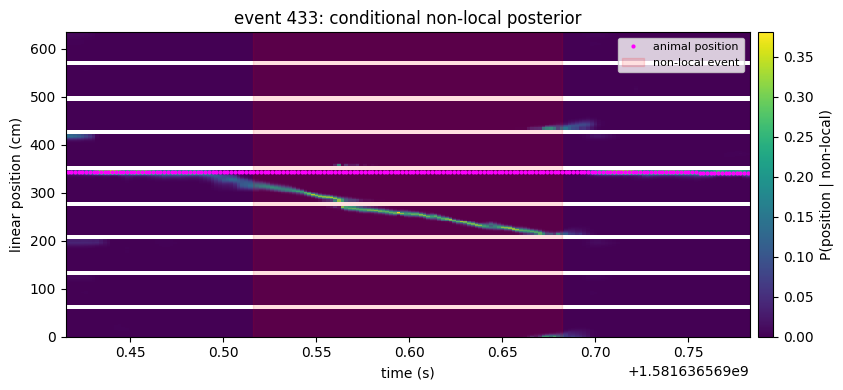

In [9]:
nonlocal_summed = (
    dot["Non-Local_Continuous_prob"] + dot["Non-Local_Fragmented_prob"]
)
# peak non-local prob per event label -> choose the strongest event
peak_per_event = nonlocal_summed.groupby(dot["non_local_event"]).max()
peak_per_event = peak_per_event[peak_per_event.index > 0]
example_label = peak_per_event.idxmax()

ev_mask = dot["non_local_event"] == example_label
ev_times = dot.index[ev_mask]
pad = 0.10  # seconds of context on each side
t0, t1 = ev_times.min() - pad, ev_times.max() + pad

post_win = posterior.sel(time=slice(t0, t1)).load()
pos_win = dot.loc[t0:t1, "linear_position"]

fig, ax = plt.subplots(figsize=(9, 4))
mesh = ax.pcolormesh(
    post_win["time"].values,
    post_win["position"].values,
    post_win.values.T,
    cmap="viridis",
    shading="auto",
    rasterized=True,
)
ax.plot(pos_win.index, pos_win.values, ".", color="magenta", ms=4,
        label="animal position")
ax.axvspan(ev_times.min(), ev_times.max(), color="red", alpha=0.12,
           label="non-local event")
ax.set(xlabel="time (s)", ylabel="linear position (cm)",
       title=f"event {int(example_label)}: conditional non-local posterior")
ax.legend(loc="upper right", fontsize=8)
fig.colorbar(mesh, ax=ax, label="P(position | non-local)", pad=0.01)
fig.tight_layout()

## 3. Stop table (the denominator is built first)

`build_stop_table` produces **one row per stopping period** (immobility
bout), including zero-event stops. The canonical driver builds this table
before touching the event table so a zero-event session still contributes its
full exposure denominator to the rate models.

In [10]:
stop_table = build_stop_table(dot, trials, track_graph)
print("stop_table:", stop_table.shape)
print(
    "stops with >=1 event:",
    int((stop_table["n_non_local"] > 0).sum()),
    "/",
    len(stop_table),
)
print("zero-duration stops:", int((stop_table["immobility_time"] <= 0).sum()))
stop_table.head()

stop_table: (2239, 39)
stops with >=1 event: 485 / 2239
zero-duration stops: 1


,animal,day,epoch,stop_idx,stop_id,stop_start,stop_end,immobility_time,reward_rate_trial_k10,is_swr_stop,n_SWR,is_mua_stop,n_MUA,has_replay,n_events,n_non_local,is_after_switch,is_after_omission,is_after_reward,is_after_stay,reward_outcome,is_stay,current_arm,prev_arm,next_arm,last_rewarded_arm,current_patch,prev_patch,next_patch,reward_lag1,reward_lag2,reward_lag3,reward_lag4,reward_lag5,reward_lag6,reward_lag7,reward_lag8,reward_lag9,reward_lag10
0,chimi,20200213,02_r1,0,8393993873049741010,1.581636e+09,1.581636e+09,1.923999,NaN,False,0,False,0,True,4,4,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,chimi,20200213,02_r1,1,4684575748763187657,1.581636e+09,1.581636e+09,3.577998,NaN,True,1,True,1,True,4,4,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chimi,20200213,02_r1,2,507077526136763520,1.581636e+09,1.581636e+09,1.227999,NaN,False,0,False,0,True,5,5,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,chimi,20200213,02_r1,3,1227836852711955074,1.581636e+09,1.581636e+09,0.696000,NaN,False,0,False,0,True,2,2,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,chimi,20200213,02_r1,4,7289660146915800854,1.581636e+09,1.581636e+09,0.104000,NaN,False,0,False,0,False,0,0,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Text(0, 0.5, 'Non-local prob')

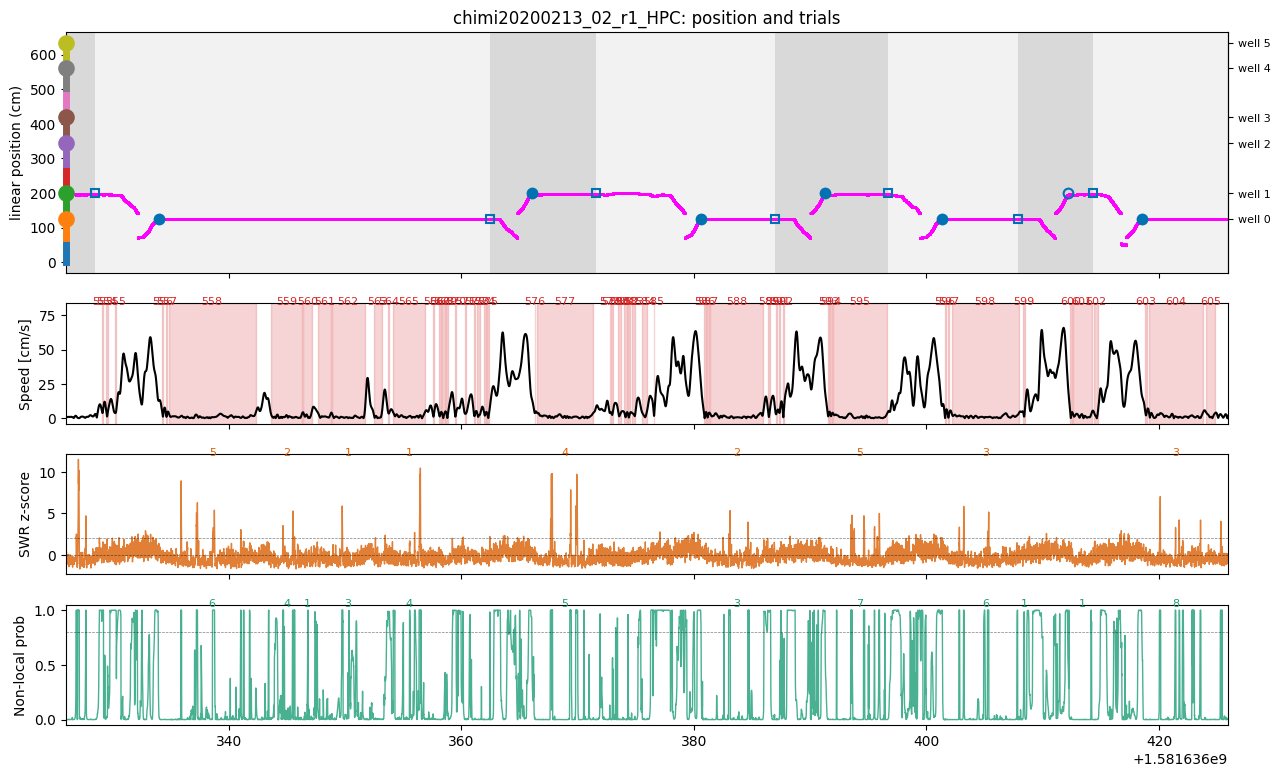

In [11]:
# check that trials make sense
from matplotlib.patches import Patch
from continuum_swr_replay.visualization.palettes import COLORS

from continuum_swr_replay.data_loaders import WELL_PATCH_MAPPING
from continuum_swr_replay.visualization import plot_graph_as_1D

t_start = float(position_info.index[0]) + 750.0
t_stop = t_start + 100.0

# Linear position of each degree-1 node (well), mirroring the cumulative
# arithmetic in plot_graph_as_1D so markers land on the same y axis.
spacing = (
    [float(linear_edge_spacing)] * (len(linear_edge_order) - 1)
    if np.isscalar(linear_edge_spacing)
    else list(linear_edge_spacing)
)
well_linear = {}
edge_start = 0.0
for i, (u, v) in enumerate(np.asarray(linear_edge_order)):
    edge_end = edge_start + track_graph.edges[u, v]["distance"]
    if track_graph.degree(u) == 1:
        well_linear[int(u)] = edge_start
    if track_graph.degree(v) == 1:
        well_linear[int(v)] = edge_end
    edge_start = edge_end + (spacing[i] if i < len(spacing) else 0.0)

PATCH_COLORS = {1: "#0072B2", 2: "#D55E00", 3: "#009E73"}  # Okabe-Ito

fig, axs = plt.subplots(4, 1, figsize=(15, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1, 1]})

ax = axs[0]

# spreadsheet-style alternating gray bands, one per trial
for row, (_, trial) in enumerate(trials.iterrows()):
    ax.axvspan(
        trial["movement_start_time"], trial["end_time"],
        color="0.85" if row % 2 else "0.95", linewidth=0, zorder=0,
    )

ax.scatter(
    position_info.index, position_info["linear_position"],
    s=1, color="magenta", rasterized=True, zorder=2,
)

blend = ax.get_xaxis_transform()
for _, trial in trials.iterrows():
    from_well, to_well = int(trial["from_well"]), int(trial["to_well"])
    # departure: open square at from_well, colored by from_patch
    ax.plot(
        trial["movement_start_time"], well_linear[from_well],
        marker="s", ms=6, mfc="none",
        mec=PATCH_COLORS[WELL_PATCH_MAPPING[from_well]], mew=1.5, zorder=4,
    )
    # arrival: circle at destination_first_poke_in_time, filled iff rewarded
    dest_color = PATCH_COLORS[WELL_PATCH_MAPPING[to_well]]
    ax.plot(
        trial["destination_first_poke_in_time"], well_linear[to_well],
        marker="o", ms=7,
        mfc=dest_color if trial["is_reward"] else "none",
        mec=dest_color, mew=1.5, zorder=4,
    )
    if trial["is_patch_change"]:
        ax.plot(
            trial["movement_start_time"], 0.97, marker="v", ms=6, color="black",
            transform=blend, zorder=5,
        )

ax.set(
    xlabel="time (s)", ylabel="linear position (cm)",
    title=f"{SESSION_ID}: position and trials", xlim=(t_start, t_stop),
)
well_axis = ax.secondary_yaxis("right")
well_axis.set_yticks([well_linear[w] for w in sorted(well_linear)])
well_axis.set_yticklabels([f"well {w}" for w in sorted(well_linear)], fontsize=8)


def _marker(marker, filled, label, color="0.35"):
    """Neutral-gray proxy handle — real markers are colored by patch."""
    return Line2D(
        [], [], linestyle="none", marker=marker, ms=7,
        mfc=color if filled else "none", mec=color, mew=1.5, label=label,
    )


legend_handles = [
    Line2D([], [], linestyle="none", marker="o", ms=4, color="magenta",
           label="linear position"),
    Patch(facecolor="0.85", edgecolor="none", label="trial (alternating)"),
    _marker("s", False, "departure (from_well)"),
    _marker("o", True, "arrival, rewarded"),
    _marker("o", False, "arrival, unrewarded"),
    _marker("v", True, "patch change", color="black"),
] + [
    Patch(facecolor=PATCH_COLORS[p], edgecolor="none", label=f"patch {p}")
    for p in sorted(PATCH_COLORS)
]
ax.legend(
    handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.28),
    ncol=5, fontsize=8, frameon=False, handletextpad=0.5, columnspacing=1.5,
)

reward_well_nodes = [n for n in track_graph.nodes if track_graph.degree(n) == 1]
plot_graph_as_1D(
    track_graph, ax=ax,
    edge_order=linear_edge_order, edge_spacing=linear_edge_spacing,
    reward_well_nodes=reward_well_nodes,
    other_axis_start=t_start,
    reward_well_size=120, edge_linewidth=5,
)



axs[1].plot(
    position_info.index, position_info["head_speed"],
    color="black", rasterized=True, zorder=2,
)
axs[1].set_ylabel("Speed [cm/s]")
for _, stop in stop_table.loc[(stop_table.stop_start >= t_start) & (stop_table.stop_end <= t_stop)].iterrows():
    axs[1].axvspan(
        stop.stop_start, stop.stop_end,
        color="C3", alpha=0.2, zorder=1
    )
    axs[1].text(stop.stop_start + 0.5 * (stop.stop_end - stop.stop_start), 1.05, f"{int(stop.stop_idx)}",
                color="C3", fontsize=8, ha="center", va="top", transform=axs[1].get_xaxis_transform(), zorder=3)
    if stop.n_SWR > 0:
        axs[2].text(stop.stop_start + 0.5 * (stop.stop_end - stop.stop_start), 1.05, f"{int(stop.n_SWR)}",
                    color=COLORS["SWR"], fontsize=8, ha="center", va="top", transform=axs[2].get_xaxis_transform(), zorder=3)
    if stop.n_non_local > 0:
        axs[3].text(stop.stop_start + 0.5 * (stop.stop_end - stop.stop_start), 1.05, f"{int(stop.n_non_local)}",
                    color=COLORS["Non-Local"], fontsize=8, ha="center", va="top", transform=axs[3].get_xaxis_transform(), zorder=3)

dot.loc[t_start:t_stop, "SWR_zscore"].plot(
    ax=axs[2], linewidth=1, alpha=0.8, rasterized=True, color=COLORS["SWR"], zorder=2
)
axs[2].set_ylabel("SWR z-score")
axs[2].axhline(0, color="black", linewidth=0.5, alpha=0.5, zorder=3, linestyle="--")
axs[2].axhline(2.0, color="black", linewidth=0.5, alpha=0.5, zorder=3, linestyle="--")

dot.loc[t_start:t_stop, [ "Non-Local_Continuous_prob", "Non-Local_Fragmented_prob"]].sum(axis=1).plot(
    ax=axs[3], linewidth=1, alpha=0.8, rasterized=True, color=COLORS["Non-Local"], zorder=2
)
axs[3].axhline(0.8, color="black", linewidth=0.5, alpha=0.5, zorder=3, linestyle="--")
axs[3].set_ylabel("Non-local prob")

Text(0, 0.5, 'Non-local prob')

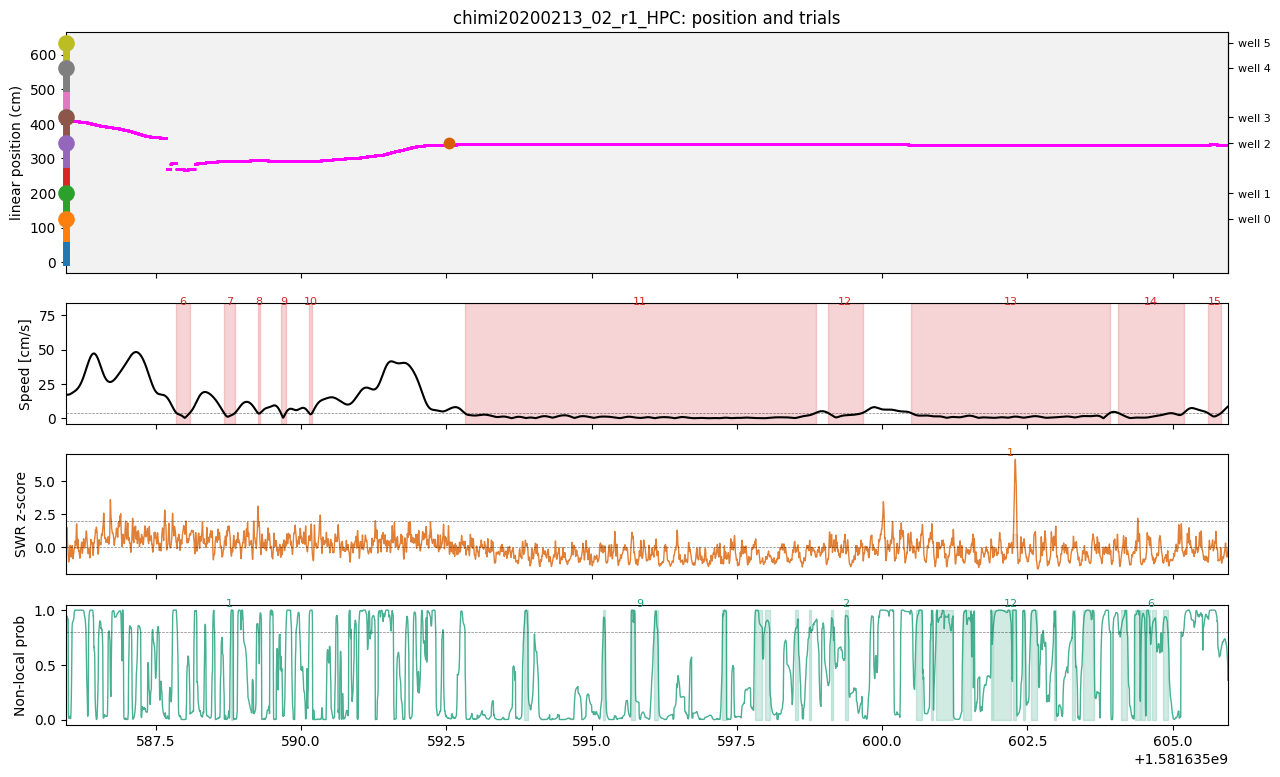

In [12]:
# check that trials make sense
from matplotlib.patches import Patch
from continuum_swr_replay.visualization.palettes import COLORS

from continuum_swr_replay.data_loaders import WELL_PATCH_MAPPING
from continuum_swr_replay.visualization import plot_graph_as_1D

t_start = float(position_info.index[0]) + 10.0
t_stop = t_start + 20.0

# Linear position of each degree-1 node (well), mirroring the cumulative
# arithmetic in plot_graph_as_1D so markers land on the same y axis.
spacing = (
    [float(linear_edge_spacing)] * (len(linear_edge_order) - 1)
    if np.isscalar(linear_edge_spacing)
    else list(linear_edge_spacing)
)
well_linear = {}
edge_start = 0.0
for i, (u, v) in enumerate(np.asarray(linear_edge_order)):
    edge_end = edge_start + track_graph.edges[u, v]["distance"]
    if track_graph.degree(u) == 1:
        well_linear[int(u)] = edge_start
    if track_graph.degree(v) == 1:
        well_linear[int(v)] = edge_end
    edge_start = edge_end + (spacing[i] if i < len(spacing) else 0.0)

PATCH_COLORS = {1: "#0072B2", 2: "#D55E00", 3: "#009E73"}  # Okabe-Ito

fig, axs = plt.subplots(4, 1, figsize=(15, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1, 1]})

ax = axs[0]

# spreadsheet-style alternating gray bands, one per trial
for row, (_, trial) in enumerate(trials.iterrows()):
    ax.axvspan(
        trial["movement_start_time"], trial["end_time"],
        color="0.85" if row % 2 else "0.95", linewidth=0, zorder=0,
    )

ax.scatter(
    position_info.index, position_info["linear_position"],
    s=1, color="magenta", rasterized=True, zorder=2,
)

blend = ax.get_xaxis_transform()
for _, trial in trials.iterrows():
    from_well, to_well = int(trial["from_well"]), int(trial["to_well"])
    # departure: open square at from_well, colored by from_patch
    ax.plot(
        trial["movement_start_time"], well_linear[from_well],
        marker="s", ms=6, mfc="none",
        mec=PATCH_COLORS[WELL_PATCH_MAPPING[from_well]], mew=1.5, zorder=4,
    )
    # arrival: circle at destination_first_poke_in_time, filled iff rewarded
    dest_color = PATCH_COLORS[WELL_PATCH_MAPPING[to_well]]
    ax.plot(
        trial["destination_first_poke_in_time"], well_linear[to_well],
        marker="o", ms=7,
        mfc=dest_color if trial["is_reward"] else "none",
        mec=dest_color, mew=1.5, zorder=4,
    )
    if trial["is_patch_change"]:
        ax.plot(
            trial["movement_start_time"], 0.97, marker="v", ms=6, color="black",
            transform=blend, zorder=5,
        )

ax.set(
    xlabel="time (s)", ylabel="linear position (cm)",
    title=f"{SESSION_ID}: position and trials", xlim=(t_start, t_stop),
)
well_axis = ax.secondary_yaxis("right")
well_axis.set_yticks([well_linear[w] for w in sorted(well_linear)])
well_axis.set_yticklabels([f"well {w}" for w in sorted(well_linear)], fontsize=8)


def _marker(marker, filled, label, color="0.35"):
    """Neutral-gray proxy handle — real markers are colored by patch."""
    return Line2D(
        [], [], linestyle="none", marker=marker, ms=7,
        mfc=color if filled else "none", mec=color, mew=1.5, label=label,
    )


legend_handles = [
    Line2D([], [], linestyle="none", marker="o", ms=4, color="magenta",
           label="linear position"),
    Patch(facecolor="0.85", edgecolor="none", label="trial (alternating)"),
    _marker("s", False, "departure (from_well)"),
    _marker("o", True, "arrival, rewarded"),
    _marker("o", False, "arrival, unrewarded"),
    _marker("v", True, "patch change", color="black"),
] + [
    Patch(facecolor=PATCH_COLORS[p], edgecolor="none", label=f"patch {p}")
    for p in sorted(PATCH_COLORS)
]
ax.legend(
    handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.28),
    ncol=5, fontsize=8, frameon=False, handletextpad=0.5, columnspacing=1.5,
)

reward_well_nodes = [n for n in track_graph.nodes if track_graph.degree(n) == 1]
plot_graph_as_1D(
    track_graph, ax=ax,
    edge_order=linear_edge_order, edge_spacing=linear_edge_spacing,
    reward_well_nodes=reward_well_nodes,
    other_axis_start=t_start,
    reward_well_size=120, edge_linewidth=5,
)



axs[1].plot(
    position_info.index, position_info["head_speed"],
    color="black", rasterized=True, zorder=2,
)
axs[1].axhline(4.0, color="black", linewidth=0.5, alpha=0.5, zorder=3, linestyle="--")
axs[1].set_ylabel("Speed [cm/s]")
for _, stop in stop_table.loc[(stop_table.stop_start >= t_start) & (stop_table.stop_end <= t_stop)].iterrows():
    axs[1].axvspan(
        stop.stop_start, stop.stop_end,
        color="C3", alpha=0.2, zorder=1
    )
    axs[1].text(stop.stop_start + 0.5 * (stop.stop_end - stop.stop_start), 1.05, f"{int(stop.stop_idx)}",
                color="C3", fontsize=8, ha="center", va="top", transform=axs[1].get_xaxis_transform(), zorder=3)
    if stop.n_SWR > 0:
        axs[2].text(stop.stop_start + 0.5 * (stop.stop_end - stop.stop_start), 1.05, f"{int(stop.n_SWR)}",
                    color=COLORS["SWR"], fontsize=8, ha="center", va="top", transform=axs[2].get_xaxis_transform(), zorder=3)
    if stop.n_non_local > 0:
        axs[3].text(stop.stop_start + 0.5 * (stop.stop_end - stop.stop_start), 1.05, f"{int(stop.n_non_local)}",
                    color=COLORS["Non-Local"], fontsize=8, ha="center", va="top", transform=axs[3].get_xaxis_transform(), zorder=3)

dot.loc[t_start:t_stop, "SWR_zscore"].plot(
    ax=axs[2], linewidth=1, alpha=0.8, rasterized=True, color=COLORS["SWR"], zorder=2
)
axs[2].fill_between(
    dot.loc[t_start:t_stop].index,
    dot.loc[t_start:t_stop, "SWR_event"] > 0,
    where=dot.loc[t_start:t_stop, "SWR_event"] > 0,
    color=COLORS["SWR"], alpha=0.2, zorder=1
)

axs[2].set_ylabel("SWR z-score")
axs[2].axhline(0, color="black", linewidth=0.5, alpha=0.5, zorder=3, linestyle="--")
axs[2].axhline(2.0, color="black", linewidth=0.5, alpha=0.5, zorder=3, linestyle="--")

dot.loc[t_start:t_stop, [ "Non-Local_Continuous_prob", "Non-Local_Fragmented_prob"]].sum(axis=1).plot(
    ax=axs[3], linewidth=1, alpha=0.8, rasterized=True, color=COLORS["Non-Local"], zorder=2
)
axs[3].fill_between(
    dot.loc[t_start:t_stop].index,
    dot.loc[t_start:t_stop, "non_local_event"] > 0,
    where=dot.loc[t_start:t_stop, "non_local_event"] > 0,
    color=COLORS["Non-Local"], alpha=0.2, zorder=1
)
axs[3].axhline(0.8, color="black", linewidth=0.5, alpha=0.5, zorder=3, linestyle="--")
axs[3].set_ylabel("Non-local prob")

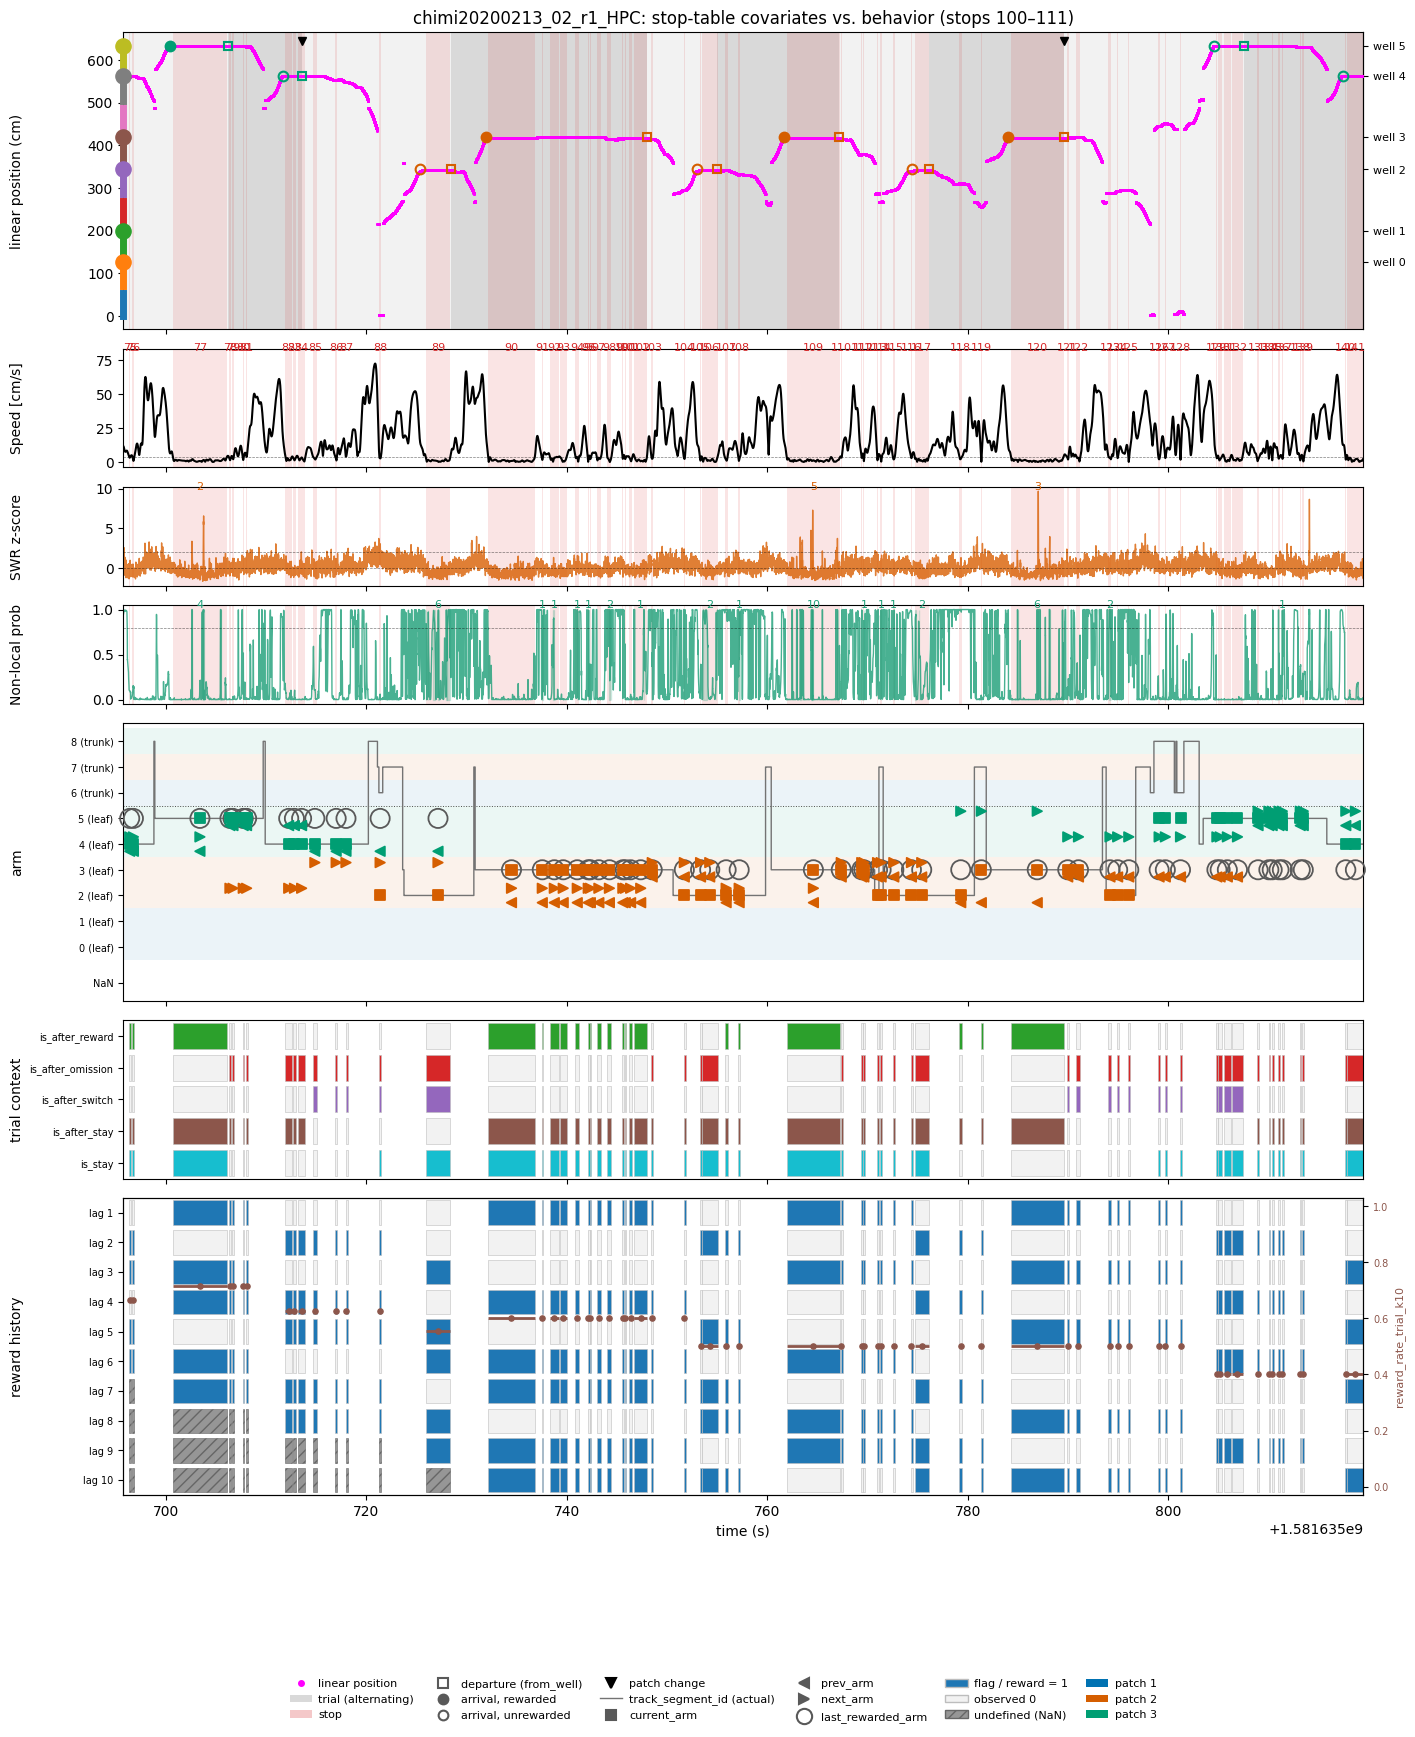

In [13]:
# ── Stop-table diagnostics ───────────────────────────────────────────────
# Every per-stop covariate is drawn on the SAME time axis as the position
# and speed traces, so each stored value can be read against the behavior
# it claims to summarize:
#   * current_arm            must sit on the actual track_segment_id line
#   * next_arm               must match where the position trace goes next
#   * marker color (patch)   must match the arm's patch band
#   * is_after_*             must agree with the arrival markers in panel 1
#   * reward_rate_trial_k10  is exactly nanmean(reward_lag1..10), so the
#                            line must track each lag column's filled fraction
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

from continuum_swr_replay.data_loaders import (
    TRACK_SEGMENT_TO_PATCH,
    WELL_PATCH_MAPPING,
)
from continuum_swr_replay.visualization.palettes import COLORS
from continuum_swr_replay.visualization import plot_graph_as_1D

# ── knobs ────────────────────────────────────────────────────────────────
FIRST_STOP = 100    # index into stop_table (chronological)
N_STOPS = 12      # consecutive stops to display
PAD_S = 50.0       # seconds of context on each side

# Window is anchored on stops, not wall-clock, so N complete stops are always
# in view regardless of how the session is paced.
_sel = stop_table.iloc[FIRST_STOP : FIRST_STOP + N_STOPS]
t_start = float(_sel["stop_start"].iat[0]) - PAD_S
t_stop = float(_sel["stop_end"].iat[-1]) + PAD_S

# Overlap, NOT containment. The old `(start >= t_start) & (end <= t_stop)`
# silently dropped any stop straddling a window edge, so the covariate rows
# disagreed with the speed trace at the margins.
stops = stop_table[
    (stop_table["stop_start"] <= t_stop) & (stop_table["stop_end"] >= t_start)
].sort_values("stop_start", kind="stable")
trials_win = trials[
    (trials["movement_start_time"] <= t_stop) & (trials["end_time"] >= t_start)
]
dot_win = dot.loc[t_start:t_stop]

stop_starts = stops["stop_start"].to_numpy(dtype=float)
stop_ends = stops["stop_end"].to_numpy(dtype=float)
stop_mids = 0.5 * (
    np.maximum(stop_starts, t_start) + np.minimum(stop_ends, t_stop)
)

PATCH_COLORS = {1: "#0072B2", 2: "#D55E00", 3: "#009E73"}  # Okabe-Ito
ZERO_COLOR = "#f2f2f2"     # observed False
MISSING_COLOR = "#969696"  # NaN — must never render as False
MIN_CELL_W = (t_stop - t_start) * 0.0015  # keeps 0-duration stops visible

# Alternating trial shading keyed to the trial's position in the FULL frame,
# so re-windowing never flips the banding.
trial_order = {idx: i for i, idx in enumerate(trials.index)}


def _cells(ax, y, values, true_color, height=0.82):
    """One clipped rectangle per stop: colored=1, pale=0, hatched gray=NaN.

    Zero-duration stops (single-sample immobility bouts, which
    ``build_stop_table`` deliberately keeps) are widened to ``MIN_CELL_W``
    so they cannot silently vanish from the audit.
    """
    for x0, x1, value in zip(stop_starts, stop_ends, values, strict=True):
        x0c, x1c = max(x0, t_start), min(x1, t_stop)
        width = max(x1c - x0c, MIN_CELL_W)
        if np.isnan(value):
            face, edge, hatch = MISSING_COLOR, "#666666", "///"
        else:
            face, edge, hatch = (
                true_color if value else ZERO_COLOR,
                "#bdbdbd",
                None,
            )
        ax.add_patch(
            Rectangle(
                (x0c, y - 0.5 * height), width, height,
                facecolor=face, edgecolor=edge, hatch=hatch,
                linewidth=0.4, zorder=2,
            )
        )


# Linear position of each degree-1 node (well), mirroring the cumulative
# arithmetic in plot_graph_as_1D so markers land on the same y axis.
spacing = (
    [float(linear_edge_spacing)] * (len(linear_edge_order) - 1)
    if np.isscalar(linear_edge_spacing)
    else list(linear_edge_spacing)
)
well_linear = {}
edge_start = 0.0
for i, (u, v) in enumerate(np.asarray(linear_edge_order)):
    edge_end = edge_start + track_graph.edges[u, v]["distance"]
    if track_graph.degree(u) == 1:
        well_linear[int(u)] = edge_start
    if track_graph.degree(v) == 1:
        well_linear[int(v)] = edge_end
    edge_start = edge_end + (spacing[i] if i < len(spacing) else 0.0)

fig, axs = plt.subplots(
    7, 1, figsize=(16, 19), sharex=True,
    gridspec_kw={
        "height_ratios": [3.0, 1.2, 1.0, 1.0, 2.8, 1.6, 3.0],
        "hspace": 0.10,
    },
)

# Stop spans on the trace panels only; the covariate panels below encode
# stops as cells already.
for ax in axs[:4]:
    for x0, x1 in zip(stop_starts, stop_ends, strict=True):
        ax.axvspan(x0, x1, color="C3", alpha=0.12, linewidth=0, zorder=1)

# ── [0] position + trials ────────────────────────────────────────────────
ax = axs[0]
for idx, trial in trials_win.iterrows():
    ax.axvspan(
        trial["movement_start_time"], trial["end_time"],
        color="0.85" if trial_order[idx] % 2 else "0.95",
        linewidth=0, zorder=0,
    )

ax.scatter(
    position_info.index, position_info["linear_position"],
    s=1, color="magenta", rasterized=True, zorder=3,
)

blend = ax.get_xaxis_transform()
for _, trial in trials_win.iterrows():
    from_well, to_well = int(trial["from_well"]), int(trial["to_well"])
    # departure: open square at from_well, colored by from_patch
    ax.plot(
        trial["movement_start_time"], well_linear[from_well],
        marker="s", ms=6, mfc="none",
        mec=PATCH_COLORS[WELL_PATCH_MAPPING[from_well]], mew=1.5, zorder=4,
    )
    # arrival: circle at destination_first_poke_in_time, filled iff rewarded
    dest_color = PATCH_COLORS[WELL_PATCH_MAPPING[to_well]]
    ax.plot(
        trial["destination_first_poke_in_time"], well_linear[to_well],
        marker="o", ms=7,
        mfc=dest_color if trial["is_reward"] else "none",
        mec=dest_color, mew=1.5, zorder=4,
    )
    if trial["is_patch_change"]:
        ax.plot(
            trial["movement_start_time"], 0.97, marker="v", ms=6, color="black",
            transform=blend, zorder=5,
        )

ax.set(
    ylabel="linear position (cm)",
    title=f"{SESSION_ID}: stop-table covariates vs. behavior "
          f"(stops {FIRST_STOP}–{FIRST_STOP + N_STOPS - 1})",
    xlim=(t_start, t_stop),
)
well_axis = ax.secondary_yaxis("right")
well_axis.set_yticks([well_linear[w] for w in sorted(well_linear)])
well_axis.set_yticklabels([f"well {w}" for w in sorted(well_linear)], fontsize=8)

reward_well_nodes = [n for n in track_graph.nodes if track_graph.degree(n) == 1]
plot_graph_as_1D(
    track_graph, ax=ax,
    edge_order=linear_edge_order, edge_spacing=linear_edge_spacing,
    reward_well_nodes=reward_well_nodes,
    other_axis_start=t_start,
    reward_well_size=120, edge_linewidth=5,
)

# ── [1] speed, with stop_idx / n_SWR / n_non_local labels ────────────────
axs[1].plot(
    position_info.index, position_info["head_speed"],
    color="black", rasterized=True, zorder=2,
)
axs[1].axhline(4.0, color="black", linewidth=0.5, alpha=0.5, zorder=3, linestyle="--")
axs[1].set_ylabel("Speed [cm/s]")
for mid, (_, stop) in zip(stop_mids, stops.iterrows(), strict=True):
    axs[1].text(
        mid, 1.05, f"{int(stop.stop_idx)}", color="C3", fontsize=8,
        ha="center", va="top", transform=axs[1].get_xaxis_transform(), zorder=3,
    )
    if stop.n_SWR > 0:
        axs[2].text(
            mid, 1.05, f"{int(stop.n_SWR)}", color=COLORS["SWR"], fontsize=8,
            ha="center", va="top", transform=axs[2].get_xaxis_transform(), zorder=3,
        )
    if stop.n_non_local > 0:
        axs[3].text(
            mid, 1.05, f"{int(stop.n_non_local)}", color=COLORS["Non-Local"],
            fontsize=8, ha="center", va="top",
            transform=axs[3].get_xaxis_transform(), zorder=3,
        )

# ── [2] SWR z-score ──────────────────────────────────────────────────────
dot_win["SWR_zscore"].plot(
    ax=axs[2], linewidth=1, alpha=0.8, rasterized=True,
    color=COLORS["SWR"], zorder=2,
)
axs[2].fill_between(
    dot_win.index, dot_win["SWR_event"] > 0, where=dot_win["SWR_event"] > 0,
    color=COLORS["SWR"], alpha=0.2, zorder=1,
)
axs[2].set_ylabel("SWR z-score")
axs[2].axhline(0, color="black", linewidth=0.5, alpha=0.5, zorder=3, linestyle="--")
axs[2].axhline(2.0, color="black", linewidth=0.5, alpha=0.5, zorder=3, linestyle="--")

# ── [3] non-local probability ────────────────────────────────────────────
dot_win[["Non-Local_Continuous_prob", "Non-Local_Fragmented_prob"]].sum(axis=1).plot(
    ax=axs[3], linewidth=1, alpha=0.8, rasterized=True,
    color=COLORS["Non-Local"], zorder=2,
)
axs[3].fill_between(
    dot_win.index, dot_win["non_local_event"] > 0,
    where=dot_win["non_local_event"] > 0,
    color=COLORS["Non-Local"], alpha=0.2, zorder=1,
)
axs[3].axhline(0.8, color="black", linewidth=0.5, alpha=0.5, zorder=3, linestyle="--")
axs[3].set_ylabel("Non-local prob")

# ── [4] arm context ──────────────────────────────────────────────────────
# The gray step line is the animal's ACTUAL arm from the position pipeline.
# current_arm must land on it during every stop; next_arm must match the arm
# the position trace moves to in panel 0. Marker colors come from the STORED
# *_patch columns, so a marker whose color disagrees with its patch band is a
# current_patch/prev_patch/next_patch bug, not a rendering choice.
ax = axs[4]
for arm, patch in TRACK_SEGMENT_TO_PATCH.items():
    ax.axhspan(
        arm - 0.5, arm + 0.5, color=PATCH_COLORS[patch],
        alpha=0.08, linewidth=0, zorder=0,
    )
ax.axhline(5.5, color="0.3", linewidth=0.7, linestyle=":", zorder=1)  # leaf | trunk
ax.step(
    dot_win.index, dot_win["track_segment_id"], where="post",
    color="0.45", linewidth=1.0, zorder=2,
)

# (column, stored patch column, marker, y-offset, size, filled, zorder)
ARM_ROLES = (
    ("last_rewarded_arm", None, "o", 0.00, 190, False, 3),
    ("prev_arm", "prev_patch", "<", -0.28, 46, True, 4),
    ("next_arm", "next_patch", ">", +0.28, 46, True, 4),
    ("current_arm", "current_patch", "s", 0.00, 52, True, 5),
)
UNDEF_Y = -1.4  # NaN row — an unmarked stop would otherwise read as "no data"
for col, patch_col, marker, dy, size, filled, z in ARM_ROLES:
    vals = stops[col].to_numpy(dtype=float)
    if patch_col is None:
        colors = np.array(["0.35"] * len(vals), dtype=object)
    else:
        pv = stops[patch_col].to_numpy(dtype=float)
        colors = np.array(
            [PATCH_COLORS.get(int(p), "0.35") if np.isfinite(p) else "0.35"
             for p in pv],
            dtype=object,
        )
    ok = np.isfinite(vals)
    for mask, ys in ((ok, vals[ok] + dy if ok.any() else vals[ok]),
                     (~ok, np.full(int((~ok).sum()), UNDEF_Y + dy))):
        if not mask.any():
            continue
        ax.scatter(
            stop_mids[mask], ys, marker=marker, s=size,
            facecolor=list(colors[mask]) if filled else "none",
            edgecolor=list(colors[mask]),
            linewidths=1.3, zorder=z, clip_on=False,
        )

ax.set_yticks([UNDEF_Y, *range(9)])
ax.set_yticklabels(
    ["NaN", *[f"{a} (leaf)" if a <= 5 else f"{a} (trunk)" for a in range(9)]],
    fontsize=7,
)
ax.set_ylim(-2.1, 8.7)
ax.set_ylabel("arm")

# ── [5] trial-context flags ──────────────────────────────────────────────
# NOTE: is_after_* look BACKWARD (previous trial's outcome), but is_stay is
# post-hoc — it is derived from next_patch, i.e. it encodes the animal's
# FUTURE choice. It belongs on the response side of a model, not the
# predictor side; it is shown here only to check its construction.
FLAG_ROWS = (
    ("is_after_reward", "#2ca02c"),
    ("is_after_omission", "#d62728"),
    ("is_after_switch", "#9467bd"),
    ("is_after_stay", "#8c564b"),
    ("is_stay", "#17becf"),
)
ax = axs[5]
for row, (col, color) in enumerate(FLAG_ROWS):
    _cells(ax, row, stops[col].to_numpy(dtype=float), color)
ax.set_yticks(range(len(FLAG_ROWS)))
ax.set_yticklabels([col for col, _ in FLAG_ROWS], fontsize=7)
ax.set_ylim(len(FLAG_ROWS) - 0.5, -0.5)  # first row on top
ax.set_ylabel("trial context")

# ── [6] reward history: lags 1–10 + the k=10 rate ────────────────────────
ax = axs[6]
for lag in range(1, 11):
    _cells(ax, lag - 1, stops[f"reward_lag{lag}"].to_numpy(dtype=float), "#1f77b4")
ax.set_yticks(range(10))
ax.set_yticklabels([f"lag {i}" for i in range(1, 11)], fontsize=7)
ax.set_ylim(9.5, -0.5)
ax.set_ylabel("reward history")
ax.set_xlabel("time (s)")

# reward_rate_trial_k10 and reward_lag1..10 share the same trial-cutoff
# mapping, so the rate is exactly nanmean of the column above it: the brown
# line must track each column's filled fraction. Divergence = misalignment.
rate_ax = ax.twinx()
rate = stops["reward_rate_trial_k10"].to_numpy(dtype=float)
for x0, x1, value in zip(stop_starts, stop_ends, rate, strict=True):
    if np.isnan(value):
        continue
    rate_ax.hlines(
        value, max(x0, t_start), min(x1, t_stop),
        color="#8c564b", linewidth=2.0, zorder=6,
    )
rate_ax.scatter(stop_mids, rate, s=14, color="#8c564b", zorder=7)
rate_ax.set_ylim(-0.03, 1.03)
rate_ax.set_ylabel("reward_rate_trial_k10", color="#8c564b", fontsize=8)
rate_ax.tick_params(axis="y", labelcolor="#8c564b", labelsize=7)

# ── figure-level legend (was colliding with panel 2 under axs[0]) ────────
def _proxy(marker, filled, label, color="0.35", ms=7):
    return Line2D(
        [], [], linestyle="none", marker=marker, ms=ms,
        mfc=color if filled else "none", mec=color, mew=1.5, label=label,
    )


legend_handles = [
    Line2D([], [], linestyle="none", marker="o", ms=4, color="magenta",
           label="linear position"),
    Patch(facecolor="0.85", edgecolor="none", label="trial (alternating)"),
    Patch(facecolor="C3", alpha=0.25, edgecolor="none", label="stop"),
    _proxy("s", False, "departure (from_well)"),
    _proxy("o", True, "arrival, rewarded"),
    _proxy("o", False, "arrival, unrewarded"),
    _proxy("v", True, "patch change", color="black"),
    Line2D([], [], color="0.45", linewidth=1.0, label="track_segment_id (actual)"),
    _proxy("s", True, "current_arm"),
    _proxy("<", True, "prev_arm"),
    _proxy(">", True, "next_arm"),
    _proxy("o", False, "last_rewarded_arm", ms=11),
    Patch(facecolor="#1f77b4", edgecolor="#bdbdbd", label="flag / reward = 1"),
    Patch(facecolor=ZERO_COLOR, edgecolor="#bdbdbd", label="observed 0"),
    Patch(facecolor=MISSING_COLOR, edgecolor="#666666", hatch="///",
          label="undefined (NaN)"),
] + [
    Patch(facecolor=PATCH_COLORS[p], edgecolor="none", label=f"patch {p}")
    for p in sorted(PATCH_COLORS)
]
fig.legend(
    handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, -0.015),
    ncol=6, fontsize=8, frameon=False, handletextpad=0.6, columnspacing=1.6,
)
fig.align_ylabels(axs)


In [14]:
dot.loc[t_start:t_stop, "SWR_event"].unique()

array([ 0,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17])

In [15]:
stop_table.keys()

Index(['animal', 'day', 'epoch', 'stop_idx', 'stop_id', 'stop_start', 'stop_end', 'immobility_time', 'reward_rate_trial_k10', 'is_swr_stop', 'n_SWR',
       'is_mua_stop', 'n_MUA', 'has_replay', 'n_events', 'n_non_local', 'is_after_switch', 'is_after_omission', 'is_after_reward', 'is_after_stay',
       'reward_outcome', 'is_stay', 'current_arm', 'prev_arm', 'next_arm', 'last_rewarded_arm', 'current_patch', 'prev_patch', 'next_patch', 'reward_lag1',
       'reward_lag2', 'reward_lag3', 'reward_lag4', 'reward_lag5', 'reward_lag6', 'reward_lag7', 'reward_lag8', 'reward_lag9', 'reward_lag10'],
      dtype='object')

In [16]:
dot.keys()

Index(['non_local_event', 'SWR_event', 'MUA_event', 'Local_prob', 'No-Spike_prob', 'Non-Local_Continuous_prob', 'Non-Local_Fragmented_prob', 'map_estimate',
       'map_speed', 'ahead_behind_distance', 'hpd', 'max_coverage', 'max_distance', 'max_linear_position', 'theta_phase', 'theta_power_zscore', 'SWR_zscore',
       'MUA_zscore', 'n_non_local', 'n_SWR', 'n_MUA', 'n_non_local_SWR', 'n_non_local_no_SWR', 'n_non_local_MUA', 'n_non_local_no_MUA', 'n_SWR_MUA',
       'n_SWR_no_MUA', 'animal', 'day', 'epoch', 'nwb_file_name', 'head_position_x', 'head_position_y', 'head_orientation', 'head_velocity_x',
       'head_velocity_y', 'head_speed', 'linear_position', 'track_segment_id', 'projected_x_position', 'projected_y_position', 'patch_id', 'step_distance',
       'run_speed_baseline'],
      dtype='object')

## 4. Behavioral-model beliefs: value and uncertainty

The walkthrough consumes the externally fitted `beta_stable_withleaf`
Beta-Bernoulli model; it does not estimate that model here. For each reward
well and trial, the model provides a pre-outcome belief
$\operatorname{Beta}(\alpha,\beta)$:

* nominal value `p_reward_port*` is the experimenter's scheduled $p(R)$;
* learned value `q_port*` is the posterior mean $\alpha/(\alpha+\beta)$;
* uncertainty `betadist_var*` is the posterior variance
  $\alpha\beta/[(\alpha+\beta)^2(\alpha+\beta+1)]$.

The fitted model maintains six independent leaf-specific Beta trackers.
Reward adds evidence to the chosen well's $\alpha$; non-reward adds
depletion-scaled evidence to its $\beta$. Between-trial forgetting pulls all
beliefs toward $\operatorname{Beta}(1,1)$, and the fitted patch/leaf softmax
policy maps the beliefs—together with depletion and choice-bias terms—to
choices. Variance is therefore a **model-derived** uncertainty
measure—not decoder uncertainty or direct confidence—and depends
mathematically on both posterior mean and concentration. In this model,
forgetting also couples it strongly to time since visiting a well.

Row $t$ is the belief **before** trial $t$'s outcome; that outcome first updates
row $t+1$. This makes value and variance safe pre-outcome content covariates.
RPE and value-update columns in the same artifact are post-outcome quantities
and are intentionally not fitted below. The artifact broadcasts a trial's
beliefs to every stop assigned to that trial, so orientation plots first
collapse repeated stop rows back to one row per behavioral trial.

In [17]:
qvals_all = load_contingency(QVALS_FILE)
if qvals_all is None:
    raise FileNotFoundError(
        "the production qvals contingency artifact is required for this walkthrough: "
        f"{QVALS_FILE}"
    )

p_reward_port_cols = [f"p_reward_port{arm}" for arm in range(6)]
q_port_cols = [f"q_port{arm}" for arm in range(6)]
beta_mu_cols = [f"betadist_mu{arm}" for arm in range(1, 7)]
beta_var_cols = [f"betadist_var{arm}" for arm in range(1, 7)]
stem_probability_cols = [f"stem_{stem}_p" for stem in range(1, 4)]
belief_trial_cols = [
    "trial_number_by_epoch",
    "arm",
    "trial_reward",
    "q_chosen",
    *stem_probability_cols,
    *p_reward_port_cols,
    *q_port_cols,
    *beta_mu_cols,
    *beta_var_cols,
]
required_qvals_cols = {"stop_id", "epoch", *belief_trial_cols}
missing_qvals_cols = sorted(required_qvals_cols - set(qvals_all.columns))
if missing_qvals_cols:
    raise ValueError(
        f"qvals_table is missing current behavioral-model columns: {missing_qvals_cols}"
    )
if qvals_all["stop_id"].duplicated().any():
    raise ValueError("qvals_table.stop_id must be globally unique")

qvals_session = qvals_all[
    qvals_all["stop_id"].isin(stop_table["stop_id"])
].copy()
del qvals_all

if qvals_session.empty:
    raise ValueError("no stops in this epoch map to qvals_table")
if not qvals_session["epoch"].astype(str).eq(EPOCH_NAME).all():
    raise ValueError("qvals epoch labels disagree with the selected epoch")
if qvals_session["stop_id"].duplicated().any():
    raise ValueError("selected qvals rows are not unique on stop_id")

trial_constancy = qvals_session.groupby("trial_number_by_epoch")[
    belief_trial_cols[1:]
].nunique(dropna=False)
if not trial_constancy.le(1).all().all():
    bad_cols = trial_constancy.columns[trial_constancy.gt(1).any()].tolist()
    raise ValueError(
        "behavioral beliefs vary across stops assigned to the same trial: "
        f"{bad_cols}"
    )

belief_trials = (
    qvals_session.sort_values("trial_number_by_epoch")
    .drop_duplicates("trial_number_by_epoch")[belief_trial_cols]
    .reset_index(drop=True)
)

chosen_arm = belief_trials["arm"].to_numpy(dtype=int)
if not np.isin(chosen_arm, np.arange(6)).all():
    raise ValueError("behavioral-model chosen arm must be a reward-well arm 0..5")

p_reward_matrix = belief_trials[p_reward_port_cols].to_numpy(dtype=float)
q_matrix = belief_trials[q_port_cols].to_numpy(dtype=float)
uncertainty_matrix = belief_trials[beta_var_cols].to_numpy(dtype=float)
beta_mu_matrix = belief_trials[beta_mu_cols].to_numpy(dtype=float)
row = np.arange(len(belief_trials))

assert np.allclose(
    belief_trials["q_chosen"].to_numpy(dtype=float),
    q_matrix[row, chosen_arm],
    rtol=0,
    atol=1e-12,
)
np.testing.assert_allclose(q_matrix, beta_mu_matrix, rtol=0, atol=1e-12)
assert np.isfinite(p_reward_matrix).all() and np.isfinite(q_matrix).all()
assert np.isfinite(uncertainty_matrix).all()
assert ((0 <= p_reward_matrix) & (p_reward_matrix <= 1)).all()
assert ((0 <= q_matrix) & (q_matrix <= 1)).all()
assert ((0 <= uncertainty_matrix) & (uncertainty_matrix <= 1 / 12 + 1e-12)).all()

stop_qvals_coverage = qvals_session["stop_id"].nunique() / len(stop_table)
print(
    "behavioral beliefs:",
    f"{len(belief_trials)} trials,",
    f"{len(qvals_session)}/{len(stop_table)} stops mapped "
    f"({stop_qvals_coverage:.1%})",
)

behavioral beliefs: 280 trials, 2224/2239 stops mapped (99.3%)


### 4a. Belief trajectories and behavioral orientation

The three panels separate the task schedule, the animal's learned expected
reward, and uncertainty about that expectation. White squares mark the chosen
well; orange circles mark rewarded choices. The chosen-stem diagnostic is an
in-sample orientation check on an externally fitted model, not held-out
validation of this epoch. The Brier/log-loss table (lower is better) checks
immediate-reward calibration of nominal $p$ and learned $q$; it is not a
measure of the fitted choice policy.

chosen-stem top-1=92.5%; mean P(chosen stem)=0.886; valid policy trials=279/280


,mean_predicted_reward,observed_reward_rate,n_trials
q_chosen_quartile,,,
Q1,0.384390,0.357143,70
Q2,0.520127,0.642857,70
Q3,0.633074,0.700000,70
Q4,0.741196,0.657143,70


,Brier_score,log_loss
source,,
nominal p,0.191,0.565
Beta mean q,0.229,0.651


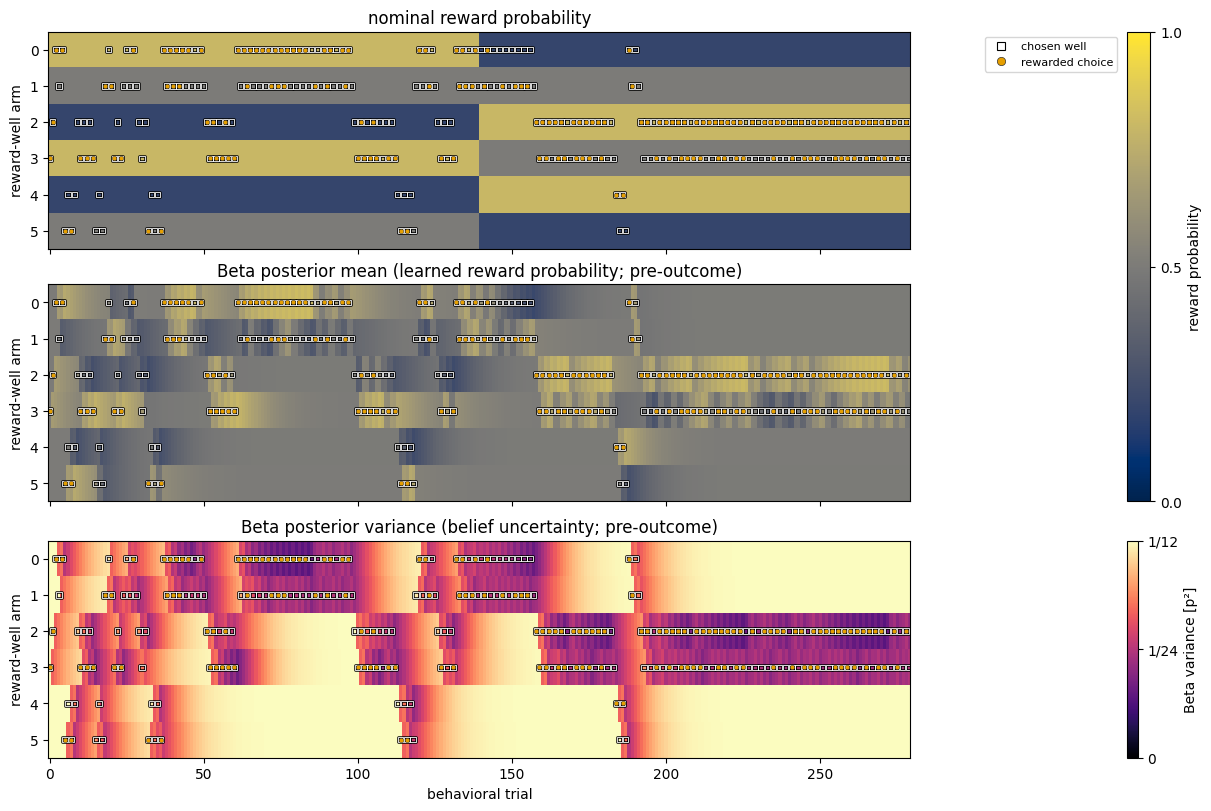

In [18]:
trial_axis = np.arange(len(belief_trials))
rewarded = belief_trials["trial_reward"].to_numpy(dtype=bool)

fig, axes = plt.subplots(
    3, 1, figsize=(12, 8), sharex=True, constrained_layout=True
)
belief_panels = (
    (p_reward_matrix.T, "nominal reward probability", "cividis", 0.0, 1.0),
    (
        q_matrix.T,
        "Beta posterior mean (learned reward probability; pre-outcome)",
        "cividis",
        0.0,
        1.0,
    ),
    (
        uncertainty_matrix.T,
        "Beta posterior variance (belief uncertainty; pre-outcome)",
        "magma",
        0.0,
        1 / 12,
    ),
)
belief_images = []
for ax, (matrix, title, cmap, vmin, vmax) in zip(
    axes, belief_panels, strict=True
):
    image = ax.imshow(
        matrix,
        aspect="auto",
        interpolation="nearest",
        origin="upper",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        rasterized=True,
    )
    belief_images.append(image)
    chosen_markers = ax.scatter(
        trial_axis,
        chosen_arm,
        marker="s",
        s=15,
        facecolors="none",
        edgecolors="white",
        linewidths=0.6,
    )
    chosen_markers.set_path_effects(
        [patheffects.Stroke(linewidth=1.8, foreground="black"), patheffects.Normal()]
    )
    ax.scatter(
        trial_axis[rewarded],
        chosen_arm[rewarded],
        marker="o",
        s=10,
        color="#E69F00",
        edgecolors="0.2",
        linewidths=0.3,
    )
    ax.set(title=title, ylabel="reward-well arm")
    ax.set_yticks(range(6))
fig.colorbar(
    belief_images[0],
    ax=axes[:2],
    label="reward probability",
    ticks=(0.0, 0.5, 1.0),
    pad=0.01,
)
variance_colorbar = fig.colorbar(
    belief_images[2],
    ax=axes[2],
    label="Beta variance [p²]",
    ticks=(0.0, 1 / 24, 1 / 12),
    pad=0.01,
)
variance_colorbar.set_ticks(
    (0.0, 1 / 24, 1 / 12), labels=("0", "1/24", "1/12")
)
belief_legend_handles = (
    Line2D(
        [],
        [],
        marker="s",
        linestyle="none",
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=0.8,
        label="chosen well",
    ),
    Line2D(
        [],
        [],
        marker="o",
        linestyle="none",
        markerfacecolor="#E69F00",
        markeredgecolor="0.2",
        markeredgewidth=0.5,
        label="rewarded choice",
    ),
)
axes[0].legend(
    handles=belief_legend_handles,
    loc="upper left",
    bbox_to_anchor=(1.08, 1),
    fontsize=8,
)
axes[-1].set_xlabel("behavioral trial")

stem_probabilities = belief_trials[stem_probability_cols].to_numpy(dtype=float)
valid_stem_probability = (
    np.isfinite(stem_probabilities).all(axis=1)
    & ((0 <= stem_probabilities) & (stem_probabilities <= 1)).all(axis=1)
    & np.isclose(stem_probabilities.sum(axis=1), 1.0, rtol=0, atol=1e-10)
)
if not valid_stem_probability.any():
    raise ValueError("no trials carry a valid three-stem policy distribution")
chosen_stem = chosen_arm // 2
stem_top1 = np.mean(
    np.argmax(stem_probabilities[valid_stem_probability], axis=1)
    == chosen_stem[valid_stem_probability]
)
mean_chosen_stem_probability = np.mean(
    stem_probabilities[
        row[valid_stem_probability], chosen_stem[valid_stem_probability]
    ]
)

q_midpoint_ecdf = (
    belief_trials["q_chosen"].rank(method="average") - 0.5
) / len(belief_trials)
belief_trials["q_chosen_quartile"] = pd.cut(
    q_midpoint_ecdf,
    bins=np.linspace(0, 1, 5),
    labels=["Q1", "Q2", "Q3", "Q4"],
    include_lowest=True,
)
reward_calibration = belief_trials.groupby(
    "q_chosen_quartile", observed=True
).agg(
    mean_predicted_reward=("q_chosen", "mean"),
    observed_reward_rate=("trial_reward", "mean"),
    n_trials=("trial_reward", "size"),
)
outcome = belief_trials["trial_reward"].to_numpy(dtype=float)
p_chosen = p_reward_matrix[row, chosen_arm]
q_chosen = q_matrix[row, chosen_arm]
calibration_metrics = []
for source, predicted in (("nominal p", p_chosen), ("Beta mean q", q_chosen)):
    clipped = np.clip(predicted, 1e-12, 1 - 1e-12)
    calibration_metrics.append(
        {
            "source": source,
            "Brier_score": np.mean((predicted - outcome) ** 2),
            "log_loss": -np.mean(
                outcome * np.log(clipped) + (1 - outcome) * np.log(1 - clipped)
            ),
        }
    )
print(
    f"chosen-stem top-1={stem_top1:.1%}; "
    f"mean P(chosen stem)={mean_chosen_stem_probability:.3f}; "
    f"valid policy trials={valid_stem_probability.sum()}/{len(belief_trials)}"
)
display(reward_calibration)  # noqa: F821
display(pd.DataFrame(calibration_metrics).set_index("source").round(3))  # noqa: F821

stops=2239, with belief=2224 (99.3%); production q_arm matches the section-4a q_port matrix


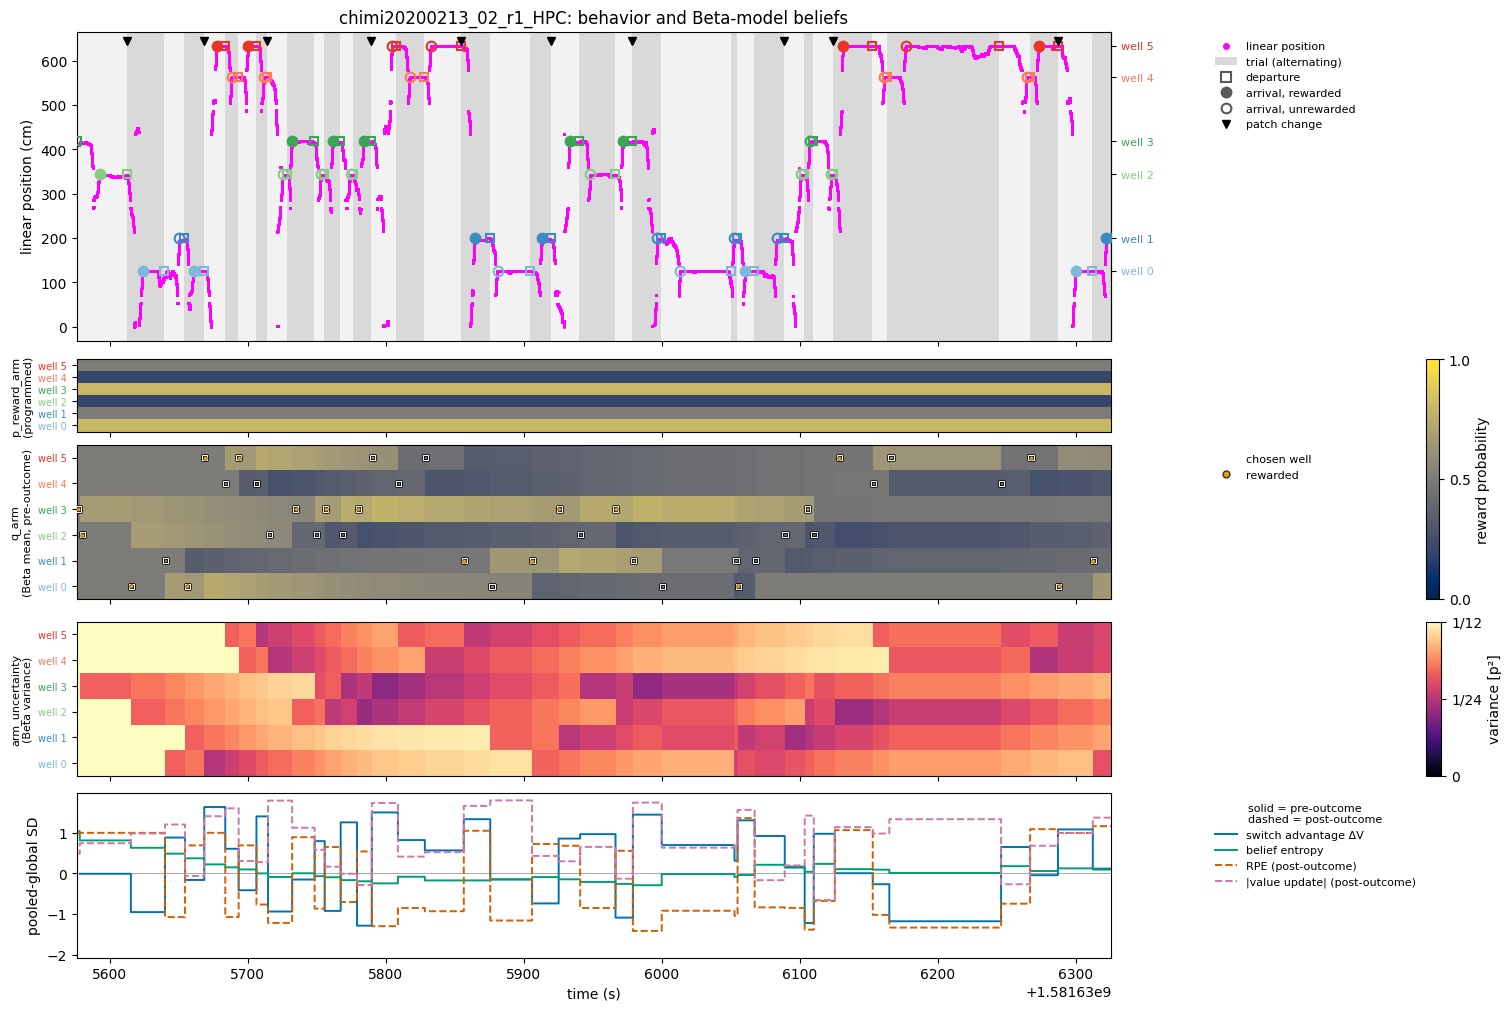

In [19]:
# Beliefs on the wall clock, aligned to the behavior panel.
from matplotlib.patches import Patch

t_start = float(position_info.index[0])
t_stop = t_start + 750.0

from continuum_swr_replay.analysis.behavior.covariates import (
    attach_arm_uncertainty,
    attach_contingency_value_block,
)
from continuum_swr_replay.visualization.palettes import patch_grouped_arm_palette

WELL_COLORS = {w: c for w, c in patch_grouped_arm_palette().items() if w < 6}
TRIAL_SCALARS = (
    ("switch_advantage_mu_preoutcome_sess_z", "switch advantage ΔV", "-", "#0072B2"),
    ("beta_reward_entropy_z", "belief entropy", "-", "#009E73"),
    ("rpe_z", "RPE (post-outcome)", "--", "#D55E00"),
    ("global_mu_update_abs_postoutcome_sess_z", "|value update| (post-outcome)",
     "--", "#CC79A7"),
)

# Every belief value below is produced by the SAME builders that populate the
# fitted event-arm design matrix (arm_patch_tables.build_event_arm_table), keyed on stop_id --
# never on trial number, whose origin differs by animal.
stops = (
    stop_table[["stop_id", "stop_start", "stop_end"]]
    .sort_values("stop_start").reset_index(drop=True)
)
n_stops = len(stops)
arm_long = np.tile(np.arange(6), n_stops)
stop_id_long = np.repeat(stops["stop_id"].to_numpy(), 6)
p_reward_arm, q_arm = attach_contingency_value_block(
    arm_long, stop_id_long, qvals_session
)
arm_uncertainty = attach_arm_uncertainty(arm_long, stop_id_long, qvals_session)
p_reward_stop = p_reward_arm.reshape(n_stops, 6)
q_stop = q_arm.reshape(n_stops, 6)
uncertainty_stop = arm_uncertainty.reshape(n_stops, 6)

# Same one-to-one stop join build_trial_leaf_table performs.
scalar_cols = [col for col, *_ in TRIAL_SCALARS]
stop_scalars = stops.merge(
    qvals_session[["stop_id", *scalar_cols]],
    on="stop_id", how="left", validate="one_to_one",
).sort_values("stop_start").reset_index(drop=True)
chosen_arm_stop = stops.merge(
    qvals_session[["stop_id", "arm", "trial_reward", "trial_number_by_epoch"]],
    on="stop_id", how="left", validate="one_to_one",
)

# Cell edges: each stop's belief is held from its start to the next stop's
# start, so pcolormesh draws exact steps with no interpolation.
step_x = np.append(
    stops["stop_start"].to_numpy(dtype=float), float(stops["stop_end"].iloc[-1])
)
if not np.all(np.diff(step_x) > 0):
    raise ValueError("stop_start must be strictly increasing to step-hold belief")
well_edges = np.arange(7)
stop_mid = 0.5 * (step_x[:-1] + step_x[1:])


def _heat(ax, values, cmap, vmin, vmax):
    """Belief as wells x time; row order matches the behavior panel's well axis."""
    return ax.pcolormesh(step_x, well_edges, values.T, cmap=cmap, vmin=vmin,
                         vmax=vmax, shading="flat", rasterized=True)


def _well_axis(ax):
    ax.set_yticks(np.arange(6) + 0.5, labels=[f"well {w}" for w in range(6)],
                  fontsize=7)
    for tick, well in zip(ax.get_yticklabels(), range(6), strict=True):
        tick.set_color(WELL_COLORS[well])


fig, axes = plt.subplots(
    5, 1, figsize=(15, 10), sharex=True,
    height_ratios=[3.0, 0.7, 1.5, 1.5, 1.6], constrained_layout=True,
)

# ---- panel 1: position + trials ------------------------------------------
ax = axes[0]
for row_i, (_, trial) in enumerate(trials.iterrows()):
    ax.axvspan(trial["movement_start_time"], trial["end_time"],
               color="0.85" if row_i % 2 else "0.95", linewidth=0, zorder=0)
ax.scatter(position_info.index, position_info["linear_position"], s=1,
           color="magenta", rasterized=True, zorder=2)
blend = ax.get_xaxis_transform()
for _, trial in trials.iterrows():
    from_well, to_well = int(trial["from_well"]), int(trial["to_well"])
    ax.plot(trial["movement_start_time"], well_linear[from_well], marker="s", ms=6,
            mfc="none", mec=WELL_COLORS[from_well], mew=1.5, zorder=4)
    ax.plot(trial["destination_first_poke_in_time"], well_linear[to_well], marker="o", ms=7,
            mfc=WELL_COLORS[to_well] if trial["is_reward"] else "none",
            mec=WELL_COLORS[to_well], mew=1.5, zorder=4)
    if trial["is_patch_change"]:
        ax.plot(trial["movement_start_time"], 0.97, marker="v", ms=6, color="black",
                transform=blend, zorder=5)
ax.set(ylabel="linear position (cm)",
       title=f"{SESSION_ID}: behavior and Beta-model beliefs")
well_axis = ax.secondary_yaxis("right")
well_axis.set_yticks([well_linear[w] for w in sorted(well_linear)])
well_axis.set_yticklabels([f"well {w}" for w in sorted(well_linear)], fontsize=8)
for tick, well in zip(well_axis.get_yticklabels(), sorted(well_linear), strict=True):
    tick.set_color(WELL_COLORS[well])
ax.legend(handles=[
    Line2D([], [], ls="none", marker="o", ms=4, color="magenta", label="linear position"),
    Patch(facecolor="0.85", edgecolor="none", label="trial (alternating)"),
    Line2D([], [], ls="none", marker="s", ms=7, mfc="none", mec="0.35", mew=1.5, label="departure"),
    Line2D([], [], ls="none", marker="o", ms=7, mfc="0.35", mec="0.35", mew=1.5, label="arrival, rewarded"),
    Line2D([], [], ls="none", marker="o", ms=7, mfc="none", mec="0.35", mew=1.5, label="arrival, unrewarded"),
    Line2D([], [], ls="none", marker="v", ms=6, color="black", label="patch change"),
], loc="upper left", bbox_to_anchor=(1.09, 1.0), fontsize=8, frameon=False)

# ---- panel 2: programmed schedule (thin reference strip) ------------------
mesh_p = _heat(axes[1], p_reward_stop, "cividis", 0.0, 1.0)
_well_axis(axes[1])
axes[1].set_ylabel("p_reward_arm\n(programmed)", fontsize=8)

# ---- panel 3: learned value ----------------------------------------------
ax = axes[2]
mesh_q = _heat(ax, q_stop, "cividis", 0.0, 1.0)
_well_axis(ax)
ax.set_ylabel("q_arm\n(Beta mean, pre-outcome)", fontsize=8)
# Chosen well, ONE marker per behavioral trial (a trial spans several stops),
# ringed so it reads against either end of the colormap.
choice_marks = (
    chosen_arm_stop.assign(stop_mid=stop_mid)
    .dropna(subset=["arm", "trial_number_by_epoch"])
    .drop_duplicates("trial_number_by_epoch")
)
chosen = choice_marks["arm"].to_numpy(dtype=float) + 0.5
marks = ax.scatter(choice_marks["stop_mid"], chosen, marker="s", s=14,
                   facecolors="none", edgecolors="white", linewidths=0.7, zorder=3)
marks.set_path_effects([patheffects.Stroke(linewidth=1.8, foreground="black"),
                        patheffects.Normal()])
rewarded = choice_marks["trial_reward"].to_numpy() == 1
ax.scatter(choice_marks["stop_mid"][rewarded], chosen[rewarded], marker="o", s=8,
           color="#E69F00", edgecolors="0.2", linewidths=0.3, zorder=4)

# ---- panel 4: belief uncertainty -----------------------------------------
mesh_u = _heat(axes[3], uncertainty_stop, "magma", 0.0, 1 / 12)
_well_axis(axes[3])
axes[3].set_ylabel("arm_uncertainty\n(Beta variance)", fontsize=8)

# ---- panel 5: trial-grain scalars ----------------------------------------
ax = axes[4]
for col, label, ls, color in TRIAL_SCALARS:
    values = stop_scalars[col].to_numpy(dtype=float)
    ax.step(step_x, np.append(values, values[-1]), where="post",
            color=color, ls=ls, lw=1.4, label=label)
ax.axhline(0.0, color="0.6", lw=0.6, zorder=0)
ax.set(ylabel="pooled-global SD", xlabel="time (s)", xlim=(t_start, t_stop))
ax.legend(loc="upper left", bbox_to_anchor=(1.09, 1.0), fontsize=8, frameon=False,
          title="solid = pre-outcome\ndashed = post-outcome", title_fontsize=8)

fig.colorbar(mesh_q, ax=[axes[1], axes[2]], label="reward probability",
             ticks=(0, 0.5, 1), pad=0.005, aspect=18)
cbar_u = fig.colorbar(mesh_u, ax=axes[3], label="variance [p²]",
                      ticks=(0, 1 / 24, 1 / 12), pad=0.005, aspect=10)
cbar_u.set_ticks((0, 1 / 24, 1 / 12), labels=("0", "1/24", "1/12"))
axes[2].legend(handles=[
    Line2D([], [], ls="none", marker="s", ms=6, mfc="none", mec="white", mew=1.0,
           label="chosen well"),
    Line2D([], [], ls="none", marker="o", ms=5, mfc="#E69F00", mec="0.2",
           label="rewarded"),
], loc="upper left", bbox_to_anchor=(1.09, 1.0), fontsize=8, frameon=False)

# ---- the production path must reproduce the section-4a belief table -------
mapped = stops["stop_id"].isin(qvals_session["stop_id"]).to_numpy()
stop_trial = stops.merge(
    qvals_session[["stop_id", "trial_number_by_epoch"]], on="stop_id", how="left"
)["trial_number_by_epoch"].to_numpy()
trial_row = pd.Index(belief_trials["trial_number_by_epoch"]).get_indexer(
    stop_trial[mapped]
)
np.testing.assert_allclose(q_stop[mapped], q_matrix[trial_row], rtol=0, atol=1e-12)
print(f"stops={n_stops}, with belief={int(mapped.sum())} ({mapped.mean():.1%}); "
      "production q_arm matches the section-4a q_port matrix")


stops=2239, with belief=2224 (99.3%); production q_arm matches the section-4a q_port matrix


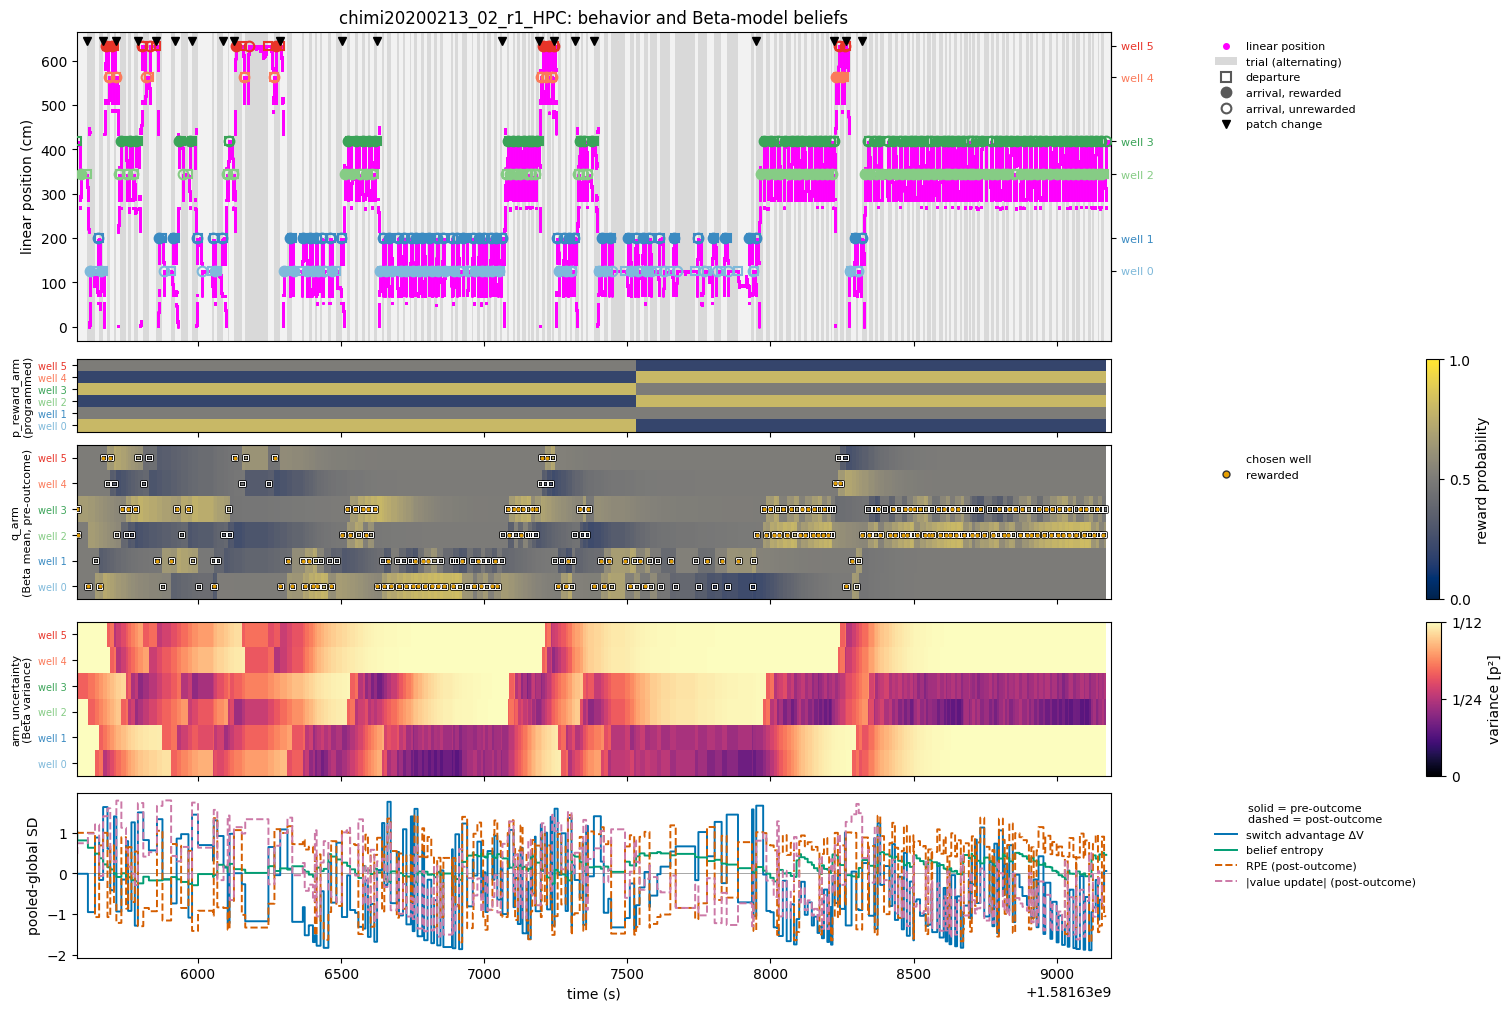

In [20]:
# Beliefs on the wall clock, aligned to the behavior panel.
from matplotlib.patches import Patch

from continuum_swr_replay.analysis.behavior.covariates import (
    attach_arm_uncertainty,
    attach_contingency_value_block,
)
from continuum_swr_replay.visualization.palettes import patch_grouped_arm_palette

t_start = float(position_info.index[0])
t_stop = float(position_info.index[-1])

WELL_COLORS = {w: c for w, c in patch_grouped_arm_palette().items() if w < 6}
TRIAL_SCALARS = (
    ("switch_advantage_mu_preoutcome_sess_z", "switch advantage ΔV", "-", "#0072B2"),
    ("beta_reward_entropy_z", "belief entropy", "-", "#009E73"),
    ("rpe_z", "RPE (post-outcome)", "--", "#D55E00"),
    ("global_mu_update_abs_postoutcome_sess_z", "|value update| (post-outcome)",
     "--", "#CC79A7"),
)

# Every belief value below is produced by the SAME builders that populate the
# fitted event-arm design matrix (arm_patch_tables.build_event_arm_table), keyed on stop_id --
# never on trial number, whose origin differs by animal.
stops = (
    stop_table[["stop_id", "stop_start", "stop_end"]]
    .sort_values("stop_start").reset_index(drop=True)
)
n_stops = len(stops)
arm_long = np.tile(np.arange(6), n_stops)
stop_id_long = np.repeat(stops["stop_id"].to_numpy(), 6)
p_reward_arm, q_arm = attach_contingency_value_block(
    arm_long, stop_id_long, qvals_session
)
arm_uncertainty = attach_arm_uncertainty(arm_long, stop_id_long, qvals_session)
p_reward_stop = p_reward_arm.reshape(n_stops, 6)
q_stop = q_arm.reshape(n_stops, 6)
uncertainty_stop = arm_uncertainty.reshape(n_stops, 6)

# Same one-to-one stop join build_trial_leaf_table performs.
scalar_cols = [col for col, *_ in TRIAL_SCALARS]
stop_scalars = stops.merge(
    qvals_session[["stop_id", *scalar_cols]],
    on="stop_id", how="left", validate="one_to_one",
).sort_values("stop_start").reset_index(drop=True)
chosen_arm_stop = stops.merge(
    qvals_session[["stop_id", "arm", "trial_reward", "trial_number_by_epoch"]],
    on="stop_id", how="left", validate="one_to_one",
)

# Cell edges: each stop's belief is held from its start to the next stop's
# start, so pcolormesh draws exact steps with no interpolation.
step_x = np.append(
    stops["stop_start"].to_numpy(dtype=float), float(stops["stop_end"].iloc[-1])
)
if not np.all(np.diff(step_x) > 0):
    raise ValueError("stop_start must be strictly increasing to step-hold belief")
well_edges = np.arange(7)
stop_mid = 0.5 * (step_x[:-1] + step_x[1:])


def _heat(ax, values, cmap, vmin, vmax):
    """Belief as wells x time; row order matches the behavior panel's well axis."""
    return ax.pcolormesh(step_x, well_edges, values.T, cmap=cmap, vmin=vmin,
                         vmax=vmax, shading="flat", rasterized=True)


def _well_axis(ax):
    ax.set_yticks(np.arange(6) + 0.5, labels=[f"well {w}" for w in range(6)],
                  fontsize=7)
    for tick, well in zip(ax.get_yticklabels(), range(6), strict=True):
        tick.set_color(WELL_COLORS[well])


fig, axes = plt.subplots(
    5, 1, figsize=(15, 10), sharex=True,
    height_ratios=[3.0, 0.7, 1.5, 1.5, 1.6], constrained_layout=True,
)

# ---- panel 1: position + trials ------------------------------------------
ax = axes[0]
for row_i, (_, trial) in enumerate(trials.iterrows()):
    ax.axvspan(trial["movement_start_time"], trial["end_time"],
               color="0.85" if row_i % 2 else "0.95", linewidth=0, zorder=0)
ax.scatter(position_info.index, position_info["linear_position"], s=1,
           color="magenta", rasterized=True, zorder=2)
blend = ax.get_xaxis_transform()
for _, trial in trials.iterrows():
    from_well, to_well = int(trial["from_well"]), int(trial["to_well"])
    ax.plot(trial["movement_start_time"], well_linear[from_well], marker="s", ms=6,
            mfc="none", mec=WELL_COLORS[from_well], mew=1.5, zorder=4)
    ax.plot(trial["destination_first_poke_in_time"], well_linear[to_well], marker="o", ms=7,
            mfc=WELL_COLORS[to_well] if trial["is_reward"] else "none",
            mec=WELL_COLORS[to_well], mew=1.5, zorder=4)
    if trial["is_patch_change"]:
        ax.plot(trial["movement_start_time"], 0.97, marker="v", ms=6, color="black",
                transform=blend, zorder=5)
ax.set(ylabel="linear position (cm)",
       title=f"{SESSION_ID}: behavior and Beta-model beliefs")
well_axis = ax.secondary_yaxis("right")
well_axis.set_yticks([well_linear[w] for w in sorted(well_linear)])
well_axis.set_yticklabels([f"well {w}" for w in sorted(well_linear)], fontsize=8)
for tick, well in zip(well_axis.get_yticklabels(), sorted(well_linear), strict=True):
    tick.set_color(WELL_COLORS[well])
ax.legend(handles=[
    Line2D([], [], ls="none", marker="o", ms=4, color="magenta", label="linear position"),
    Patch(facecolor="0.85", edgecolor="none", label="trial (alternating)"),
    Line2D([], [], ls="none", marker="s", ms=7, mfc="none", mec="0.35", mew=1.5, label="departure"),
    Line2D([], [], ls="none", marker="o", ms=7, mfc="0.35", mec="0.35", mew=1.5, label="arrival, rewarded"),
    Line2D([], [], ls="none", marker="o", ms=7, mfc="none", mec="0.35", mew=1.5, label="arrival, unrewarded"),
    Line2D([], [], ls="none", marker="v", ms=6, color="black", label="patch change"),
], loc="upper left", bbox_to_anchor=(1.09, 1.0), fontsize=8, frameon=False)

# ---- panel 2: programmed schedule (thin reference strip) ------------------
mesh_p = _heat(axes[1], p_reward_stop, "cividis", 0.0, 1.0)
_well_axis(axes[1])
axes[1].set_ylabel("p_reward_arm\n(programmed)", fontsize=8)

# ---- panel 3: learned value ----------------------------------------------
ax = axes[2]
mesh_q = _heat(ax, q_stop, "cividis", 0.0, 1.0)
_well_axis(ax)
ax.set_ylabel("q_arm\n(Beta mean, pre-outcome)", fontsize=8)
# Chosen well, ONE marker per behavioral trial (a trial spans several stops),
# ringed so it reads against either end of the colormap.
choice_marks = (
    chosen_arm_stop.assign(stop_mid=stop_mid)
    .dropna(subset=["arm", "trial_number_by_epoch"])
    .drop_duplicates("trial_number_by_epoch")
)
chosen = choice_marks["arm"].to_numpy(dtype=float) + 0.5
marks = ax.scatter(choice_marks["stop_mid"], chosen, marker="s", s=14,
                   facecolors="none", edgecolors="white", linewidths=0.7, zorder=3)
marks.set_path_effects([patheffects.Stroke(linewidth=1.8, foreground="black"),
                        patheffects.Normal()])
rewarded = choice_marks["trial_reward"].to_numpy() == 1
ax.scatter(choice_marks["stop_mid"][rewarded], chosen[rewarded], marker="o", s=8,
           color="#E69F00", edgecolors="0.2", linewidths=0.3, zorder=4)

# ---- panel 4: belief uncertainty -----------------------------------------
mesh_u = _heat(axes[3], uncertainty_stop, "magma", 0.0, 1 / 12)
_well_axis(axes[3])
axes[3].set_ylabel("arm_uncertainty\n(Beta variance)", fontsize=8)

# ---- panel 5: trial-grain scalars ----------------------------------------
ax = axes[4]
for col, label, ls, color in TRIAL_SCALARS:
    values = stop_scalars[col].to_numpy(dtype=float)
    ax.step(step_x, np.append(values, values[-1]), where="post",
            color=color, ls=ls, lw=1.4, label=label)
ax.axhline(0.0, color="0.6", lw=0.6, zorder=0)
ax.set(ylabel="pooled-global SD", xlabel="time (s)", xlim=(t_start, t_stop))
ax.legend(loc="upper left", bbox_to_anchor=(1.09, 1.0), fontsize=8, frameon=False,
          title="solid = pre-outcome\ndashed = post-outcome", title_fontsize=8)

fig.colorbar(mesh_q, ax=[axes[1], axes[2]], label="reward probability",
             ticks=(0, 0.5, 1), pad=0.005, aspect=18)
cbar_u = fig.colorbar(mesh_u, ax=axes[3], label="variance [p²]",
                      ticks=(0, 1 / 24, 1 / 12), pad=0.005, aspect=10)
cbar_u.set_ticks((0, 1 / 24, 1 / 12), labels=("0", "1/24", "1/12"))
axes[2].legend(handles=[
    Line2D([], [], ls="none", marker="s", ms=6, mfc="none", mec="white", mew=1.0,
           label="chosen well"),
    Line2D([], [], ls="none", marker="o", ms=5, mfc="#E69F00", mec="0.2",
           label="rewarded"),
], loc="upper left", bbox_to_anchor=(1.09, 1.0), fontsize=8, frameon=False)

# ---- the production path must reproduce the section-4a belief table -------
mapped = stops["stop_id"].isin(qvals_session["stop_id"]).to_numpy()
stop_trial = stops.merge(
    qvals_session[["stop_id", "trial_number_by_epoch"]], on="stop_id", how="left"
)["trial_number_by_epoch"].to_numpy()
trial_row = pd.Index(belief_trials["trial_number_by_epoch"]).get_indexer(
    stop_trial[mapped]
)
np.testing.assert_allclose(q_stop[mapped], q_matrix[trial_row], rtol=0, atol=1e-12)
print(f"stops={n_stops}, with belief={int(mapped.sum())} ({mapped.mean():.1%}); "
      "production q_arm matches the section-4a q_port matrix")


## 5. Event classification table

`build_event_table` produces **one row per canonical non-local event**. The
legacy `event_*` timing columns describe the filtered survivor window used by
the content tables; `label_event_*`, speed summaries, peak probability, and
SWR overlap classification describe the full detector-label window. Passing
the conditional posterior also populates the posterior-weighted robustness
columns; the primary regressions below still use hard MAP counts.

In [21]:
event_table = build_event_table(
    dot, env, trials, track_graph, conditional_posterior=posterior
)
stop_table = add_nonlocal_swr_split(stop_table, event_table)

print("event_table:", event_table.shape)
print("\noverlap_class counts:\n", event_table["overlap_class"].value_counts())
event_table[
    [
        "event_id",
        "event_duration",
        "label_event_duration",
        "mean_speed",
        "peak_nonlocal_prob",
        "overlap_class",
        "is_swr",
    ]
].head()

event_table: (1714, 94)

overlap_class counts:
 overlap_class
non_swr          948
swr_contained    457
swr_partial      309
Name: count, dtype: int64


,event_id,event_duration,label_event_duration,mean_speed,peak_nonlocal_prob,overlap_class,is_swr
0,4684575748763187657,0.028,0.028,0.710441,0.991874,non_swr,False
1,507077526136763520,0.064,0.064,0.504014,0.999833,non_swr,False
2,1227836852711955074,0.042,0.042,0.370488,1.000061,non_swr,False
3,7289660146915800854,0.034,0.034,0.910535,0.907365,non_swr,False
4,6602360879545841726,0.026,0.026,1.020461,1.000046,non_swr,False


In [22]:
event_table.head()

,animal,day,epoch,non_local_event,event_id,event_start,event_end,event_duration,event_midpoint_time,time_since_stop,time_since_port_entry,time_since_reward,is_swr,is_mua,is_after_switch,is_after_omission,is_after_reward,is_after_stay,reward_outcome,is_stay,current_arm,prev_arm,next_arm,last_rewarded_arm,current_patch,prev_patch,next_patch,n_nonlocal_bins,nonlocal_weight_sum,posterior_mass_total,...,replay_speed_continuous_median,step_distance_median,step_distance_p90,step_distance_max,spatial_extent,n_reversals,pause_fraction,n_patches_visited,crosses_trunk,terminates_at_well,compression_factor,mean_abs_ahead_behind,max_ahead,max_behind,max_abs_ahead_behind,remote_fraction,ab_slope,is_outbound,hpd_coverage_cm,multimodal_fraction,path_continuity,ripple_power_z,mua_rate_z,theta_z,continuous_prob_mean,fragmented_prob_mean,local_prob_mean,nospike_prob_mean,nonlocal_fraction,nospike_fraction
0,chimi,20200213,02_r1,1,4684575748763187657,1.581636e+09,1.581636e+09,0.028,1.581636e+09,0.236000,-16.354421,NaN,False,False,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0,15,13.515846,13.515846,...,638.088415,1.98302,1.983020,3.966039,9.915098,1,0.933333,1,False,True,15.177390,213.037639,0.0,218.603062,218.603062,1.0,-238.396094,0.0,92.217619,0.666667,1.0,0.277891,0.237159,-0.273163,0.889823,0.011234,0.098917,0.000026,1.0,0.0
1,chimi,20200213,02_r1,2,507077526136763520,1.581636e+09,1.581636e+09,0.064,1.581636e+09,0.466000,-16.124421,NaN,False,False,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0,33,32.353026,32.353026,...,314.288013,0.00000,1.949121,1.949121,7.796483,1,1.000000,1,False,False,7.475565,185.951609,0.0,190.450808,190.450808,1.0,46.329387,1.0,22.434504,0.000000,1.0,0.051733,-0.212574,-0.878568,0.979459,0.000936,0.019568,0.000029,1.0,0.0
2,chimi,20200213,02_r1,3,1227836852711955074,1.581636e+09,1.581636e+09,0.042,1.581636e+09,1.368999,-15.220422,NaN,False,False,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0,22,21.496454,21.496454,...,305.441778,0.00000,1.949576,5.848729,13.647033,0,0.954545,1,False,False,7.265151,32.083453,0.0,39.220891,39.220891,0.0,-302.400331,0.0,22.316428,0.000000,1.0,-0.011754,-0.119799,-1.155333,0.975749,0.001362,0.021209,0.001680,1.0,0.0
3,chimi,20200213,02_r1,4,7289660146915800854,1.581636e+09,1.581636e+09,0.034,1.581636e+09,1.724999,-14.864422,NaN,False,False,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0,18,15.902621,15.902621,...,291.871434,0.00000,1.983020,1.983020,3.966039,0,1.000000,1,False,False,6.942371,214.696891,0.0,216.375460,216.375460,1.0,26.998893,1.0,31.388626,1.000000,1.0,0.251191,0.072553,-0.968815,0.881326,0.002153,0.116496,0.000029,1.0,0.0
4,chimi,20200213,02_r1,5,6602360879545841726,1.581636e+09,1.581636e+09,0.026,1.581636e+09,0.285000,-14.032422,NaN,False,False,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0,14,13.770840,13.770840,...,402.813341,0.00000,1.981690,1.981690,7.926761,0,1.000000,1,False,False,9.581204,78.553696,0.0,82.674940,82.674940,1.0,334.328854,1.0,19.760918,0.000000,1.0,0.612640,0.923558,-0.836835,0.982274,0.001357,0.016382,0.000005,1.0,0.0


In [23]:
event_table.tail()

,animal,day,epoch,non_local_event,event_id,event_start,event_end,event_duration,event_midpoint_time,time_since_stop,time_since_port_entry,time_since_reward,is_swr,is_mua,is_after_switch,is_after_omission,is_after_reward,is_after_stay,reward_outcome,is_stay,current_arm,prev_arm,next_arm,last_rewarded_arm,current_patch,prev_patch,next_patch,n_nonlocal_bins,nonlocal_weight_sum,posterior_mass_total,...,replay_speed_continuous_median,step_distance_median,step_distance_p90,step_distance_max,spatial_extent,n_reversals,pause_fraction,n_patches_visited,crosses_trunk,terminates_at_well,compression_factor,mean_abs_ahead_behind,max_ahead,max_behind,max_abs_ahead_behind,remote_fraction,ab_slope,is_outbound,hpd_coverage_cm,multimodal_fraction,path_continuity,ripple_power_z,mua_rate_z,theta_z,continuous_prob_mean,fragmented_prob_mean,local_prob_mean,nospike_prob_mean,nonlocal_fraction,nospike_fraction
1709,chimi,20200213,02_r1,1710,503107956359428645,1.581639e+09,1.581639e+09,0.476,1.581639e+09,0.510,12.976360,27.834082,False,False,0.0,1.0,0.0,1.0,0.0,NaN,3.0,2.0,NaN,2.0,2.0,2.0,NaN,239,209.265648,209.265648,...,0.003086,0.0,1.949576,1.949576,9.747881,5,1.000000,1,False,True,0.000073,3.476744,4.248344,5.910687,5.910687,0.0,11.683246,1.0,11.779226,0.075314,1.0,-0.499876,-0.684232,-0.241527,0.875565,0.000024,0.123625,0.000772,1.0,0.0
1710,chimi,20200213,02_r1,1711,3463953848162105764,1.581639e+09,1.581639e+09,0.102,1.581639e+09,0.269,14.352360,29.210081,False,False,0.0,1.0,0.0,1.0,0.0,NaN,3.0,2.0,NaN,2.0,2.0,2.0,NaN,52,43.621433,43.621433,...,105.860366,0.0,1.949576,1.949576,9.747881,3,1.000000,1,False,False,2.517965,4.131883,2.968825,6.731165,6.731165,0.0,-98.791688,0.0,13.562884,0.000000,1.0,-0.299988,-0.316580,0.202962,0.838802,0.000072,0.160821,0.000292,1.0,0.0
1711,chimi,20200213,02_r1,1712,6401975598642465275,1.581639e+09,1.581639e+09,0.034,1.581639e+09,0.459,15.782359,30.640080,False,False,0.0,1.0,0.0,1.0,0.0,NaN,3.0,2.0,NaN,2.0,2.0,2.0,NaN,18,14.460002,14.460002,...,0.000000,0.0,0.000000,0.000000,0.000000,0,1.000000,1,False,True,0.000000,6.962364,0.000000,7.083706,7.083706,0.0,-6.546272,0.0,10.823664,0.000000,1.0,-0.727354,-0.898067,-1.190206,0.803302,0.000031,0.196615,0.000067,1.0,0.0
1712,chimi,20200213,02_r1,1713,8811853525884853708,1.581639e+09,1.581639e+09,0.068,1.581639e+09,0.556,15.878359,30.736080,False,False,0.0,1.0,0.0,1.0,0.0,NaN,3.0,2.0,NaN,2.0,2.0,2.0,NaN,35,34.660699,34.660699,...,426.449361,0.0,1.948260,7.783612,13.620850,1,0.971429,2,True,False,10.143403,109.835245,114.730150,0.000000,114.730150,1.0,-35.036955,0.0,23.267785,0.000000,1.0,0.484768,0.566294,-1.243933,0.988848,0.001458,0.009674,0.000016,1.0,0.0
1713,chimi,20200213,02_r1,1714,2636278536692877916,1.581639e+09,1.581639e+09,0.050,1.581639e+09,0.477,17.474358,32.332080,False,False,0.0,1.0,0.0,1.0,0.0,NaN,3.0,2.0,NaN,2.0,2.0,2.0,NaN,26,24.378689,24.378689,...,287.826111,0.0,1.949576,1.949576,9.747881,0,1.000000,1,False,True,6.846150,9.365801,0.000000,12.378991,12.378991,0.0,163.595774,1.0,13.188218,0.000000,1.0,0.083049,-0.205033,-0.598184,0.937510,0.000131,0.062276,0.000090,1.0,0.0


### 5a. Event summary for this epoch

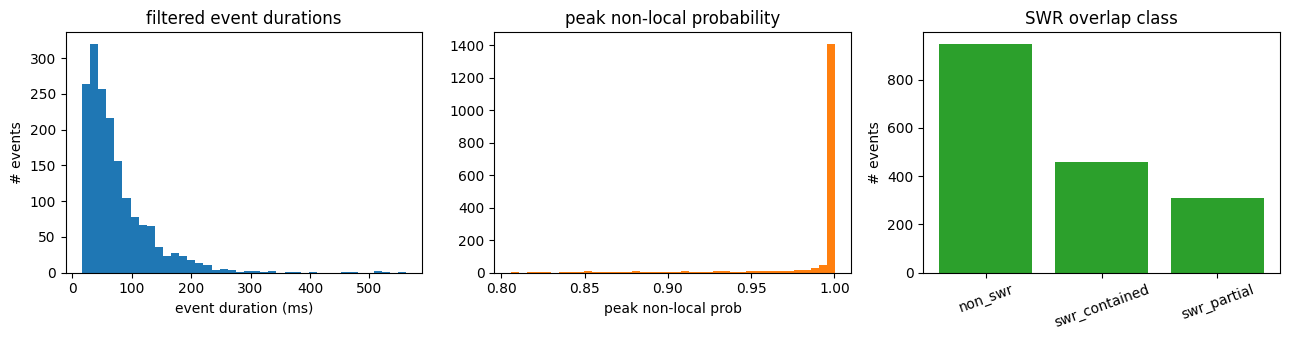

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

axes[0].hist(event_table["event_duration"] * 1e3, bins=40, color="C0")
axes[0].set(xlabel="event duration (ms)", ylabel="# events",
            title="filtered event durations")

axes[1].hist(event_table["peak_nonlocal_prob"], bins=40, color="C1")
axes[1].set(xlabel="peak non-local prob", title="peak non-local probability")

vc = event_table["overlap_class"].value_counts()
axes[2].bar(vc.index.astype(str), vc.values, color="C2")
axes[2].set(ylabel="# events", title="SWR overlap class")
axes[2].tick_params(axis="x", rotation=20)
fig.tight_layout()

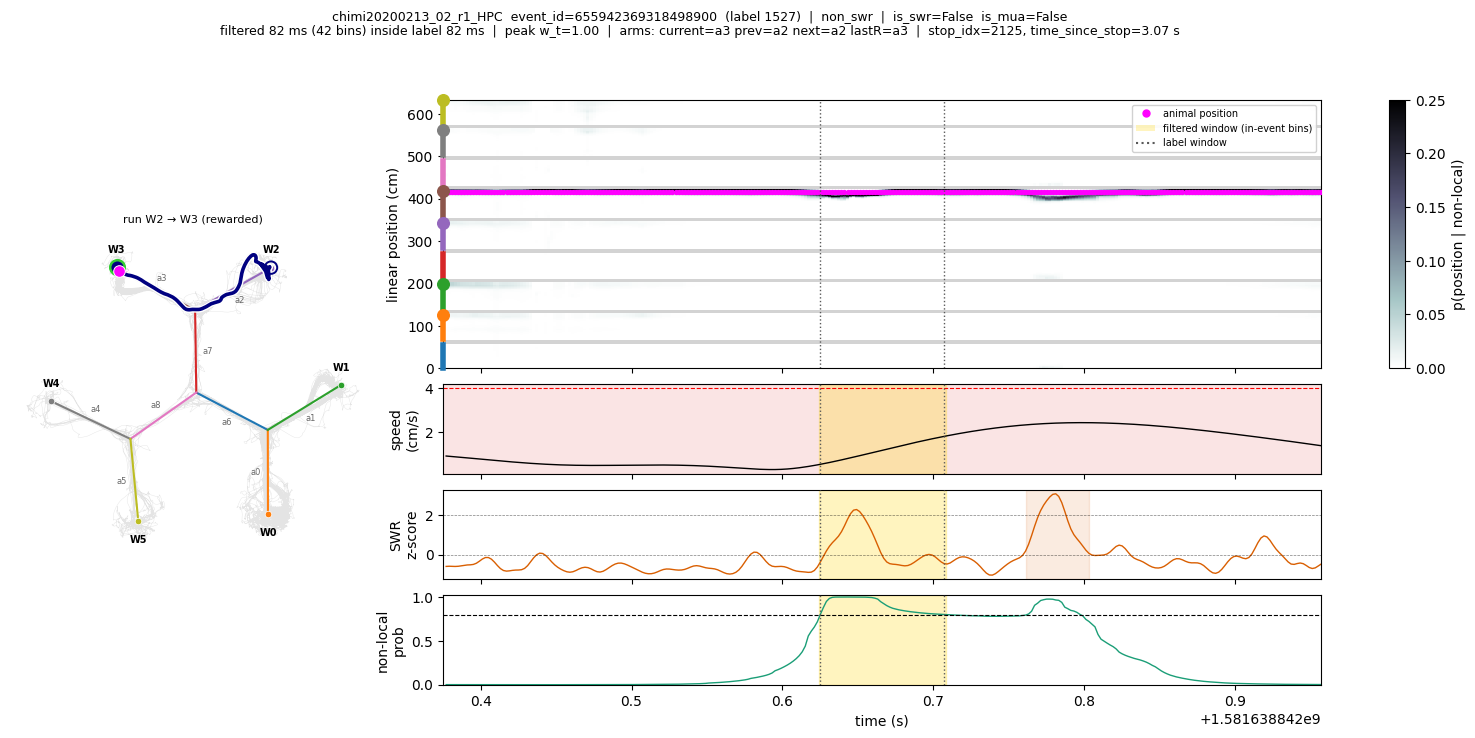

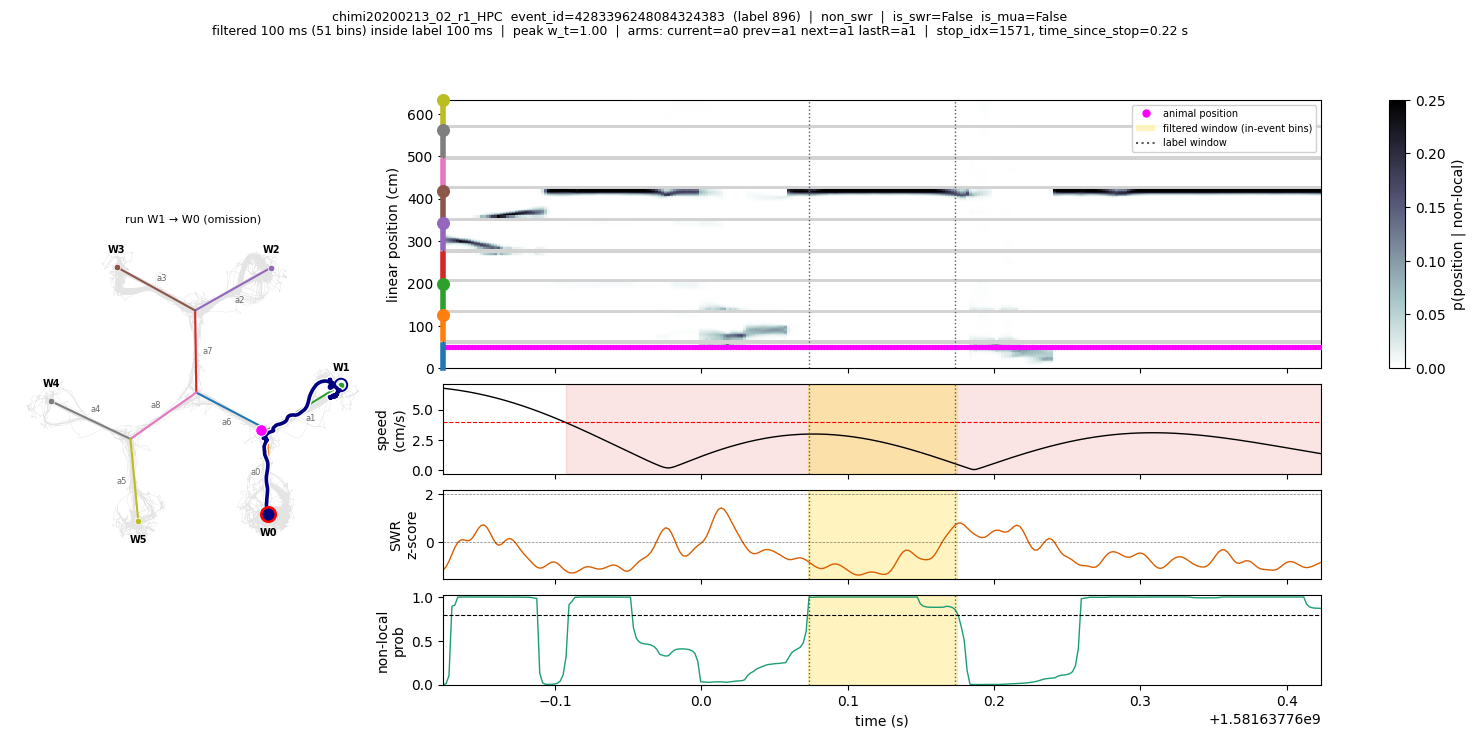

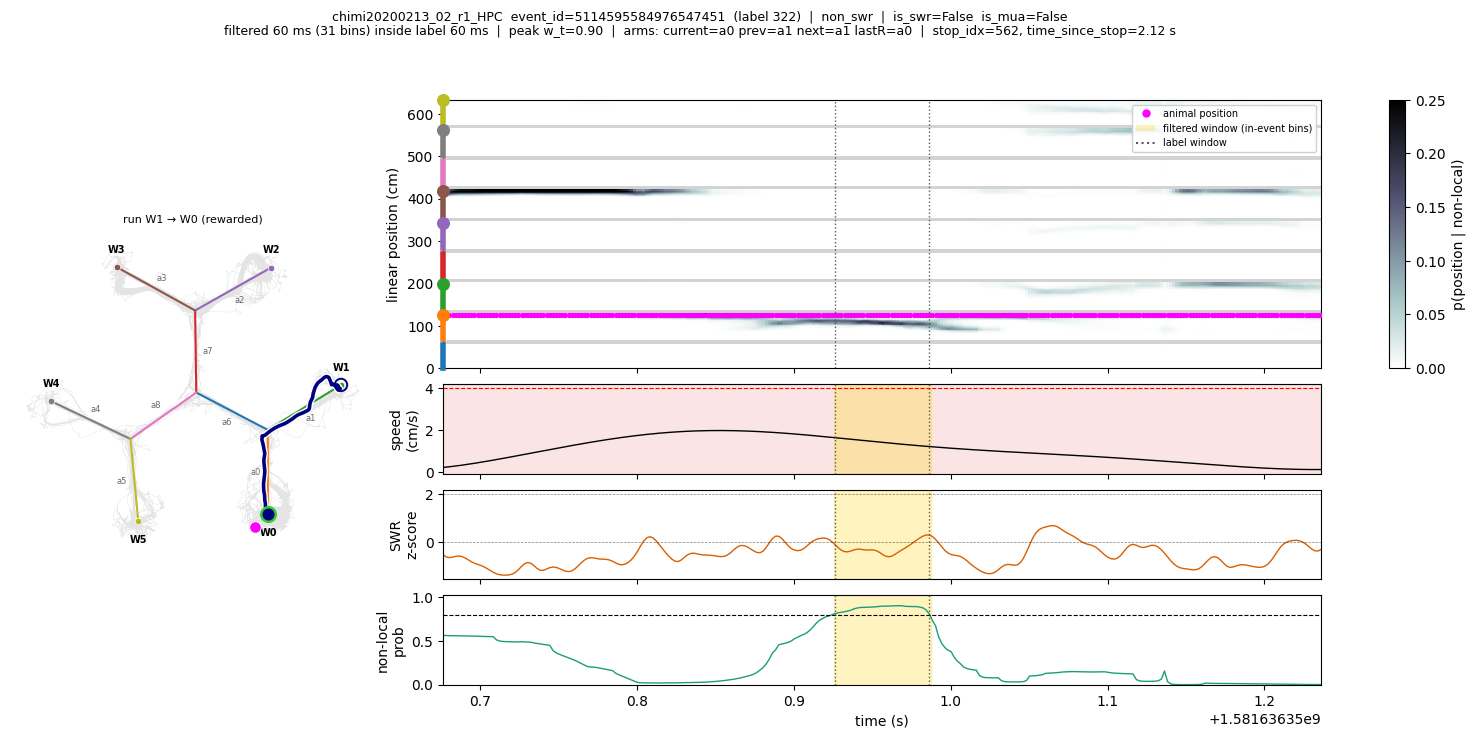

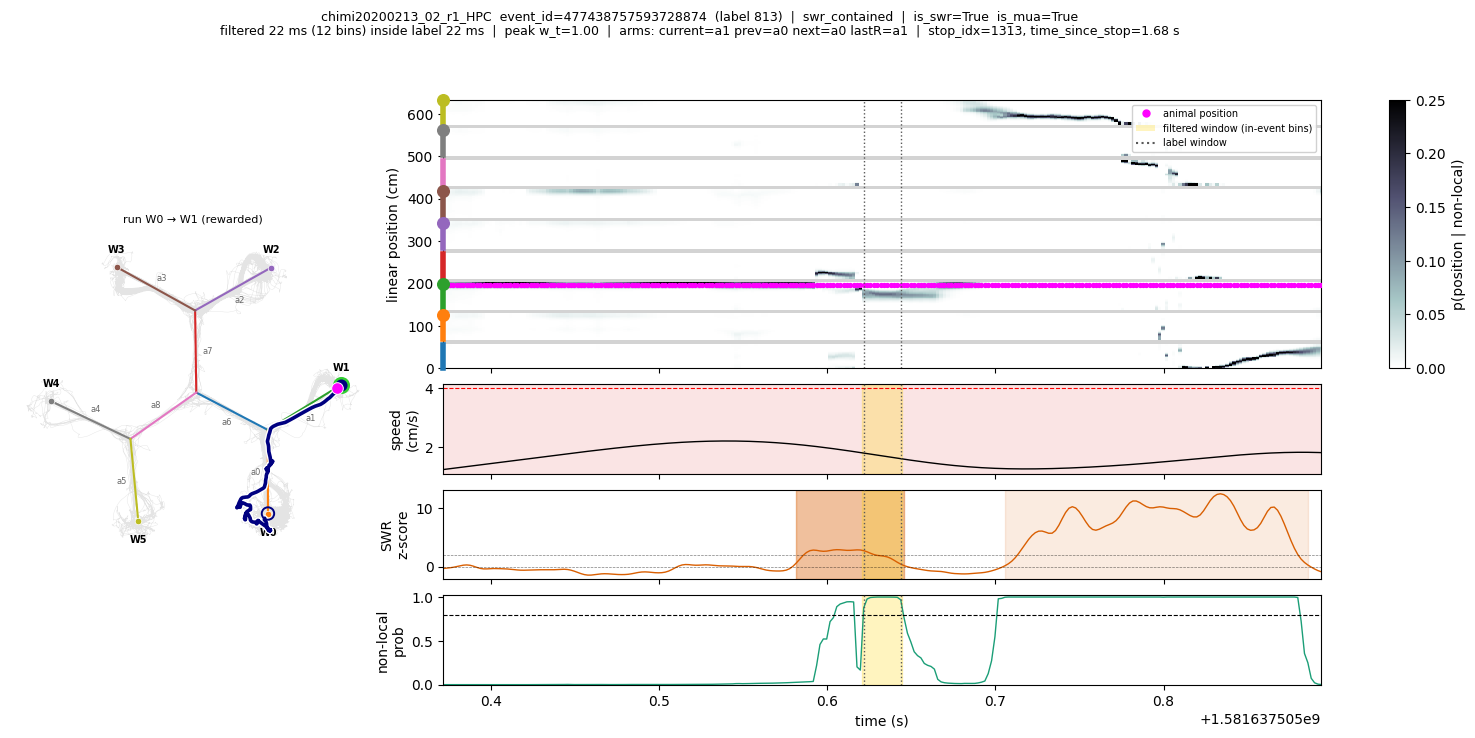

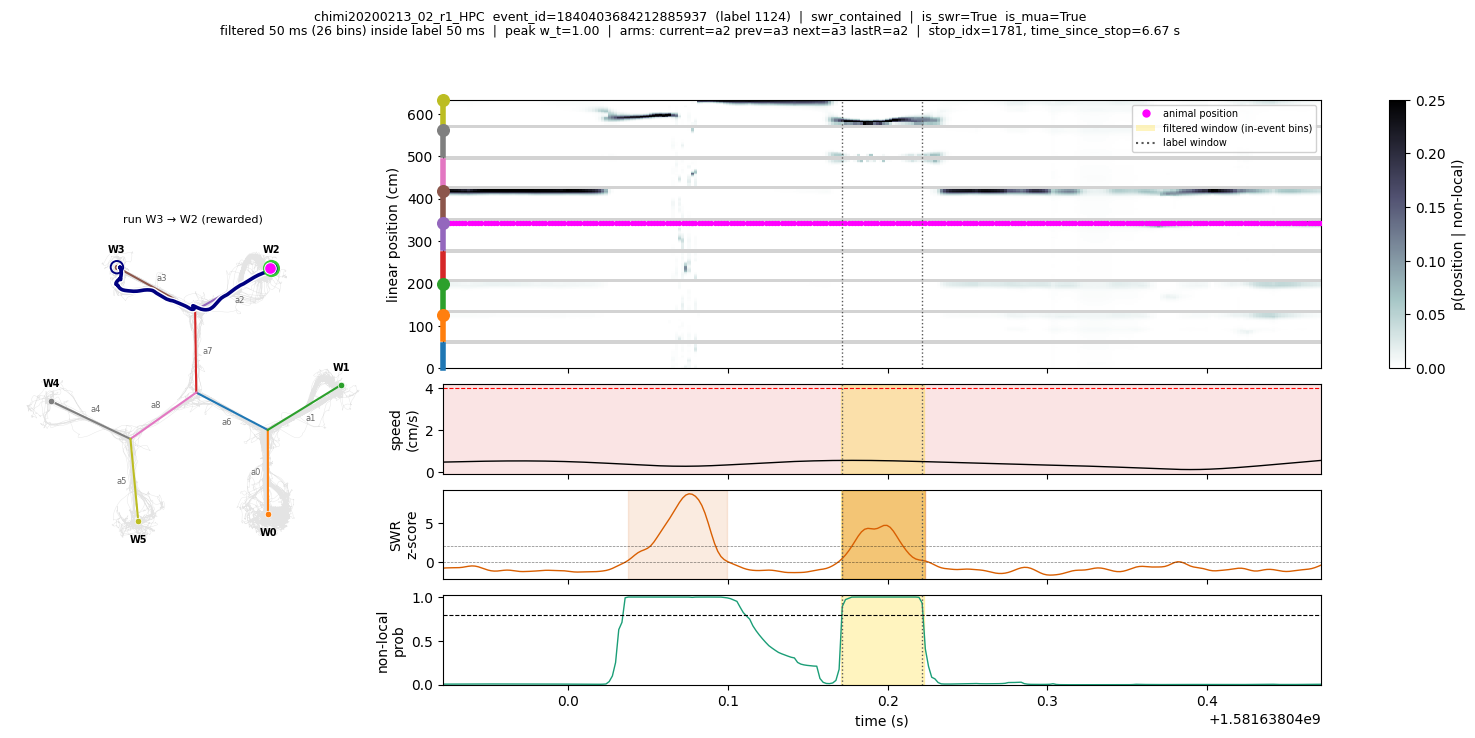

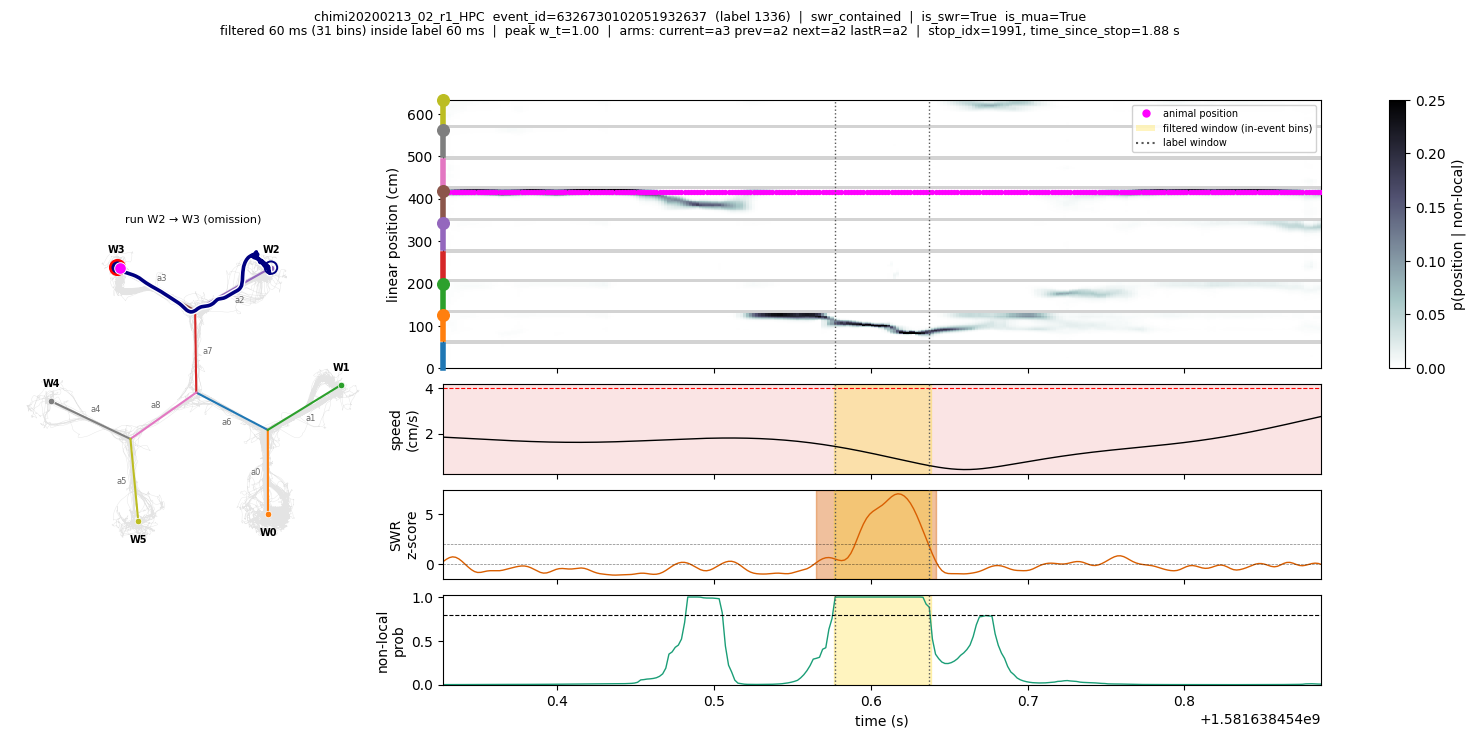

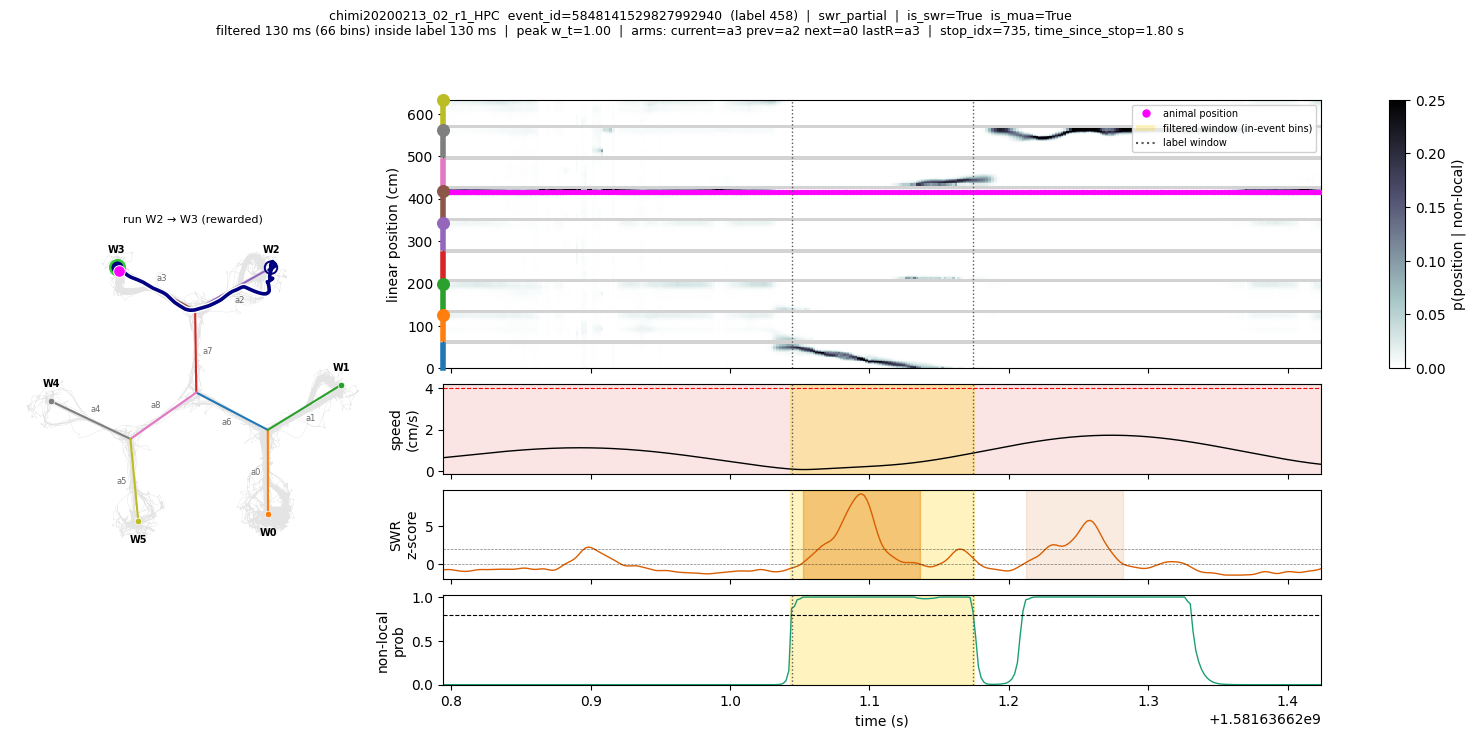

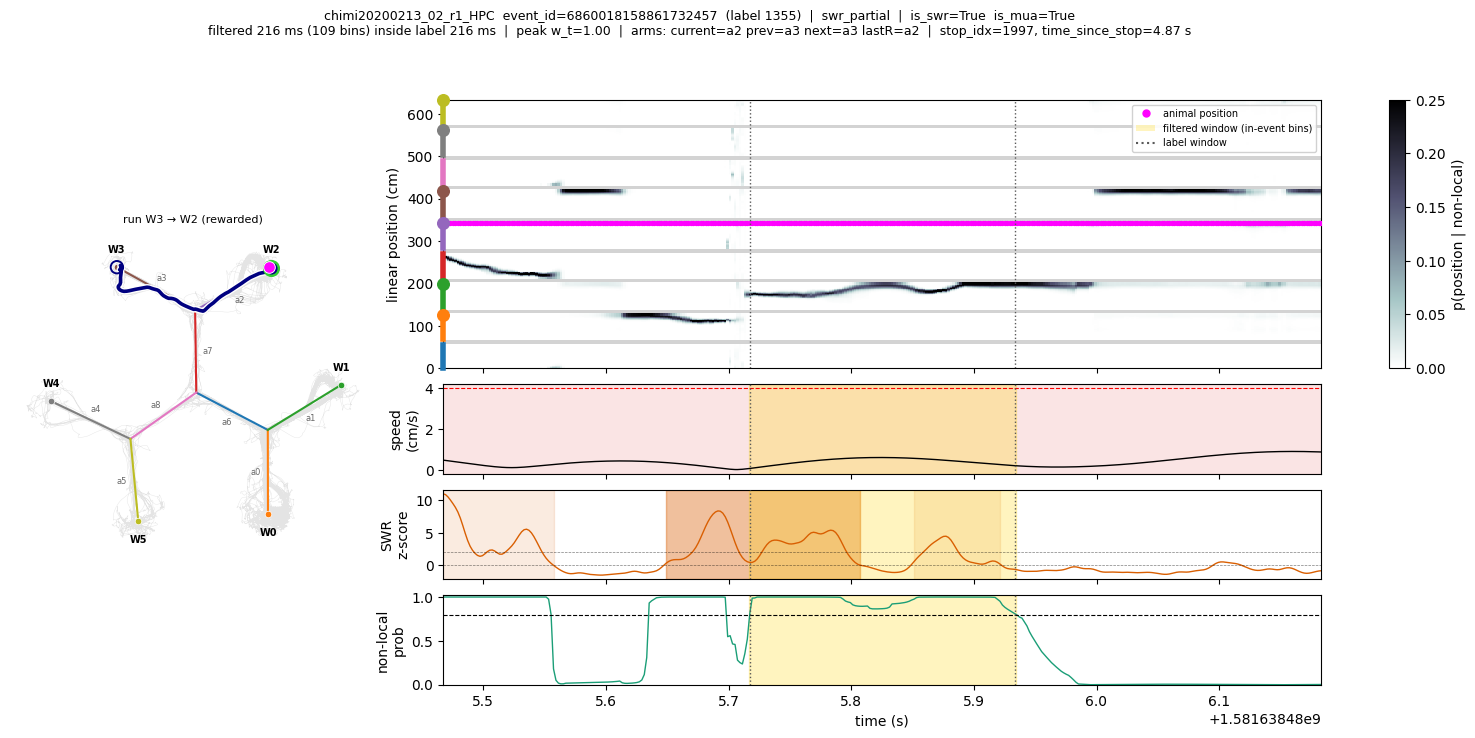

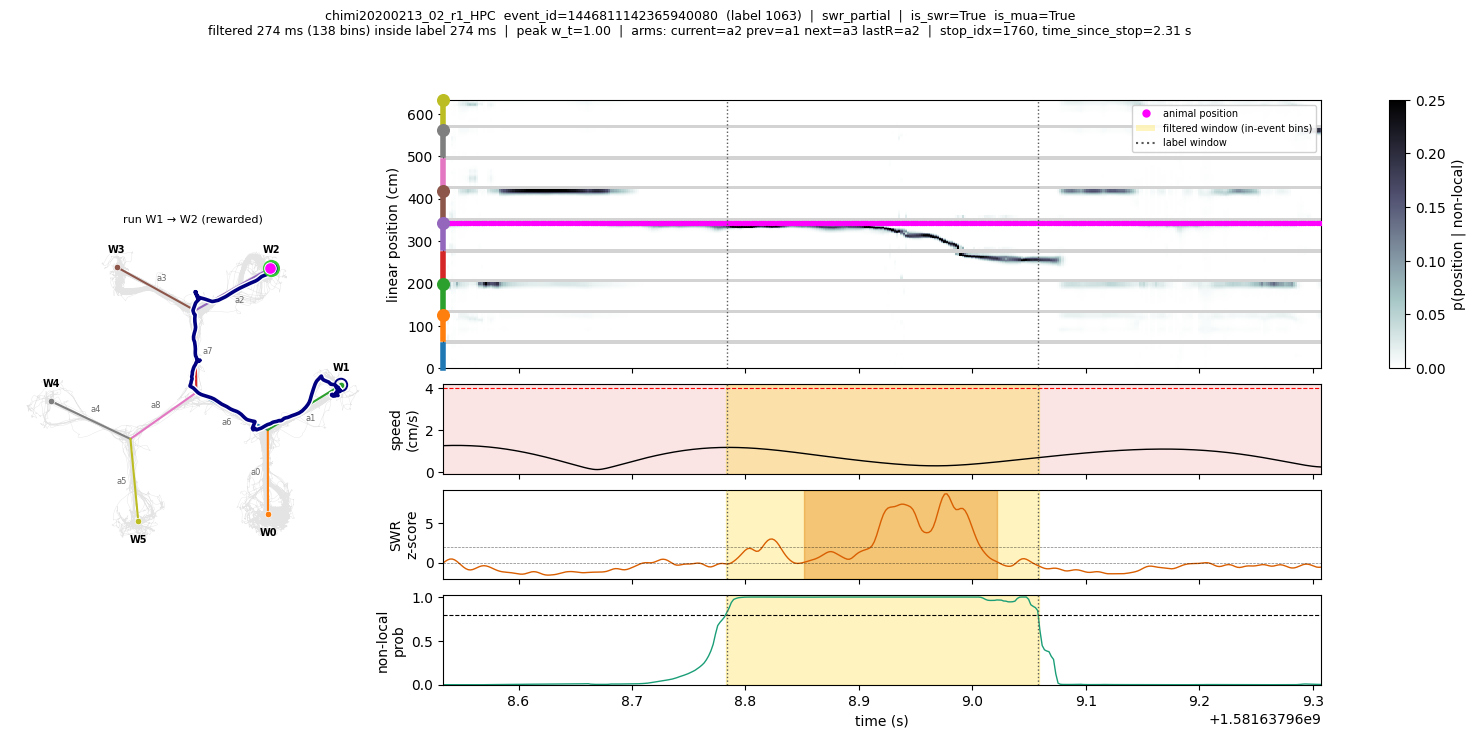

In [25]:
import copy

from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from continuum_swr_replay.analysis.constants import (
    DEFAULT_IMMOBILITY_THRESHOLD_CM_PER_SEC,
    DEFAULT_NON_LOCAL_THRESHOLD,
)
from continuum_swr_replay.visualization.palettes import COLORS
from continuum_swr_replay.visualization import plot_graph_as_1D
from continuum_swr_replay.visualization.plots import plot_track_graph_2d

# Arm id of each track-graph edge: leaf arm w joins well w to patch junction
# 6 + w // 2; trunk arms 6/7/8 join junction 6/7/8 to the center node 9.
ARM_OF_EDGE = {frozenset((w, 6 + w // 2)): w for w in range(6)}
ARM_OF_EDGE.update({frozenset((j, 9)): j for j in (6, 7, 8)})

PLACE_BIN_CENTERS = np.asarray(env.place_bin_centers_).squeeze()
IS_TRACK_INTERIOR = np.asarray(env.is_track_interior_).squeeze()
WELL_NODES = [n for n in track_graph.nodes if track_graph.degree(n) == 1]

if PLACE_BIN_CENTERS.shape != IS_TRACK_INTERIOR.shape:
    raise ValueError(
        f"env place-bin axes disagree: centers {PLACE_BIN_CENTERS.shape} "
        f"vs is_track_interior {IS_TRACK_INTERIOR.shape}"
    )
if posterior.shape[1] != PLACE_BIN_CENTERS.size:
    raise ValueError(
        f"posterior has {posterior.shape[1]} place bins; "
        f"env has {PLACE_BIN_CENTERS.size}"
    )

# The same three-way filter build_event_table applies (_in_event_mask): event
# label set, animal immobile, smoothed non-local posterior over threshold.
# Recomputed here so the shaded "filtered survivor window" is the real one.
NONLOCAL_PROB = dot["Non-Local_Continuous_prob"] + dot["Non-Local_Fragmented_prob"]
IN_EVENT = (
    (dot["non_local_event"] > 0)
    & (dot["head_speed"] < DEFAULT_IMMOBILITY_THRESHOLD_CM_PER_SEC)
    & (NONLOCAL_PROB > DEFAULT_NON_LOCAL_THRESHOLD)
)


def _label_intervals(labels: pd.Series) -> list[tuple[float, float]]:
    """(start, end) seconds for each positive label run in a time-indexed series."""
    positive = labels[labels > 0]
    if not len(positive):
        return []
    return [
        (float(g.index[0]), float(g.index[-1]))
        for _, g in positive.groupby(positive.to_numpy())
    ]


def _current_trial(t: float):
    """Latest trial started at or before ``t`` — the trip the animal is on."""
    started = trials.loc[trials["movement_start_time"] <= t]
    return started.iloc[-1] if len(started) else None


def _arm_label(value) -> str:
    return "?" if pd.isna(value) else f"a{int(value)}"


def _plot_2d_context(ax, row, pos_win) -> None:
    """2-D track with arm/well ids, the run into this stop, and the animal.

    The run drawn is the animal's real head-position path over the *current
    trip* — the same trial ``add_trial_context`` uses to derive this event's
    ``reward_outcome`` / ``is_after_switch`` / ``prev_arm``, so the path and the
    title's covariates always describe the same trial. The run portion is
    ``[start_time, destination_first_poke_in_time]`` when the arrival time is available, else
    the whole trial interval.
    """
    plot_track_graph_2d(track_graph, position_info, ax=ax, edge_order=linear_edge_order)
    node_pos = {n: track_graph.nodes[n]["pos"] for n in track_graph.nodes}

    for node in WELL_NODES:
        x, y = node_pos[node]
        below = node in (0, 5)  # bottom wells — label under, not over the markers
        ax.annotate(
            f"W{node}",
            (x, y),
            fontsize=7,
            fontweight="bold",
            ha="center",
            va="top" if below else "bottom",
            xytext=(0, -10 if below else 9),
            textcoords="offset points",
        )

    for n1, n2 in track_graph.edges:
        arm = ARM_OF_EDGE.get(frozenset((n1, n2)))
        if arm is None:
            continue
        (x1, y1), (x2, y2) = node_pos[n1], node_pos[n2]
        dx, dy = x2 - x1, y2 - y1
        norm = float(np.hypot(dx, dy)) or 1.0
        ax.annotate(
            f"a{arm}",
            ((x1 + x2) / 2, (y1 + y2) / 2),
            fontsize=6,
            color="dimgray",
            ha="center",
            va="center",
            xytext=(-9 * dy / norm, 9 * dx / norm),  # perpendicular to the edge
            textcoords="offset points",
        )

    trial = _current_trial(float(row["event_start"]))
    if trial is not None:
        run_end = trial.get("destination_first_poke_in_time")
        if run_end is None or pd.isna(run_end):
            run_end = trial["end_time"]
        run = position_info.loc[trial["movement_start_time"] : run_end]
        if len(run):
            # Thick navy line with a white halo so the run reads over the tab10
            # arm colors and the faint session-wide occupancy underneath.
            ax.plot(
                run["head_position_x"],
                run["head_position_y"],
                color="navy",
                lw=2.6,
                zorder=5,
                solid_capstyle="round",
                path_effects=[
                    patheffects.Stroke(linewidth=4.6, foreground="white"),
                    patheffects.Normal(),
                ],
            )
        from_well, to_well = int(trial["from_well"]), int(trial["to_well"])
        rewarded = bool(trial["is_reward"])
        if from_well in node_pos:  # departure: open ring
            ax.scatter(
                *node_pos[from_well],
                s=80,
                facecolor="none",
                edgecolor="navy",
                linewidth=1.4,
                zorder=6,
            )
        if to_well in node_pos:  # arrival: filled, rimmed by trial outcome
            ax.scatter(
                *node_pos[to_well],
                s=110,
                facecolor="navy",
                edgecolor="limegreen" if rewarded else "red",
                linewidth=1.8,
                zorder=6,
            )
        ax.set_title(
            f"run W{from_well} → W{to_well} "
            f"({'rewarded' if rewarded else 'omission'})",
            fontsize=8,
        )
    else:
        ax.set_title("run W? → W? (no trial started yet)", fontsize=8)

    # The animal itself during the event — immobile, so ~a point. Magenta to
    # match the position overlay on the posterior row.
    if len(pos_win):
        nearest = int(
            np.argmin(
                np.abs(pos_win.index.to_numpy() - row["label_event_midpoint_time"])
            )
        )
        ax.scatter(
            pos_win["head_position_x"].iloc[nearest],
            pos_win["head_position_y"].iloc[nearest],
            s=70,
            facecolor="magenta",
            edgecolor="white",
            linewidth=0.7,
            zorder=7,
        )



def plot_event(
    event_id: int,
    *,
    pad: float = 0.25,
    center: float | None = None,
    half_width: float | None = None,
    posterior_max: float = 0.25,
    figsize: tuple[float, float] = (15.0, 7.5),
):
    """Plot one non-local event: posterior, position, speed, SWR, non-local prob.

    Left panel is the 2-D track with the animal's path during the window. The
    right column is four time-aligned rows sharing an x axis. Both event windows
    are drawn on every row: the **label window** (detector's full event, dotted
    verticals) and the **filtered survivor window** (gold span) — the bins that
    actually survive the immobility + probability filter and feed the content
    tables.

    Parameters
    ----------
    event_id : int
        Canonical ``event_table["event_id"]`` hash.
    pad : float, default 0.25
        Seconds of context on each side of the label window. Ignored when
        ``half_width`` is given.
    center, half_width : float, optional
        Override the window. ``center`` defaults to the label-window midpoint,
        ``half_width`` to half the label duration plus ``pad``.
    posterior_max : float, default 0.25
        Colormap ceiling for the conditional posterior.

    Returns
    -------
    matplotlib.figure.Figure
    """
    match = event_table.loc[event_table["event_id"] == event_id]
    if len(match) != 1:
        raise KeyError(
            f"expected exactly 1 event_table row for event_id={event_id}, "
            f"got {len(match)}"
        )
    row = match.iloc[0]

    if center is None:
        center = 0.5 * (row["label_event_start"] + row["label_event_end"])
    if half_width is None:
        half_width = 0.5 * (row["label_event_end"] - row["label_event_start"]) + pad
    t_start, t_stop = float(center - half_width), float(center + half_width)

    dot_win = dot.loc[t_start:t_stop]
    pos_win = position_info.loc[t_start:t_stop]

    fig = plt.figure(figsize=figsize)
    gs = GridSpec(
        1,
        3,
        figure=fig,
        width_ratios=[1.0, 2.4, 0.045],
        wspace=0.16,
        left=0.04,
        right=0.97,
        top=0.86,
        bottom=0.08,
    )
    heights = [3.0, 1.0, 1.0, 1.0]
    gs_rows = gs[1].subgridspec(4, 1, height_ratios=heights, hspace=0.12)
    gs_cbar = gs[2].subgridspec(4, 1, height_ratios=heights, hspace=0.12)

    ax_2d = fig.add_subplot(gs[0])
    ax_post = fig.add_subplot(gs_rows[0])
    ax_speed = fig.add_subplot(gs_rows[1], sharex=ax_post)
    ax_swr = fig.add_subplot(gs_rows[2], sharex=ax_post)
    ax_nl = fig.add_subplot(gs_rows[3], sharex=ax_post)
    time_axes = [ax_post, ax_speed, ax_swr, ax_nl]

    # --- Row 1: conditional non-local posterior + the animal's real position ---
    # NOTE: load_conditional_posterior forward-fills timebins with negligible
    # non-local mass, so outside the event the heatmap shows the last valid
    # distribution, not new evidence. Read it together with the bottom row.
    post_win = posterior.sel(time=slice(t_start, t_stop))
    post_values = np.asarray(post_win.values, dtype=float)
    post_values[:, ~IS_TRACK_INTERIOR] = np.nan
    cmap = copy.copy(plt.get_cmap("bone_r"))
    cmap.set_bad(color="lightgray", alpha=1.0)
    time_mesh, position_mesh = np.meshgrid(
        np.asarray(post_win["time"].values, dtype=float), PLACE_BIN_CENTERS
    )
    mesh = ax_post.pcolormesh(
        time_mesh,
        position_mesh,
        post_values.T,
        vmin=0.0,
        vmax=posterior_max,
        cmap=cmap,
        rasterized=True,
    )
    fig.colorbar(mesh, cax=fig.add_subplot(gs_cbar[0]), label="p(position | non-local)")
    ax_post.scatter(
        pos_win.index,
        pos_win["linear_position"],
        s=8,
        color="magenta",
        zorder=3,
        rasterized=True,
    )
    plot_graph_as_1D(
        track_graph,
        ax=ax_post,
        edge_order=linear_edge_order,
        edge_spacing=linear_edge_spacing,
        reward_well_nodes=WELL_NODES,
        other_axis_start=t_start,
        reward_well_size=70,
        edge_linewidth=4,
    )
    ax_post.set_ylabel("linear position (cm)")

    # --- Row 2: head speed, with the immobility bout this event sits in ---
    ax_speed.plot(dot_win.index, dot_win["head_speed"], color="black", lw=1)
    ax_speed.axhline(
        DEFAULT_IMMOBILITY_THRESHOLD_CM_PER_SEC, color="red", ls="--", lw=0.8
    )
    ax_speed.set_ylabel("speed\n(cm/s)")
    stop_match = stop_table.loc[stop_table["stop_id"] == row["stop_id"]]
    if len(stop_match):
        stop = stop_match.iloc[0]
        ax_speed.axvspan(
            stop["stop_start"], stop["stop_end"], color="C3", alpha=0.12, zorder=0
        )

    # --- Row 3: SWR z-score; all SWR intervals faint, the matched one solid ---
    ax_swr.plot(dot_win.index, dot_win["SWR_zscore"], color=COLORS["SWR"], lw=1)
    for level in (0.0, 2.0):
        ax_swr.axhline(level, color="black", lw=0.5, ls="--", alpha=0.5)
    for swr_start, swr_end in _label_intervals(dot_win["SWR_event"]):
        ax_swr.axvspan(swr_start, swr_end, color=COLORS["SWR"], alpha=0.12, zorder=0)
    if np.isfinite(row["matched_swr_start"]):
        ax_swr.axvspan(
            row["matched_swr_start"],
            row["matched_swr_end"],
            color=COLORS["SWR"],
            alpha=0.30,
            zorder=0,
        )
    ax_swr.set_ylabel("SWR\nz-score")

    # --- Row 4: non-local probability w_t against its inclusion threshold ---
    nl_win = NONLOCAL_PROB.loc[t_start:t_stop]
    ax_nl.plot(nl_win.index, nl_win.to_numpy(), color=COLORS["Non-Local"], lw=1)
    ax_nl.axhline(DEFAULT_NON_LOCAL_THRESHOLD, color="black", lw=0.8, ls="--")
    ax_nl.set(ylim=(0, 1.02), ylabel="non-local\nprob", xlabel="time (s)")

    # --- Both event windows on every row ---
    # A one-bin event has zero duration, so widen the gold span by half a
    # decoder bin on each side to keep it visible.
    half_bin = 0.5 * decoder_bin_width_s
    for ax in time_axes:
        ax.axvspan(
            row["event_start"] - half_bin,
            row["event_end"] + half_bin,
            color="gold",
            alpha=0.25,
            zorder=0,
        )
        for boundary in (row["label_event_start"], row["label_event_end"]):
            ax.axvline(boundary, color="0.35", ls=":", lw=1.0, zorder=4)
        ax.set_xlim(t_start, t_stop)
    for ax in time_axes[:-1]:
        ax.tick_params(labelbottom=False)

    ax_post.legend(
        handles=[
            Line2D([], [], ls="none", marker="o", ms=5, color="magenta",
                   label="animal position"),
            Patch(facecolor="gold", alpha=0.25, label="filtered window (in-event bins)"),
            Line2D([], [], ls=":", color="0.35", label="label window"),
        ],
        loc="upper right",
        fontsize=7,
        framealpha=0.9,
    )

    _plot_2d_context(ax_2d, row, pos_win)

    fig.suptitle(
        f"{SESSION_ID}  event_id={row['event_id']}  "
        f"(label {int(row['non_local_event'])})  |  {row['overlap_class']}  |  "
        f"is_swr={bool(row['is_swr'])}  is_mua={bool(row['is_mua'])}\n"
        f"filtered {row['event_duration'] * 1e3:.0f} ms "
        f"({int(row['n_nonlocal_bins'])} bins) inside label "
        f"{row['label_event_duration'] * 1e3:.0f} ms  |  "
        f"peak w_t={row['peak_nonlocal_prob']:.2f}  |  "
        f"arms: current={_arm_label(row['current_arm'])} "
        f"prev={_arm_label(row['prev_arm'])} next={_arm_label(row['next_arm'])} "
        f"lastR={_arm_label(row['last_rewarded_arm'])}  |  "
        f"stop_idx={int(row['stop_idx'])}, "
        f"time_since_stop={row['time_since_stop']:.2f} s",
        fontsize=9,
        y=0.98,
    )

    # Fail loud if what is drawn disagrees with the table row it claims to show.
    n_shaded = int((IN_EVENT & (dot["non_local_event"] == row["non_local_event"])).sum())
    if n_shaded != int(row["n_nonlocal_bins"]):
        raise AssertionError(
            f"event {event_id}: {n_shaded} in-event bins recomputed from dot but "
            f"event_table says n_nonlocal_bins={int(row['n_nonlocal_bins'])}"
        )
    return fig


# One event per SWR-overlap class, seeded so the same events come back.
N_PER_CLASS = 3
sample_ids = [
    event_id
    for _, group in event_table.groupby("overlap_class", sort=True)
    for event_id in group.sample(min(len(group), N_PER_CLASS), random_state=0)["event_id"]
]
for event_id in sample_ids:
    plot_event(event_id)
    plt.show()


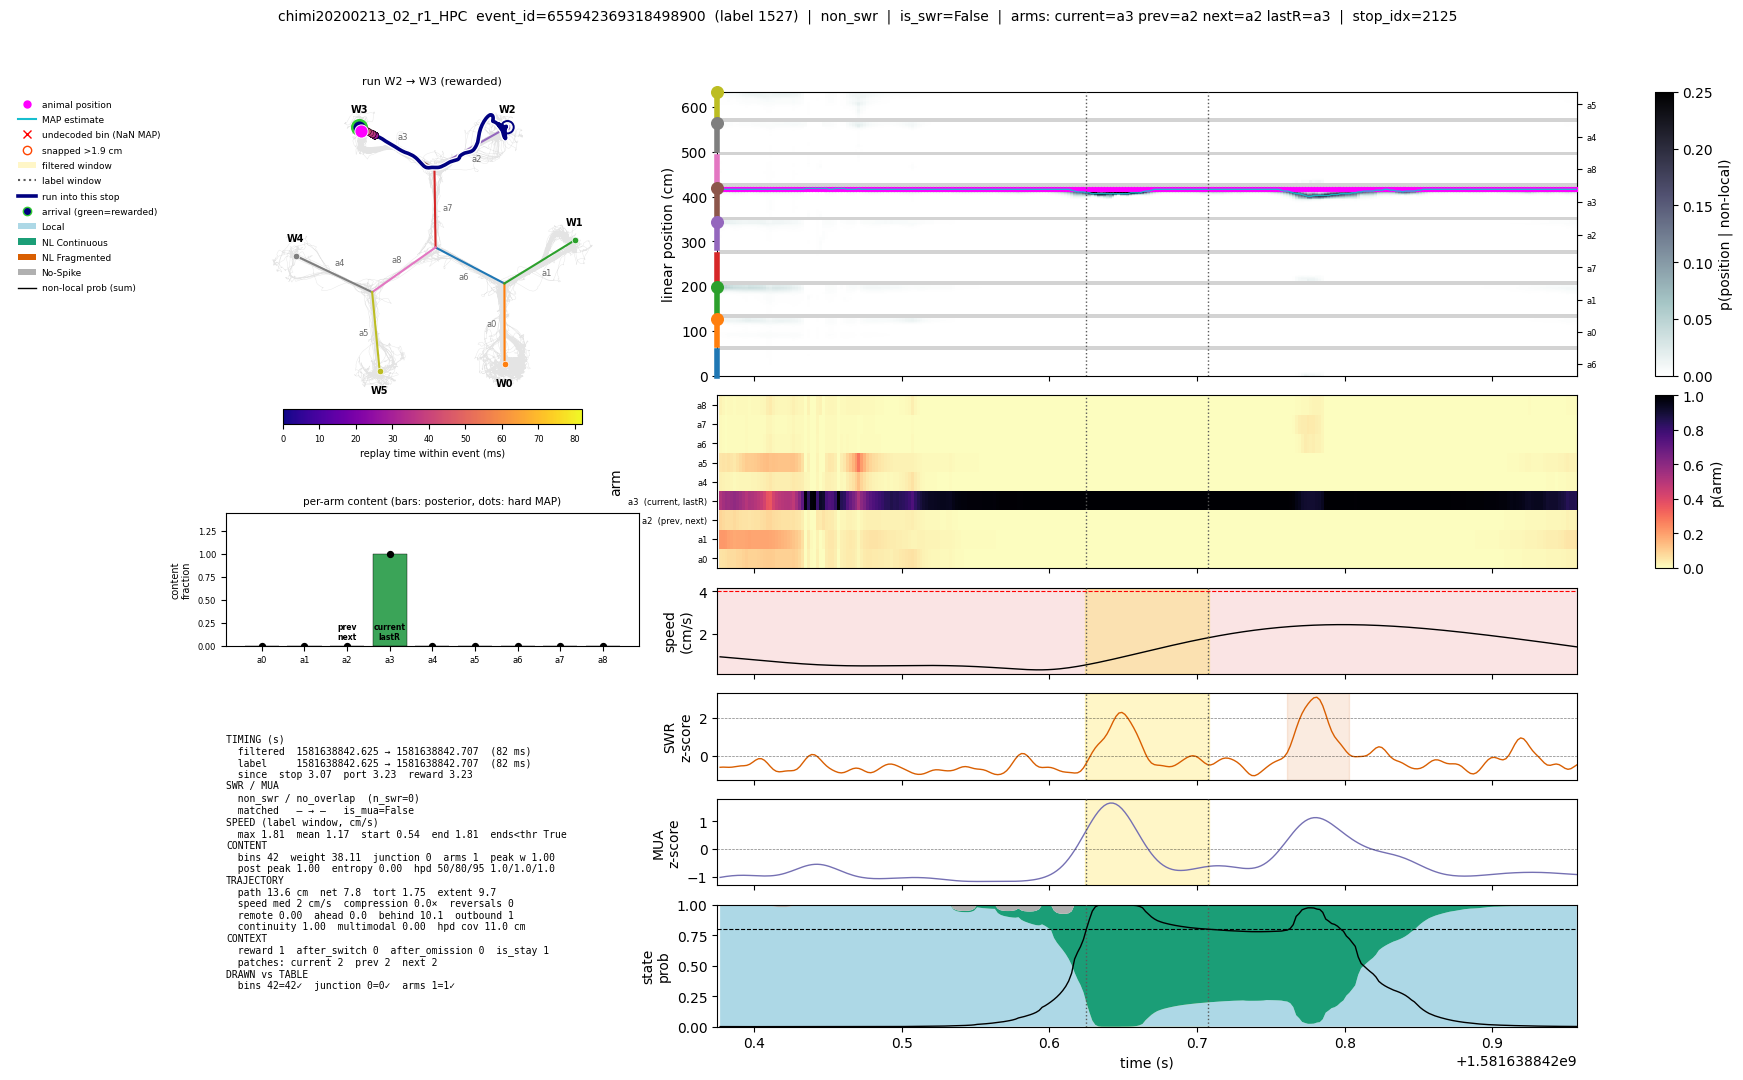

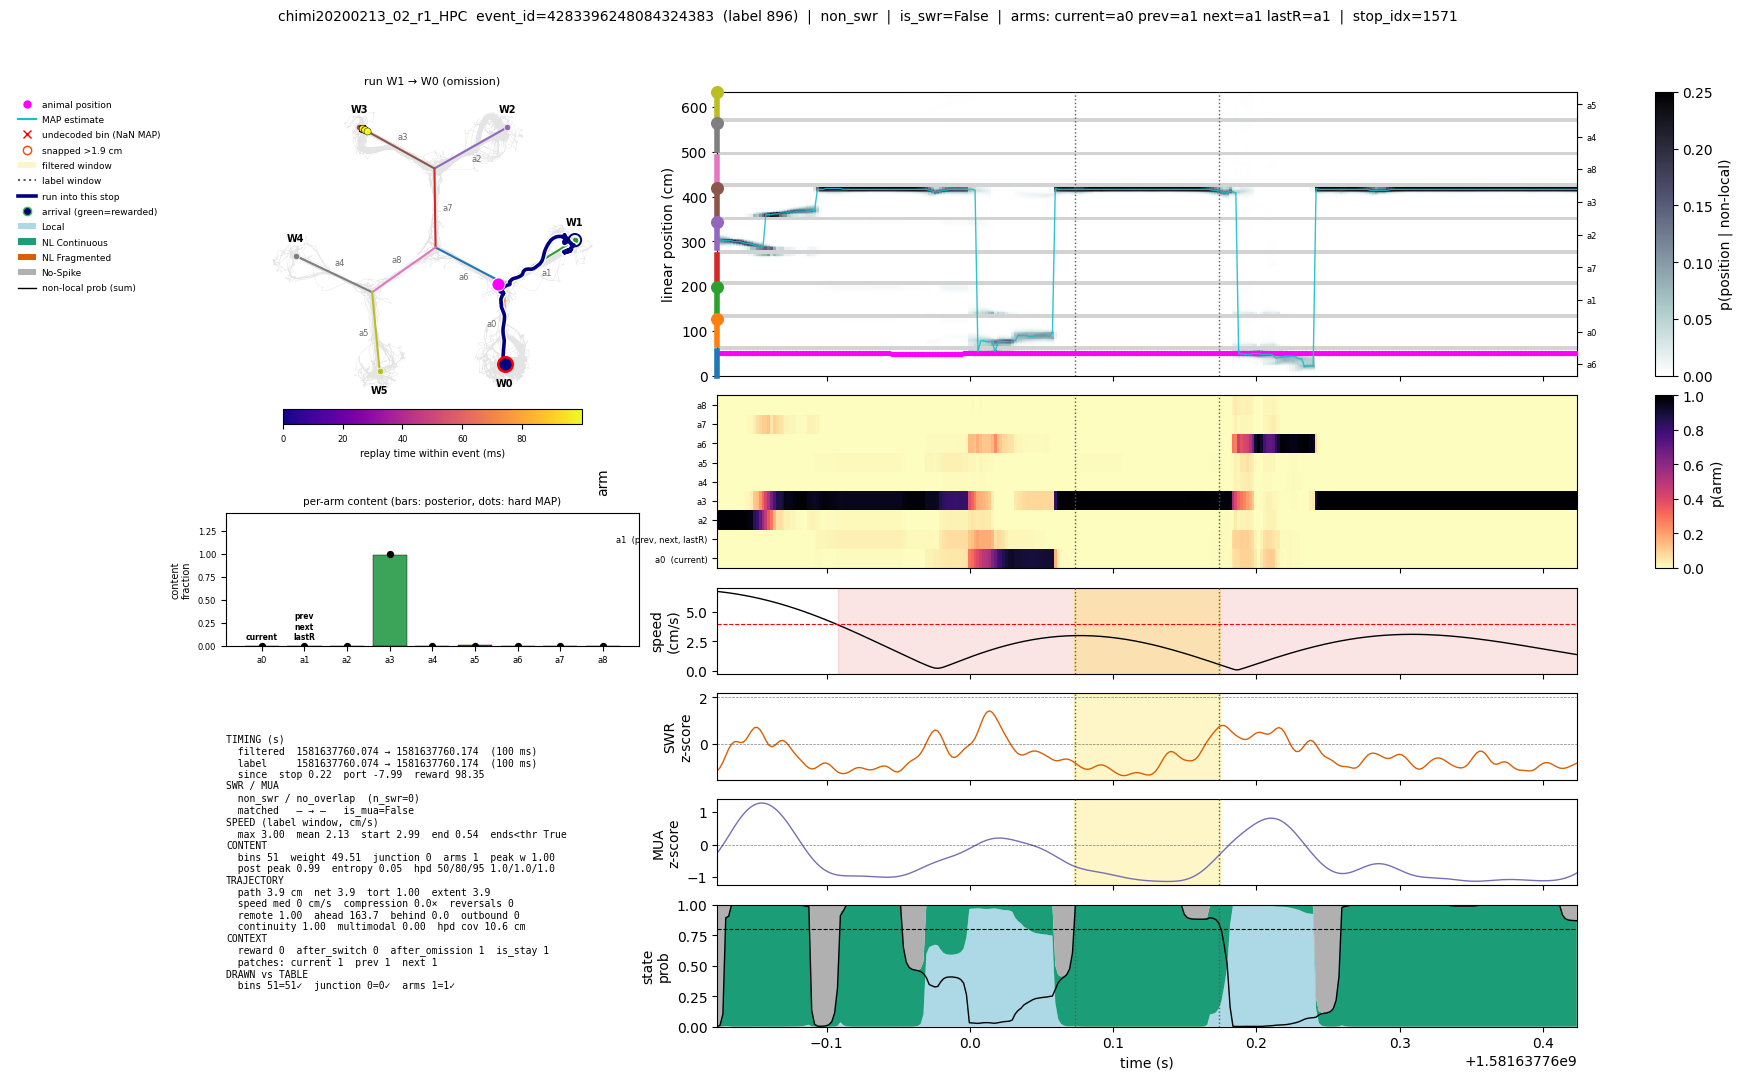

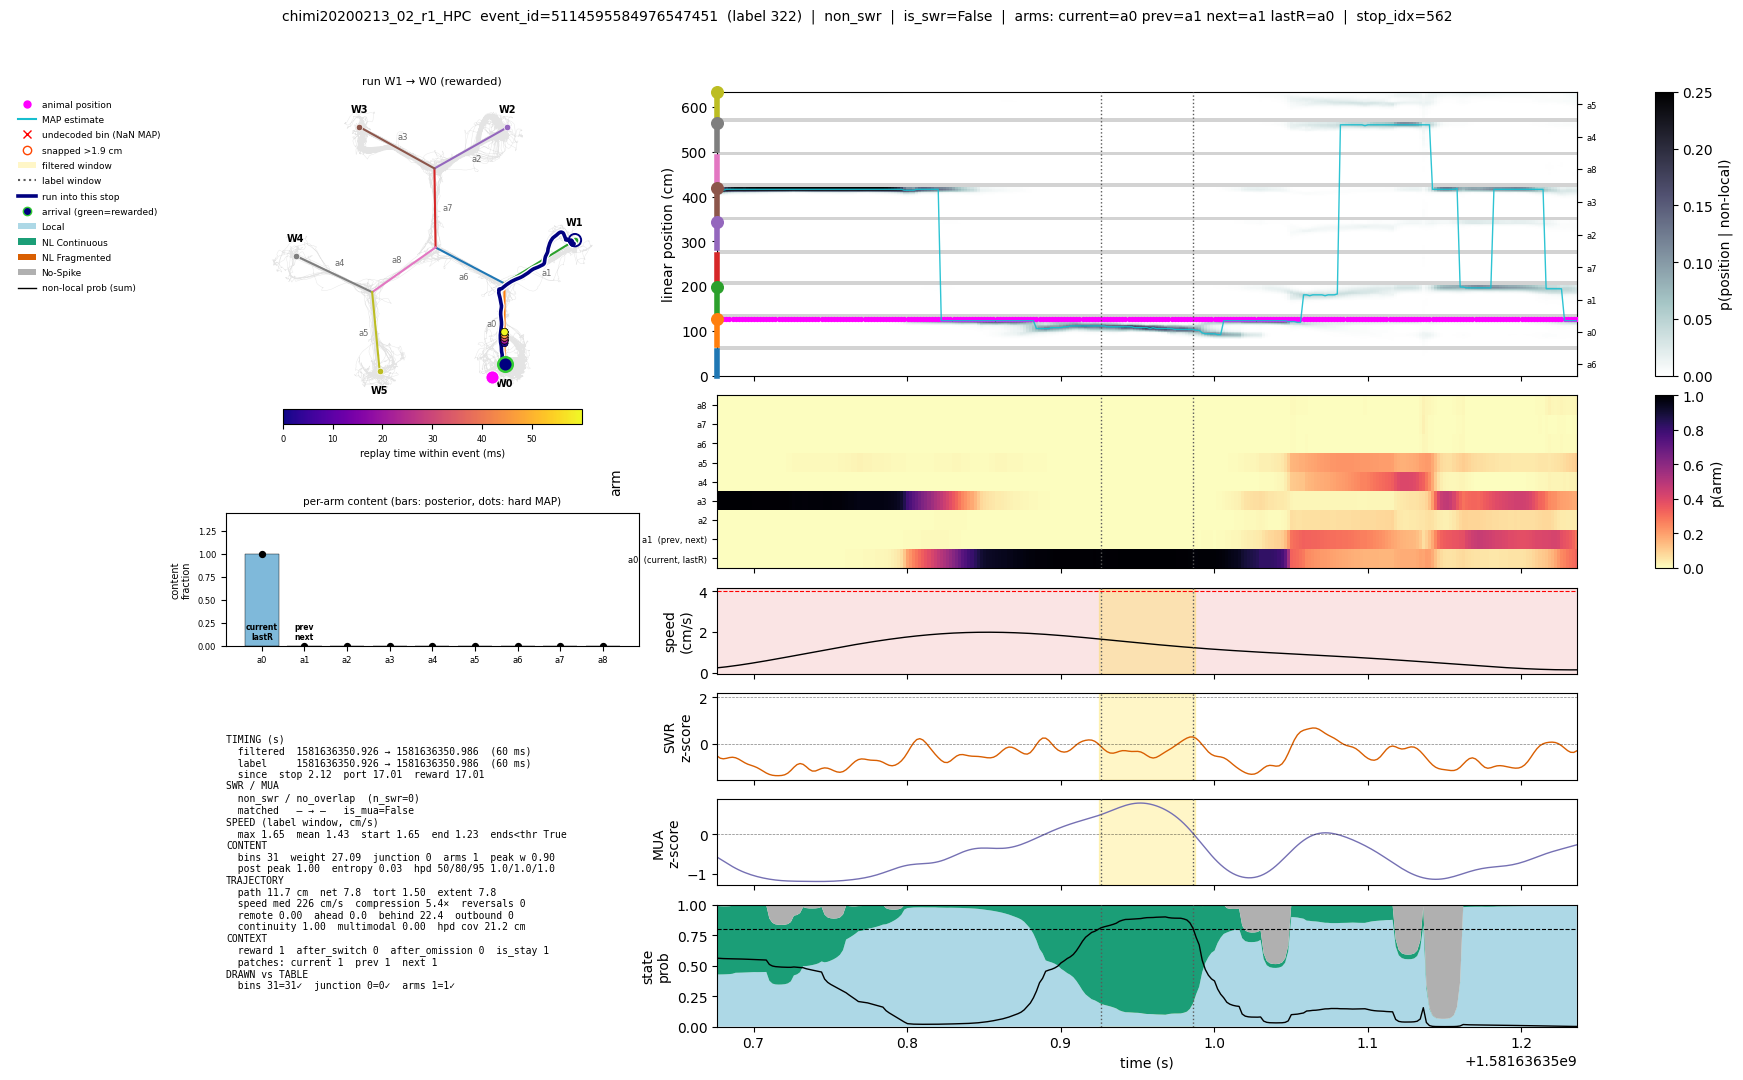

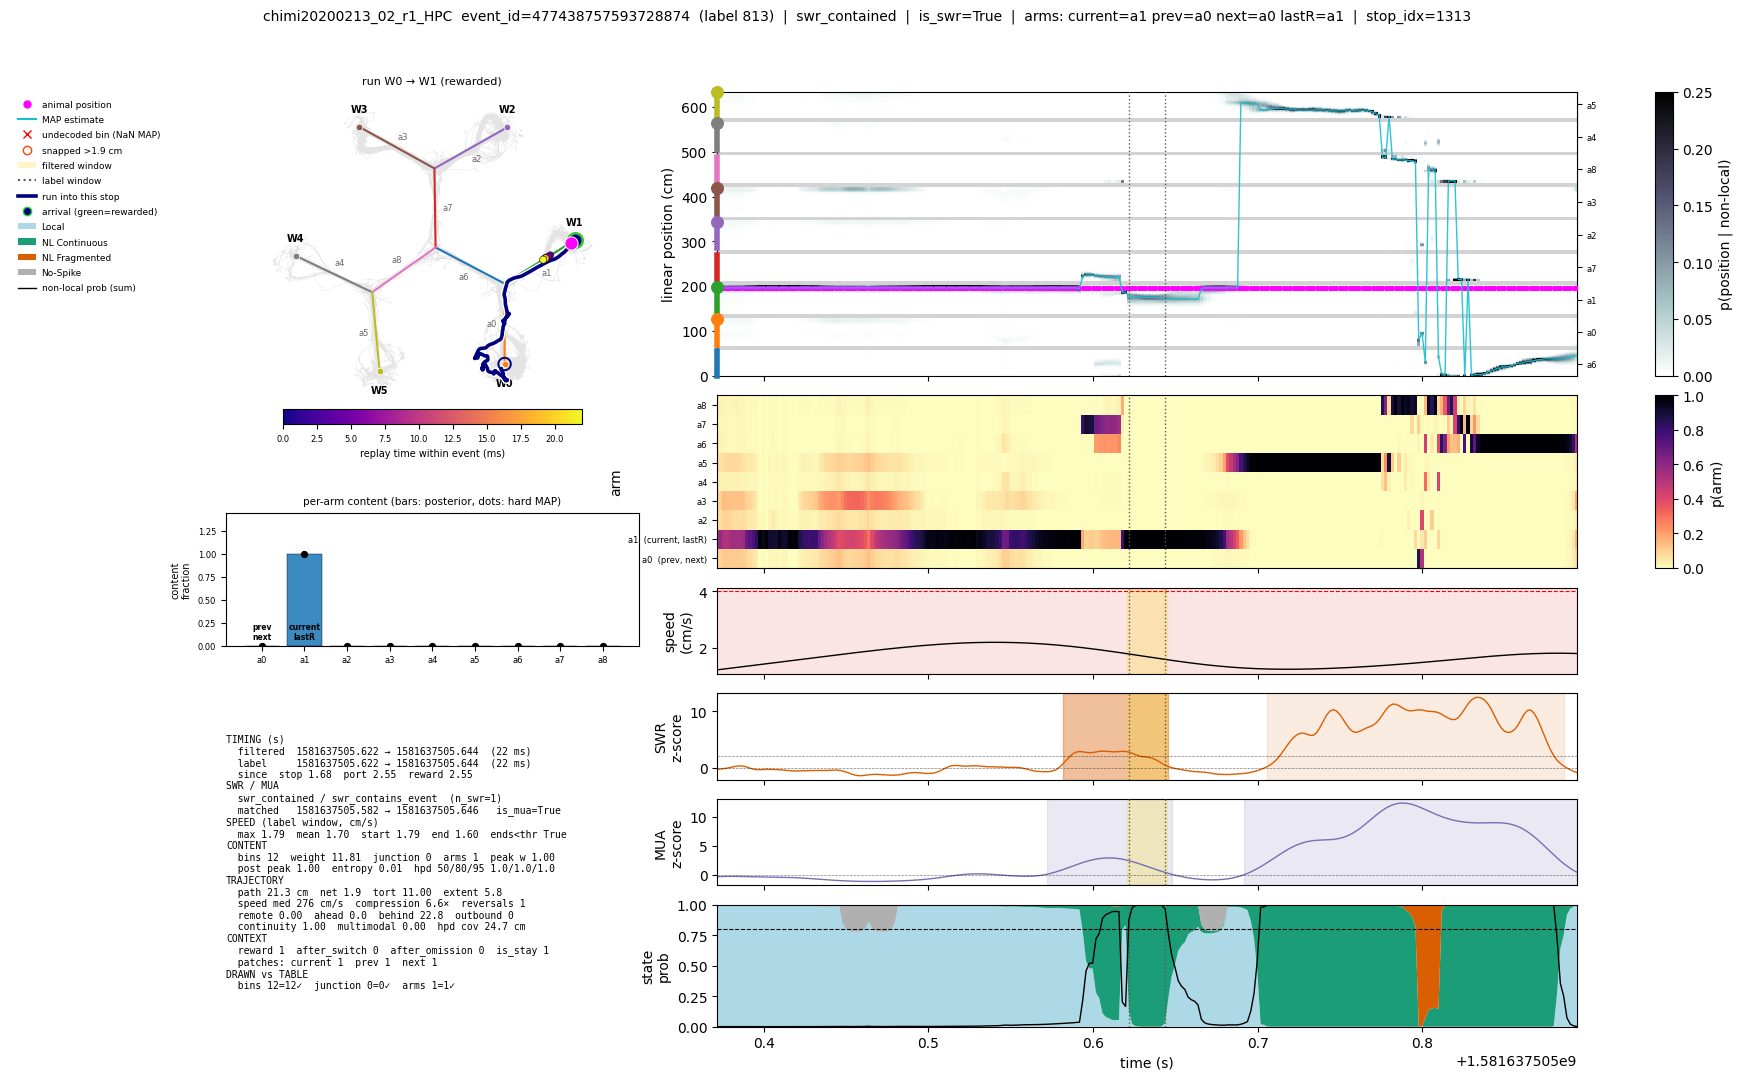

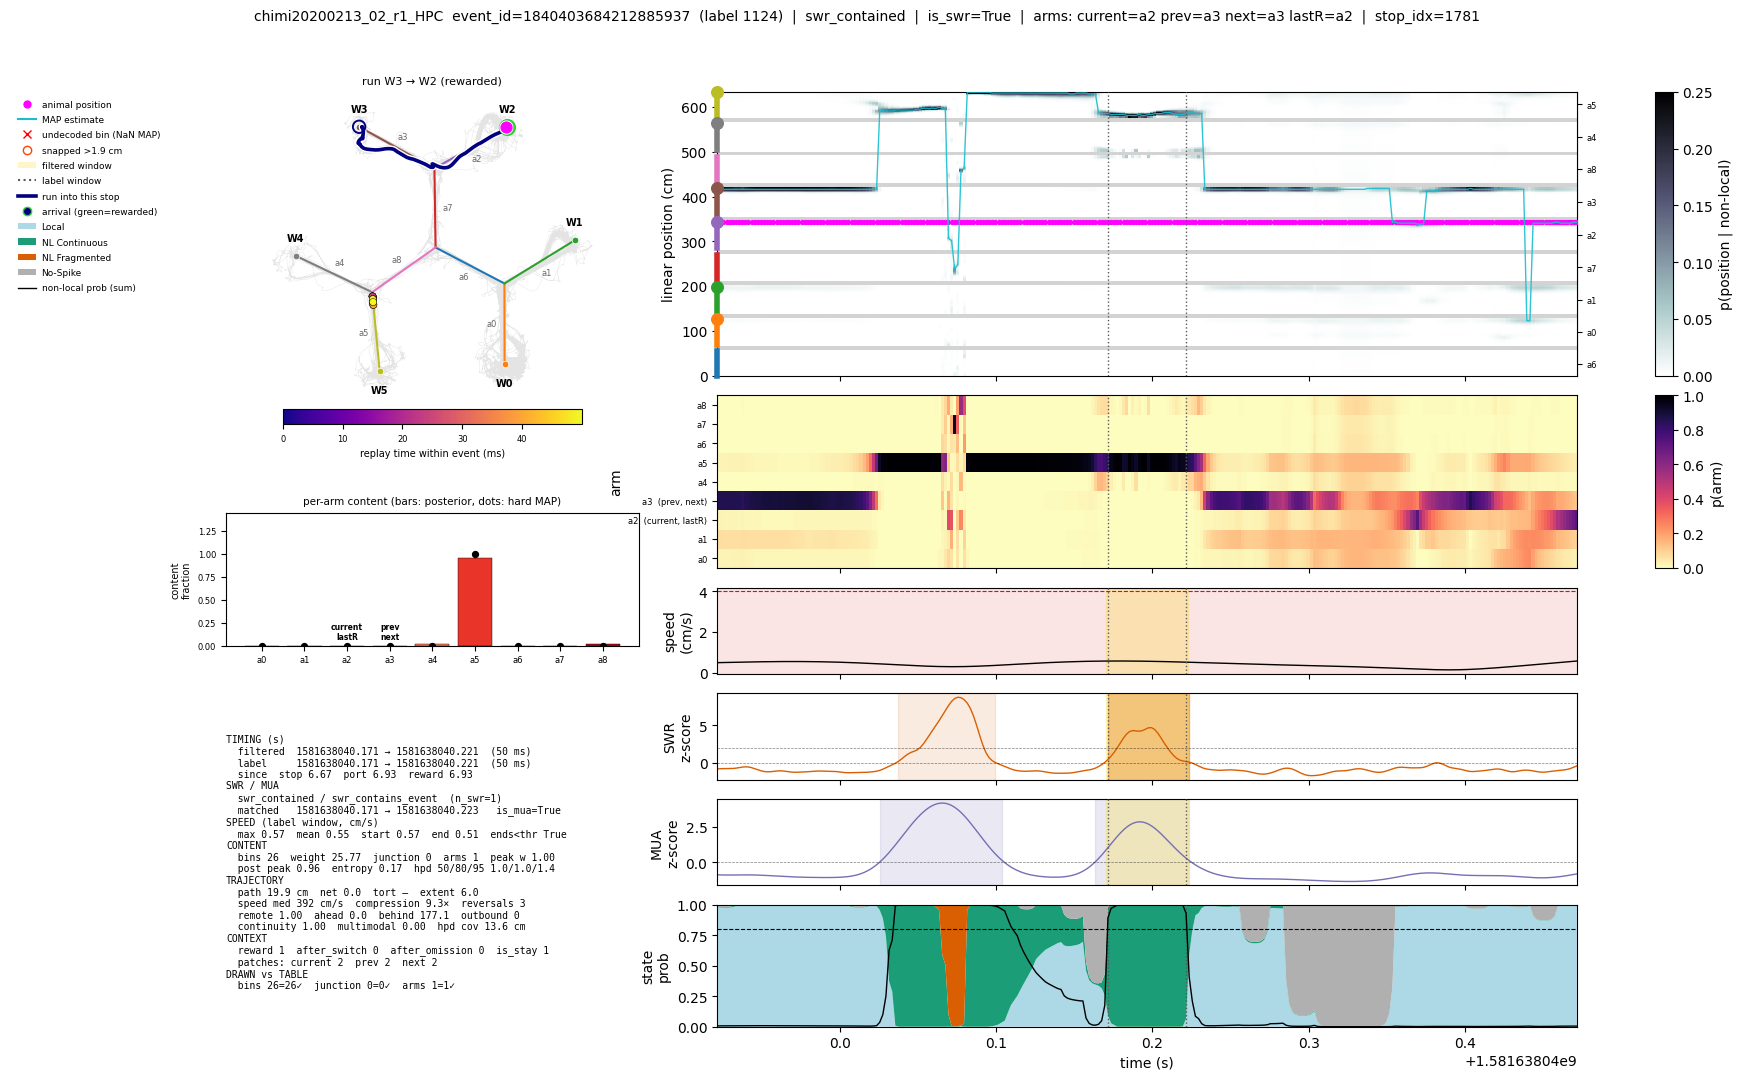

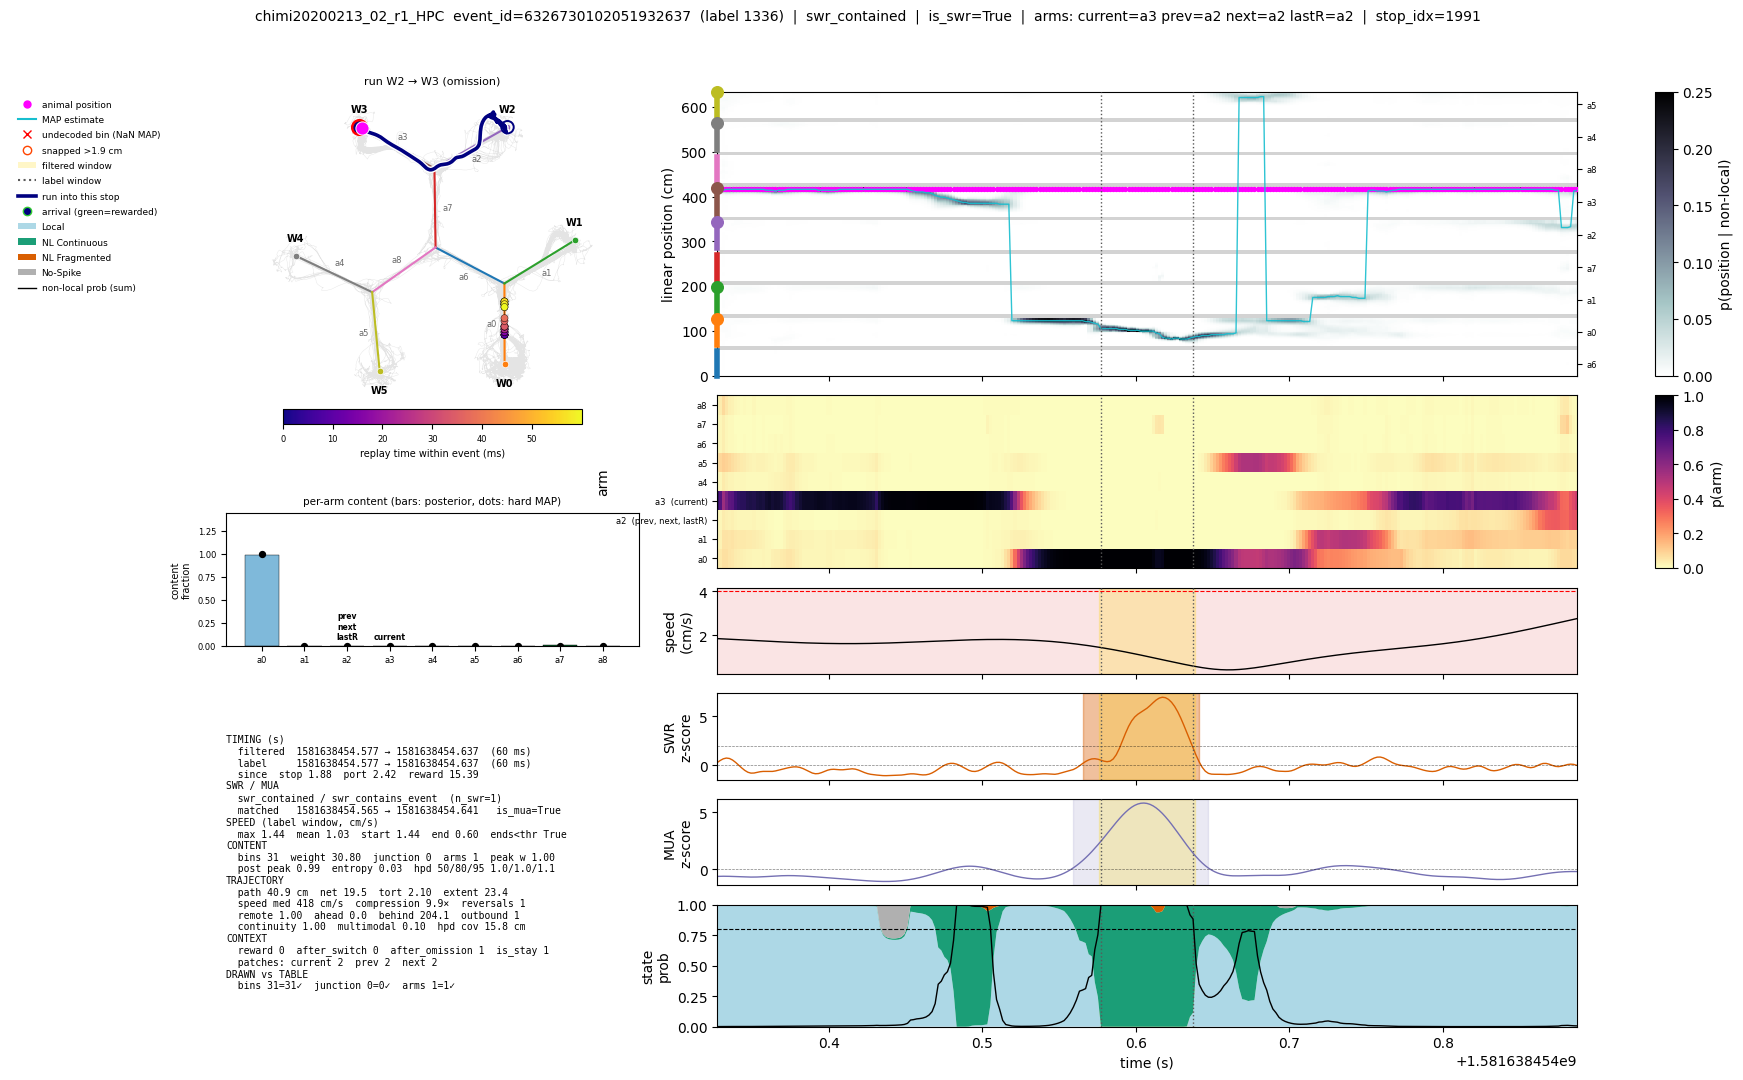

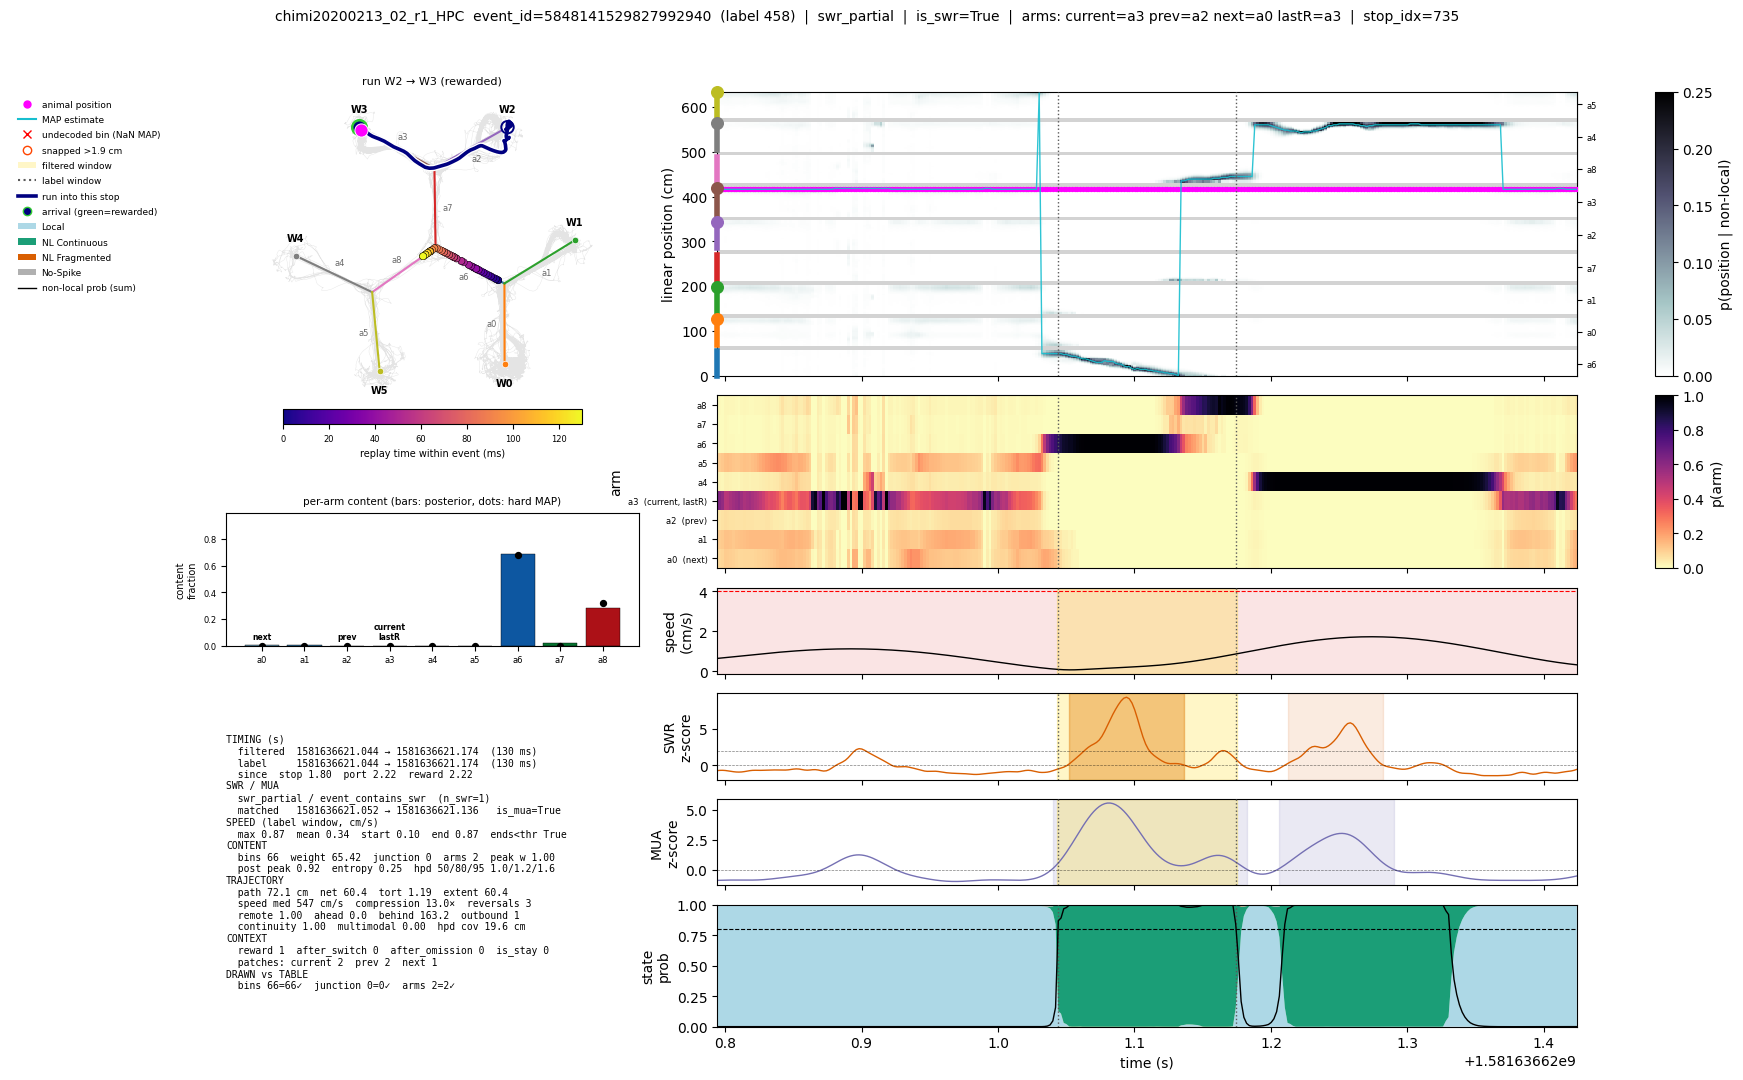

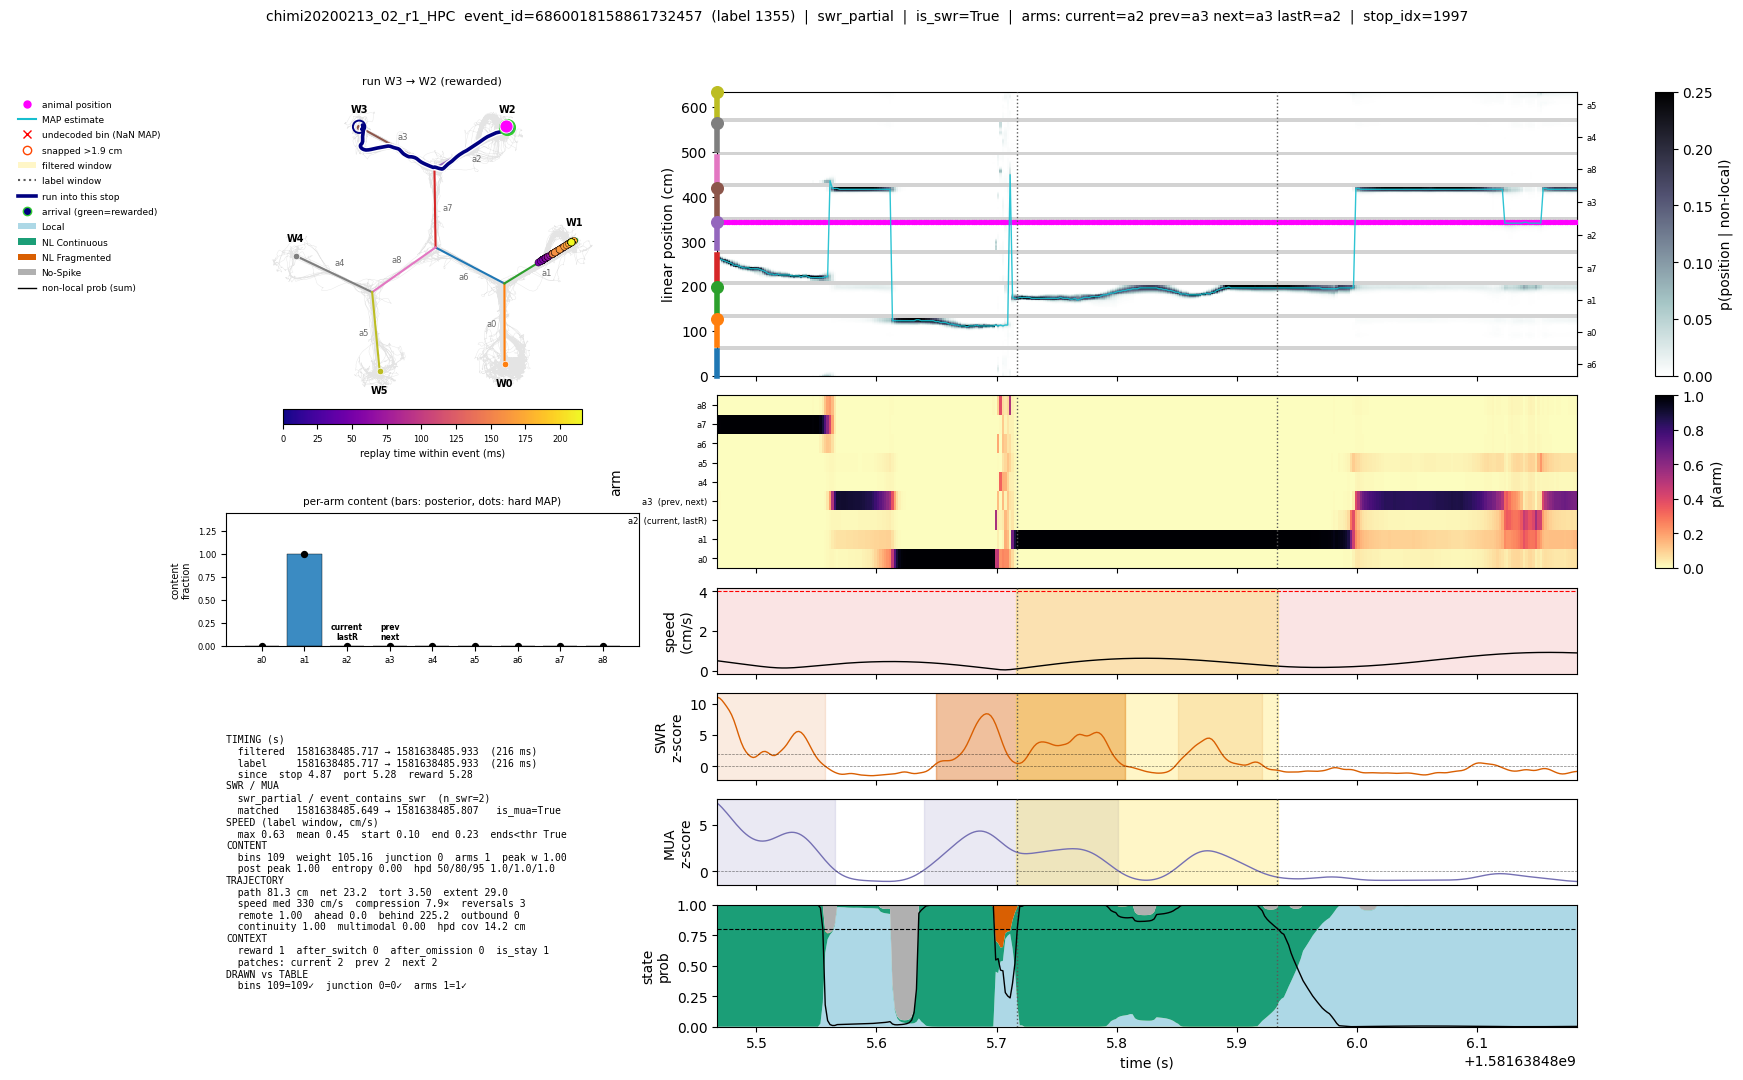

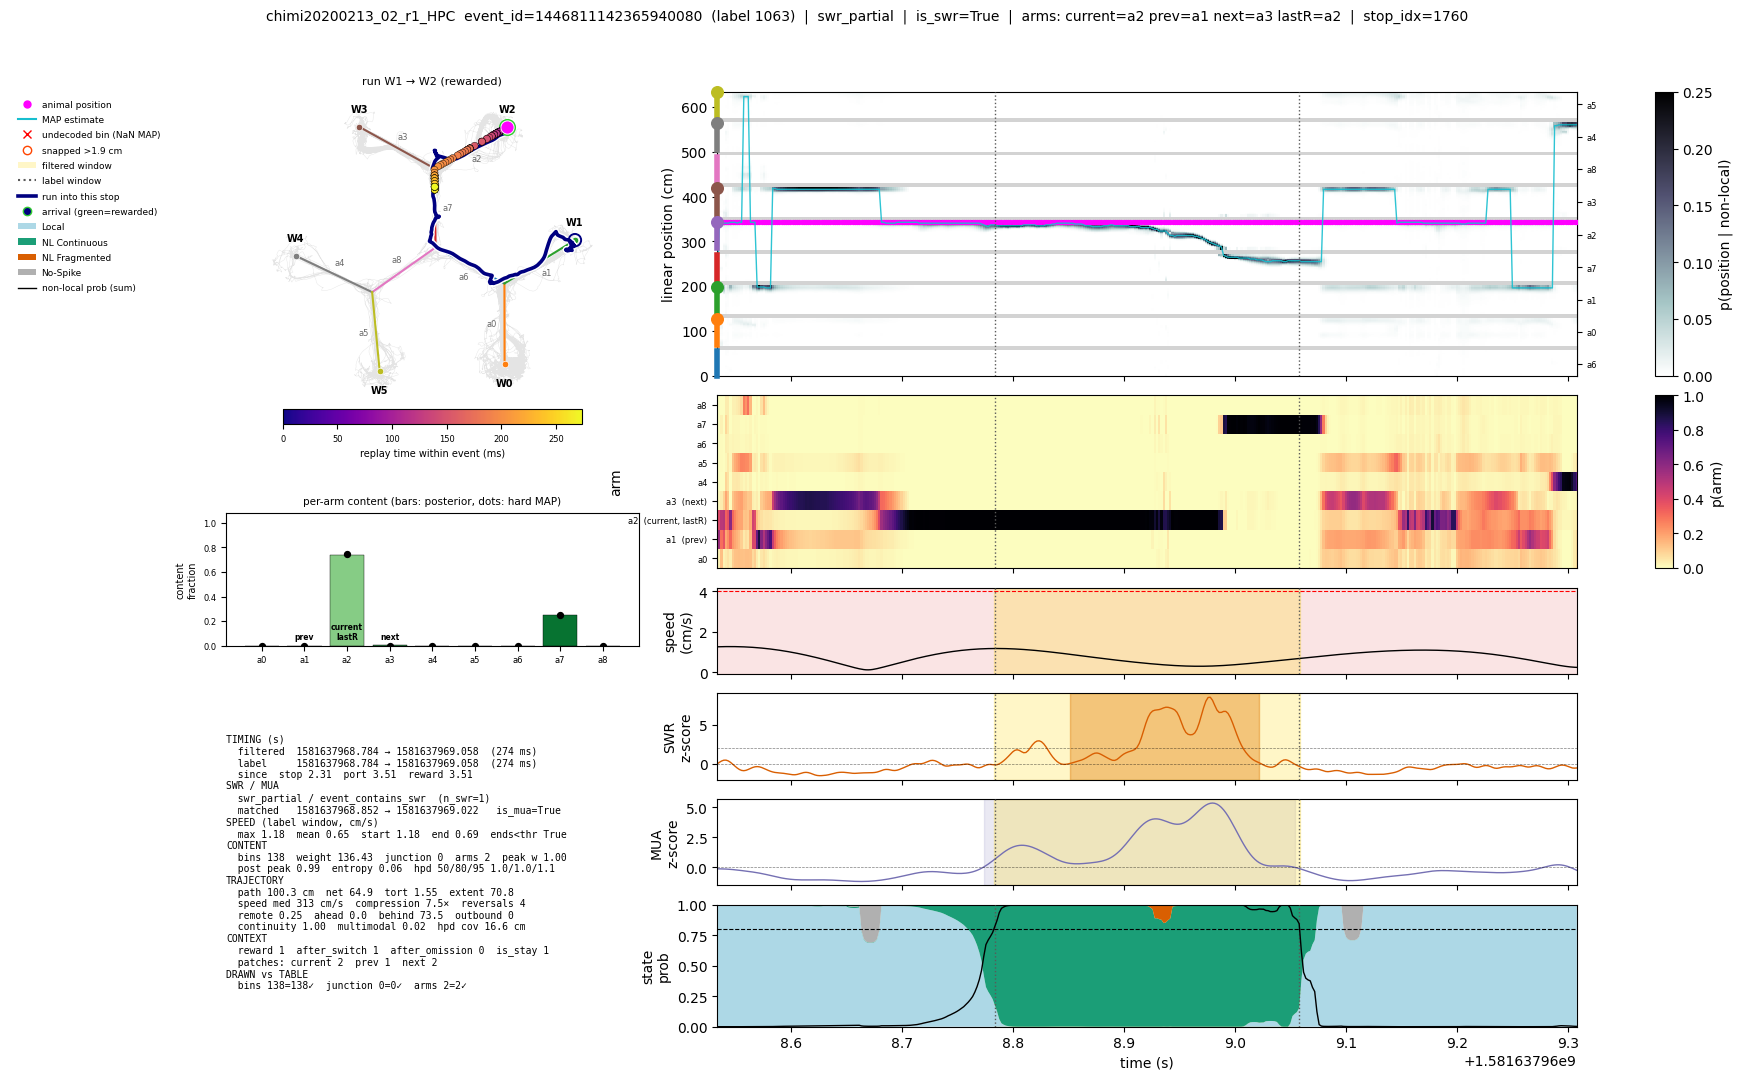

In [26]:
import copy

from matplotlib import patheffects
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from continuum_swr_replay.analysis.constants import (
    DEFAULT_IMMOBILITY_THRESHOLD_CM_PER_SEC,
    DEFAULT_NON_LOCAL_THRESHOLD,
)
from continuum_swr_replay.analysis.event_tables.summaries import posterior_to_arm_marginal
from continuum_swr_replay.visualization.palettes import COLORS, CONTFRAG_COLORS
from continuum_swr_replay.visualization import plot_graph_as_1D
from continuum_swr_replay.visualization.palettes import patch_grouped_arm_palette
from continuum_swr_replay.visualization.plots import plot_track_graph_2d

N_ARMS = 9
ARM_COLORS = patch_grouped_arm_palette()

# Arm id of each track-graph edge *by node identity*: leaf arm w joins well w to
# patch junction 6 + w // 2; trunk arms 6/7/8 join junction 6/7/8 to the center
# node 9 (CLAUDE.md). This is a different naming route than the decoder's
# ``edge_id``, which is what map_estimate_to_arm actually returns — the 2-D
# panel flags any edge where the two disagree.
ARM_OF_EDGE = {frozenset((w, 6 + w // 2)): w for w in range(6)}
ARM_OF_EDGE.update({frozenset((j, 9)): j for j in (6, 7, 8)})

BIN_DF = env.place_bin_centers_nodes_df_
PLACE_BIN_CENTERS = np.asarray(env.place_bin_centers_).squeeze()
IS_TRACK_INTERIOR = np.asarray(env.is_track_interior_).squeeze()
EDGE_ID_PER_BIN = np.asarray(BIN_DF["edge_id"])
WELL_NODES = [n for n in track_graph.nodes if track_graph.degree(n) == 1]

# Real (non-junction) place bins. Junction bins are edge_id == -1 interpolation
# placeholders at edge gaps, not positions — map_estimate_to_arm excludes them
# from its nearest-neighbor lookup, and so do we here.
REAL_BIN = EDGE_ID_PER_BIN >= 0
REAL_LINEAR = np.asarray(BIN_DF["linear_position"], dtype=float)[REAL_BIN]
REAL_XY = np.asarray(BIN_DF.loc[REAL_BIN, ["x_position", "y_position"]], dtype=float)
REAL_EDGE_ID = EDGE_ID_PER_BIN[REAL_BIN]
SNAP_TOLERANCE_CM = float(np.median(np.diff(np.sort(REAL_LINEAR))))

# Linear-position center of each arm, keyed by the decoder's edge_id — the same
# integer map_estimate_to_arm returns and the arm tables index by.
ARM_LINEAR_CENTER = pd.Series(REAL_LINEAR).groupby(REAL_EDGE_ID).mean().to_dict()

STATE_COLUMNS = [
    ("Local_prob", "Local", COLORS["Local"]),
    ("Non-Local_Continuous_prob", "NL Continuous", CONTFRAG_COLORS["Continuous"]),
    ("Non-Local_Fragmented_prob", "NL Fragmented", CONTFRAG_COLORS["Fragmented"]),
    ("No-Spike_prob", "No-Spike", COLORS["No-Spike"]),
]

if PLACE_BIN_CENTERS.shape != IS_TRACK_INTERIOR.shape:
    raise ValueError(
        f"env place-bin axes disagree: centers {PLACE_BIN_CENTERS.shape} "
        f"vs is_track_interior {IS_TRACK_INTERIOR.shape}"
    )
if posterior.shape[1] != PLACE_BIN_CENTERS.size:
    raise ValueError(
        f"posterior has {posterior.shape[1]} place bins; "
        f"env has {PLACE_BIN_CENTERS.size}"
    )
if posterior.shape[0] != len(dot):
    raise ValueError(
        f"posterior has {posterior.shape[0]} timebins but dot has {len(dot)}; "
        "the positional in-event selection below assumes a 1-to-1 time axis"
    )

# The same three-way filter build_event_table applies (_in_event_mask): event
# label set, animal immobile, smoothed non-local posterior over threshold.
# Recomputed here so the shaded "filtered survivor window" is the real one.
NONLOCAL_PROB = dot["Non-Local_Continuous_prob"] + dot["Non-Local_Fragmented_prob"]
IN_EVENT = (
    (dot["non_local_event"] > 0)
    & (dot["head_speed"] < DEFAULT_IMMOBILITY_THRESHOLD_CM_PER_SEC)
    & (NONLOCAL_PROB > DEFAULT_NON_LOCAL_THRESHOLD)
)


def _nearest_real_bin(map_estimate) -> tuple[np.ndarray, np.ndarray]:
    """Nearest real place bin per MAP estimate, and the snap distance in cm.

    Replicates ``map_estimate_to_arm``'s lookup so the drawn arm is the one the
    tables use. The snap distance is the part production discards: a MAP that
    falls in an ``edge_spacing`` gap gets silently pulled to the nearest real
    bin, and a snap much larger than one bin width is how that shows up.
    """
    values = np.asarray(map_estimate, dtype=float)
    index = np.full(values.shape, -1, dtype=int)
    snap = np.full(values.shape, np.nan)
    valid = np.isfinite(values)
    if valid.any():
        distance = np.abs(REAL_LINEAR[None, :] - values[valid, None])
        nearest = distance.argmin(axis=1)
        index[valid] = nearest
        snap[valid] = distance[np.arange(distance.shape[0]), nearest]
    return index, snap


def _decoded_arms(map_estimate) -> tuple[np.ndarray, np.ndarray]:
    """(arm per bin, is-a-real-arm mask), matching production's ALL_ARMS test."""
    bin_index, _ = _nearest_real_bin(map_estimate)
    arms = np.where(bin_index >= 0, REAL_EDGE_ID[np.clip(bin_index, 0, None)], -1)
    is_real = (bin_index >= 0) & np.isin(arms, np.arange(N_ARMS))
    return arms, is_real


def _label_intervals(labels: pd.Series) -> list[tuple[float, float]]:
    """(start, end) seconds for each positive label run in a time-indexed series."""
    positive = labels[labels > 0]
    if not len(positive):
        return []
    return [
        (float(g.index[0]), float(g.index[-1]))
        for _, g in positive.groupby(positive.to_numpy())
    ]


def _current_trial(t: float):
    """Latest trial started at or before ``t`` — the trip the animal is on."""
    started = trials.loc[trials["movement_start_time"] <= t]
    return started.iloc[-1] if len(started) else None


def _fmt(value, spec: str = ".2f", missing: str = "—") -> str:
    """Format a table value, collapsing NaN/None to a dash."""
    try:
        if value is None or pd.isna(value):
            return missing
    except (TypeError, ValueError):
        pass
    if isinstance(value, (bool, np.bool_)):
        return str(bool(value))
    if isinstance(value, str):
        return value
    try:
        return format(value, spec)
    except (TypeError, ValueError):
        return str(value)


def _arm_label(value) -> str:
    return "?" if pd.isna(value) else f"a{int(value)}"


def _arm_roles(row) -> dict[int, list[str]]:
    """arm id -> the predictor roles it plays for this event."""
    roles: dict[int, list[str]] = {}
    for column, tag in (
        ("current_arm", "current"),
        ("prev_arm", "prev"),
        ("next_arm", "next"),
        ("last_rewarded_arm", "lastR"),
    ):
        value = row[column]
        if pd.notna(value):
            roles.setdefault(int(value), []).append(tag)
    return roles


def _plot_2d_context(ax, fig, row, pos_win, event_bins) -> None:
    """2-D track: the run into this stop, the animal, and the decoded replay."""
    plot_track_graph_2d(track_graph, position_info, ax=ax, edge_order=linear_edge_order)
    node_pos = {n: track_graph.nodes[n]["pos"] for n in track_graph.nodes}

    for node in WELL_NODES:
        x, y = node_pos[node]
        below = node in (0, 5)  # bottom wells — label under, not over the markers
        ax.annotate(
            f"W{node}",
            (x, y),
            fontsize=7,
            fontweight="bold",
            ha="center",
            va="top" if below else "bottom",
            xytext=(0, -10 if below else 9),
            textcoords="offset points",
        )

    # Arm ids from the decoder's edge_id (what the tables index by). If the
    # node-identity naming in CLAUDE.md disagrees for an edge, print both —
    # a silent mismatch there would misalign every per-arm predictor.
    for n1, n2 in track_graph.edges:
        edge_id = track_graph.edges[n1, n2].get("edge_id")
        node_arm = ARM_OF_EDGE.get(frozenset((n1, n2)))
        if edge_id is None:
            continue
        text = f"a{int(edge_id)}"
        if node_arm is not None and int(edge_id) != node_arm:
            text += f" (node-id a{node_arm})"
        (x1, y1), (x2, y2) = node_pos[n1], node_pos[n2]
        dx, dy = x2 - x1, y2 - y1
        norm = float(np.hypot(dx, dy)) or 1.0
        ax.annotate(
            text,
            ((x1 + x2) / 2, (y1 + y2) / 2),
            fontsize=6,
            color="dimgray",
            ha="center",
            va="center",
            xytext=(-9 * dy / norm, 9 * dx / norm),  # perpendicular to the edge
            textcoords="offset points",
        )

    trial = _current_trial(float(row["event_start"]))
    if trial is not None:
        run_end = trial.get("destination_first_poke_in_time")
        if run_end is None or pd.isna(run_end):
            run_end = trial["end_time"]
        run = position_info.loc[trial["movement_start_time"] : run_end]
        if len(run):
            ax.plot(
                run["head_position_x"],
                run["head_position_y"],
                color="navy",
                lw=2.6,
                zorder=5,
                solid_capstyle="round",
                path_effects=[
                    patheffects.Stroke(linewidth=4.6, foreground="white"),
                    patheffects.Normal(),
                ],
            )
        from_well, to_well = int(trial["from_well"]), int(trial["to_well"])
        rewarded = bool(trial["is_reward"])
        if from_well in node_pos:  # departure: open ring
            ax.scatter(
                *node_pos[from_well],
                s=80,
                facecolor="none",
                edgecolor="navy",
                linewidth=1.4,
                zorder=6,
            )
        if to_well in node_pos:  # arrival: filled, rimmed by trial outcome
            ax.scatter(
                *node_pos[to_well],
                s=110,
                facecolor="navy",
                edgecolor="limegreen" if rewarded else "red",
                linewidth=1.8,
                zorder=6,
            )
        ax.set_title(
            f"run W{from_well} → W{to_well} "
            f"({'rewarded' if rewarded else 'omission'})",
            fontsize=8,
        )
    else:
        ax.set_title("run W? → W? (no trial started yet)", fontsize=8)

    # The decoded replay itself, in physical space: each in-event MAP bin's 2-D
    # coordinate, colored by time within the event. The linearized view can make
    # a jump across a linearization discontinuity look continuous; this can't.
    if len(event_bins):
        bin_index, _ = _nearest_real_bin(event_bins["map_estimate"].to_numpy())
        drawn = bin_index >= 0
        if drawn.any():
            xy = REAL_XY[bin_index[drawn]]
            elapsed = (
                event_bins.index.to_numpy()[drawn] - float(event_bins.index[0])
            ) * 1e3
            ax.plot(xy[:, 0], xy[:, 1], color="black", lw=0.6, alpha=0.5, zorder=7)
            replay = ax.scatter(
                xy[:, 0],
                xy[:, 1],
                c=elapsed,
                cmap="plasma",
                s=26,
                edgecolor="black",
                linewidth=0.3,
                zorder=8,
            )
            bar = fig.colorbar(
                replay, ax=ax, orientation="horizontal", fraction=0.045, pad=0.02
            )
            bar.set_label("replay time within event (ms)", fontsize=7)
            bar.ax.tick_params(labelsize=6)

    # The animal during the event — immobile, so ~a point.
    if len(pos_win):
        nearest = int(
            np.argmin(
                np.abs(pos_win.index.to_numpy() - row["label_event_midpoint_time"])
            )
        )
        ax.scatter(
            pos_win["head_position_x"].iloc[nearest],
            pos_win["head_position_y"].iloc[nearest],
            s=90,
            facecolor="magenta",
            edgecolor="white",
            linewidth=0.7,
            zorder=9,
        )


def _plot_arm_content(ax, arm_fraction, hard_fraction, roles) -> None:
    """Per-arm content for this event: posterior-weighted bars vs hard MAP counts.

    Bars are the event's summed arm-marginal posterior, renormalized — the soft
    content. Black dots are the fraction of in-event bins whose MAP arm was that
    arm — the hard content the primary regressions use. The two should track each
    other; a large divergence on an arm means the MAP and the mass disagree.
    """
    arms = np.arange(N_ARMS)
    ax.bar(
        arms,
        arm_fraction,
        color=[ARM_COLORS[a] for a in arms],
        edgecolor="black",
        linewidth=0.3,
    )
    ax.scatter(arms, hard_fraction, s=18, color="black", zorder=3)
    ax.set_xticks(arms)
    ax.set_xticklabels([f"a{a}" for a in arms], fontsize=6)
    ax.tick_params(axis="y", labelsize=6)
    ax.set_ylabel("content\nfraction", fontsize=7)
    ax.set_ylim(0, max(1e-9, float(np.nanmax([*arm_fraction, *hard_fraction]))) * 1.45)
    ax.set_title("per-arm content (bars: posterior, dots: hard MAP)", fontsize=7.5)
    for arm, tags in roles.items():
        if 0 <= arm < N_ARMS:
            ax.annotate(
                "\n".join(tags),
                (arm, 0),
                xytext=(0, 3),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=5.5,
                color="black",
                fontweight="bold",
            )


def _event_report(row, drawn) -> str:
    """Monospace dump of the table row this figure is drawing, plus the checks."""
    short = {
        "n_nonlocal_bins": "bins",
        "n_junction_bins": "junction",
        "n_unique_arms": "arms",
    }
    checks = "  ".join(
        f"{short.get(name, name)} {value}"
        f"{'=' if value == int(row[name]) else '≠'}{int(row[name])}"
        f"{'✓' if value == int(row[name]) else '✗'}"
        for name, value in drawn.items()
    )
    return "\n".join(
        [
            "TIMING (s)",
            f"  filtered  {_fmt(row['event_start'], '.3f')} → "
            f"{_fmt(row['event_end'], '.3f')}"
            f"  ({_fmt(row['event_duration'] * 1e3, '.0f')} ms)",
            f"  label     {_fmt(row['label_event_start'], '.3f')} → "
            f"{_fmt(row['label_event_end'], '.3f')}"
            f"  ({_fmt(row['label_event_duration'] * 1e3, '.0f')} ms)",
            f"  since  stop {_fmt(row['time_since_stop'])}"
            f"  port {_fmt(row['time_since_port_entry'])}"
            f"  reward {_fmt(row['time_since_reward'])}",
            "SWR / MUA",
            f"  {row['overlap_class']} / {row['overlap_subclass']}"
            f"  (n_swr={_fmt(row['n_swrs_overlapping'], 'd')})",
            f"  matched   {_fmt(row['matched_swr_start'], '.3f')} → "
            f"{_fmt(row['matched_swr_end'], '.3f')}   is_mua={_fmt(row['is_mua'])}",
            "SPEED (label window, cm/s)",
            f"  max {_fmt(row['max_speed'])}  mean {_fmt(row['mean_speed'])}"
            f"  start {_fmt(row['start_speed'])}  end {_fmt(row['end_speed'])}"
            f"  ends<thr {_fmt(row['endpoints_speed_below_thresh'])}",
            "CONTENT",
            f"  bins {_fmt(row['n_nonlocal_bins'], 'd')}"
            f"  weight {_fmt(row['nonlocal_weight_sum'])}"
            f"  junction {_fmt(row['n_junction_bins'], 'd')}"
            f"  arms {_fmt(row['n_unique_arms'], 'd')}"
            f"  peak w {_fmt(row['peak_nonlocal_prob'])}",
            f"  post peak {_fmt(row['posterior_peak_mean'])}"
            f"  entropy {_fmt(row['posterior_entropy_mean'])}"
            f"  hpd 50/80/95 {_fmt(row['posterior_hpd_width_50'], '.1f')}/"
            f"{_fmt(row['posterior_hpd_width_80'], '.1f')}/"
            f"{_fmt(row['posterior_hpd_width_95'], '.1f')}",
            "TRAJECTORY",
            f"  path {_fmt(row['path_length'], '.1f')} cm"
            f"  net {_fmt(row['net_displacement'], '.1f')}"
            f"  tort {_fmt(row['tortuosity'])}"
            f"  extent {_fmt(row['spatial_extent'], '.1f')}",
            f"  speed med {_fmt(row['replay_speed_median'], '.0f')} cm/s"
            f"  compression {_fmt(row['compression_factor'], '.1f')}×"
            f"  reversals {_fmt(row['n_reversals'], 'd')}",
            f"  remote {_fmt(row['remote_fraction'])}"
            f"  ahead {_fmt(row['max_ahead'], '.1f')}"
            f"  behind {_fmt(row['max_behind'], '.1f')}"
            f"  outbound {_fmt(row['is_outbound'], '.0f')}",
            f"  continuity {_fmt(row['path_continuity'])}"
            f"  multimodal {_fmt(row['multimodal_fraction'])}"
            f"  hpd cov {_fmt(row['hpd_coverage_cm'], '.1f')} cm",
            "CONTEXT",
            f"  reward {_fmt(row['reward_outcome'], '.0f')}"
            f"  after_switch {_fmt(row['is_after_switch'], '.0f')}"
            f"  after_omission {_fmt(row['is_after_omission'], '.0f')}"
            f"  is_stay {_fmt(row['is_stay'], '.0f')}",
            f"  patches: current {_fmt(row['current_patch'], '.0f')}"
            f"  prev {_fmt(row['prev_patch'], '.0f')}"
            f"  next {_fmt(row['next_patch'], '.0f')}",
            "DRAWN vs TABLE",
            f"  {checks}",
        ]
    )


def plot_event(
    event_id: int,
    *,
    pad: float = 0.25,
    center: float | None = None,
    half_width: float | None = None,
    posterior_max: float = 0.25,
    strict: bool = False,
    figsize: tuple[float, float] = (17.5, 11.0),
):
    """Plot one non-local event with the pipeline's intermediates exposed.

    Left region, top to bottom: the 2-D track (run into this stop, the animal,
    and the decoded replay colored by time), the per-arm content bars, and a
    dump of the ``event_table`` row this figure is drawing. The right column is
    six time-aligned rows:

    1. conditional posterior over linear position, the animal's real position,
       and the MAP estimate (undecoded / snapped bins flagged)
    2. arm-marginal posterior (9 arms), y-labels tagged with this event's
       ``current`` / ``prev`` / ``next`` / ``lastR`` predictor arms
    3. head speed vs the immobility threshold
    4. SWR z-score, all SWR intervals faint, the matched one solid
    5. MUA z-score, MUA intervals shaded
    6. the 4-state posterior stack with the non-local sum and its threshold

    Both event windows are drawn on every time row: the **label window**
    (detector's full event, dotted verticals) and the **filtered survivor
    window** (gold span) that feeds the content tables.

    Parameters
    ----------
    event_id : int
        Canonical ``event_table["event_id"]`` hash.
    pad : float, default 0.25
        Seconds of context on each side of the label window. Ignored when
        ``half_width`` is given.
    center, half_width : float, optional
        Override the window. ``center`` defaults to the label-window midpoint,
        ``half_width`` to half the label duration plus ``pad``.
    posterior_max : float, default 0.25
        Colormap ceiling for the conditional posterior.
    strict : bool, default False
        Raise when the drawn bin counts disagree with the table row. Off by
        default so a mismatch still renders — the figure is what you need to
        diagnose it — but the report panel marks it ✗ and it prints to stdout.

    Returns
    -------
    matplotlib.figure.Figure
    """
    match = event_table.loc[event_table["event_id"] == event_id]
    if len(match) != 1:
        raise KeyError(
            f"expected exactly 1 event_table row for event_id={event_id}, "
            f"got {len(match)}"
        )
    row = match.iloc[0]

    if center is None:
        center = 0.5 * (row["label_event_start"] + row["label_event_end"])
    if half_width is None:
        half_width = 0.5 * (row["label_event_end"] - row["label_event_start"]) + pad
    t_start, t_stop = float(center - half_width), float(center + half_width)

    dot_win = dot.loc[t_start:t_stop]
    pos_win = position_info.loc[t_start:t_stop]
    event_mask = (
        IN_EVENT & (dot["non_local_event"] == row["non_local_event"])
    ).to_numpy()
    event_bins = dot.loc[event_mask]

    fig = plt.figure(figsize=figsize)
    # Column 0 is a blank axes holding the key, so the legend is outside every
    # data panel. Column 1 stacks the 2-D track, the content bars, and the row
    # report. Column 3 holds colorbars aligned to the first two time rows.
    gs = GridSpec(
        1,
        4,
        figure=fig,
        width_ratios=[0.40, 1.20, 2.5, 0.05],
        wspace=0.22,
        left=0.01,
        right=0.96,
        top=0.90,
        bottom=0.05,
    )
    heights = [2.8, 1.7, 0.85, 0.85, 0.85, 1.2]
    gs_left = gs[1].subgridspec(3, 1, height_ratios=[2.5, 1.0, 2.2], hspace=0.35)
    gs_rows = gs[2].subgridspec(6, 1, height_ratios=heights, hspace=0.14)
    gs_cbar = gs[3].subgridspec(6, 1, height_ratios=heights, hspace=0.14)

    ax_legend = fig.add_subplot(gs[0])
    ax_legend.axis("off")
    ax_2d = fig.add_subplot(gs_left[0])
    ax_arm_bar = fig.add_subplot(gs_left[1])
    ax_report = fig.add_subplot(gs_left[2])
    ax_report.axis("off")
    ax_post = fig.add_subplot(gs_rows[0])
    ax_arm = fig.add_subplot(gs_rows[1], sharex=ax_post)
    ax_speed = fig.add_subplot(gs_rows[2], sharex=ax_post)
    ax_swr = fig.add_subplot(gs_rows[3], sharex=ax_post)
    ax_mua = fig.add_subplot(gs_rows[4], sharex=ax_post)
    ax_state = fig.add_subplot(gs_rows[5], sharex=ax_post)
    time_axes = [ax_post, ax_arm, ax_speed, ax_swr, ax_mua, ax_state]

    post_win = posterior.sel(time=slice(t_start, t_stop))
    post_raw = np.asarray(post_win.values, dtype=float)
    post_times = np.asarray(post_win["time"].values, dtype=float)

    # --- Row 1: posterior over position, the animal, and the MAP estimate ---
    # NOTE: load_conditional_posterior forward-fills timebins with negligible
    # non-local mass, so outside the event the heatmap shows the last valid
    # distribution, not new evidence. Read it together with the state row.
    post_display = post_raw.copy()
    post_display[:, ~IS_TRACK_INTERIOR] = np.nan
    cmap = copy.copy(plt.get_cmap("bone_r"))
    cmap.set_bad(color="lightgray", alpha=1.0)
    time_mesh, position_mesh = np.meshgrid(post_times, PLACE_BIN_CENTERS)
    mesh = ax_post.pcolormesh(
        time_mesh,
        position_mesh,
        post_display.T,
        vmin=0.0,
        vmax=posterior_max,
        cmap=cmap,
        rasterized=True,
    )
    fig.colorbar(mesh, cax=fig.add_subplot(gs_cbar[0]), label="p(position | non-local)")
    ax_post.scatter(
        pos_win.index,
        pos_win["linear_position"],
        s=8,
        color="magenta",
        zorder=3,
        rasterized=True,
    )

    # MAP estimate with the two failure modes the arm columns can hide:
    # undecoded bins (NaN map_estimate -> NaN decoded_arm, counted in
    # n_junction_bins) and bins snapped across a linearization gap to a real
    # arm more than one place bin away.
    map_estimate = dot_win["map_estimate"].to_numpy()
    _, snap = _nearest_real_bin(map_estimate)
    ax_post.plot(
        dot_win.index, map_estimate, color="tab:cyan", lw=1.0, zorder=4, alpha=0.9
    )
    undecoded = ~np.isfinite(map_estimate)
    if undecoded.any():
        ax_post.scatter(
            dot_win.index.to_numpy()[undecoded],
            np.full(int(undecoded.sum()), float(np.nanmin(PLACE_BIN_CENTERS))),
            marker="x",
            s=22,
            color="red",
            zorder=5,
        )
    snapped = np.isfinite(snap) & (snap > SNAP_TOLERANCE_CM)
    if snapped.any():
        ax_post.scatter(
            dot_win.index.to_numpy()[snapped],
            map_estimate[snapped],
            s=40,
            facecolor="none",
            edgecolor="orangered",
            linewidth=1.0,
            zorder=6,
        )

    plot_graph_as_1D(
        track_graph,
        ax=ax_post,
        edge_order=linear_edge_order,
        edge_spacing=linear_edge_spacing,
        reward_well_nodes=WELL_NODES,
        other_axis_start=t_start,
        reward_well_size=70,
        edge_linewidth=4,
    )
    ax_post.set_ylabel("linear position (cm)")
    arm_axis = ax_post.secondary_yaxis("right")
    arm_axis.set_yticks([ARM_LINEAR_CENTER[a] for a in sorted(ARM_LINEAR_CENTER)])
    arm_axis.set_yticklabels([f"a{a}" for a in sorted(ARM_LINEAR_CENTER)], fontsize=6)

    # --- Row 2: arm-marginal posterior, with the predictor arms tagged ---
    # posterior_to_arm_marginal is the exact collapse the content tables use:
    # junction bins contribute zero mass and each row renormalizes over arms.
    arm_posterior = posterior_to_arm_marginal(post_raw, EDGE_ID_PER_BIN, n_arms=N_ARMS)
    arm_mesh_t, arm_mesh_a = np.meshgrid(post_times, np.arange(N_ARMS))
    arm_image = ax_arm.pcolormesh(
        arm_mesh_t,
        arm_mesh_a,
        arm_posterior.T,
        vmin=0.0,
        vmax=1.0,
        cmap="magma_r",
        rasterized=True,
    )
    fig.colorbar(arm_image, cax=fig.add_subplot(gs_cbar[1]), label="p(arm)")
    roles = _arm_roles(row)
    ax_arm.set_yticks(np.arange(N_ARMS))
    ax_arm.set_yticklabels(
        [
            f"a{a}" + (f"  ({', '.join(roles[a])})" if a in roles else "")
            for a in range(N_ARMS)
        ],
        fontsize=6,
    )
    ax_arm.set_ylabel("arm")

    # --- Row 3: head speed, with the immobility bout this event sits in ---
    ax_speed.plot(dot_win.index, dot_win["head_speed"], color="black", lw=1)
    ax_speed.axhline(
        DEFAULT_IMMOBILITY_THRESHOLD_CM_PER_SEC, color="red", ls="--", lw=0.8
    )
    ax_speed.set_ylabel("speed\n(cm/s)")
    stop_match = stop_table.loc[stop_table["stop_id"] == row["stop_id"]]
    if len(stop_match):
        stop = stop_match.iloc[0]
        ax_speed.axvspan(
            stop["stop_start"], stop["stop_end"], color="C3", alpha=0.12, zorder=0
        )

    # --- Row 4: SWR z-score; all SWR intervals faint, the matched one solid ---
    ax_swr.plot(dot_win.index, dot_win["SWR_zscore"], color=COLORS["SWR"], lw=1)
    for level in (0.0, 2.0):
        ax_swr.axhline(level, color="black", lw=0.5, ls="--", alpha=0.5)
    for swr_start, swr_end in _label_intervals(dot_win["SWR_event"]):
        ax_swr.axvspan(swr_start, swr_end, color=COLORS["SWR"], alpha=0.12, zorder=0)
    if np.isfinite(row["matched_swr_start"]):
        ax_swr.axvspan(
            row["matched_swr_start"],
            row["matched_swr_end"],
            color=COLORS["SWR"],
            alpha=0.30,
            zorder=0,
        )
    ax_swr.set_ylabel("SWR\nz-score")

    # --- Row 5: MUA z-score (the is_mua covariate, otherwise invisible) ---
    ax_mua.plot(dot_win.index, dot_win["MUA_zscore"], color=COLORS["MUA"], lw=1)
    ax_mua.axhline(0.0, color="black", lw=0.5, ls="--", alpha=0.5)
    for mua_start, mua_end in _label_intervals(dot_win["MUA_event"]):
        ax_mua.axvspan(mua_start, mua_end, color=COLORS["MUA"], alpha=0.15, zorder=0)
    ax_mua.set_ylabel("MUA\nz-score")

    # --- Row 6: full 4-state stack + the non-local sum against its threshold ---
    ax_state.stackplot(
        dot_win.index,
        *[dot_win[column].to_numpy() for column, _, _ in STATE_COLUMNS],
        colors=[color for _, _, color in STATE_COLUMNS],
    )
    ax_state.plot(
        dot_win.index,
        NONLOCAL_PROB.loc[t_start:t_stop].to_numpy(),
        color="black",
        lw=1.0,
        zorder=5,
    )
    ax_state.axhline(DEFAULT_NON_LOCAL_THRESHOLD, color="black", lw=0.8, ls="--")
    ax_state.set(ylim=(0, 1.0), ylabel="state\nprob", xlabel="time (s)")

    # --- Both event windows on every time row ---
    # A one-bin event has zero duration, so widen the gold span by half a
    # decoder bin on each side to keep it visible.
    half_bin = 0.5 * decoder_bin_width_s
    for ax in time_axes:
        ax.axvspan(
            row["event_start"] - half_bin,
            row["event_end"] + half_bin,
            color="gold",
            alpha=0.22,
            zorder=0,
        )
        for boundary in (row["label_event_start"], row["label_event_end"]):
            ax.axvline(boundary, color="0.35", ls=":", lw=1.0, zorder=4)
        ax.set_xlim(t_start, t_stop)
    for ax in time_axes[:-1]:
        ax.tick_params(labelbottom=False)

    ax_legend.legend(
        handles=[
            Line2D([], [], ls="none", marker="o", ms=5, color="magenta",
                   label="animal position"),
            Line2D([], [], color="tab:cyan", label="MAP estimate"),
            Line2D([], [], ls="none", marker="x", color="red",
                   label="undecoded bin (NaN MAP)"),
            Line2D([], [], ls="none", marker="o", ms=6, mfc="none",
                   mec="orangered", label=f"snapped >{SNAP_TOLERANCE_CM:.1f} cm"),
            Patch(facecolor="gold", alpha=0.22, label="filtered window"),
            Line2D([], [], ls=":", color="0.35", label="label window"),
            Line2D([], [], color="navy", lw=2.6, label="run into this stop"),
            Line2D([], [], ls="none", marker="o", ms=6, mfc="navy",
                   mec="limegreen", label="arrival (green=rewarded)"),
            *[Patch(facecolor=color, label=label) for _, label, color in STATE_COLUMNS],
            Line2D([], [], color="black", lw=1.0, label="non-local prob (sum)"),
        ],
        loc="upper left",
        bbox_to_anchor=(0.0, 1.0),
        fontsize=6.5,
        frameon=False,
        handletextpad=0.6,
        labelspacing=0.7,
    )

    _plot_2d_context(ax_2d, fig, row, pos_win, event_bins)

    # --- Per-arm content for this event: soft posterior vs hard MAP counts ---
    # The posterior rows are pulled positionally, which is why the 1-to-1
    # posterior/dot time-axis check runs once at the top of this cell.
    event_indices = np.flatnonzero(event_mask)
    arm_fraction = np.zeros(N_ARMS)
    hard_fraction = np.zeros(N_ARMS)
    if event_indices.size:
        event_post = np.asarray(posterior.isel(time=event_indices).values, dtype=float)
        event_arm_post = posterior_to_arm_marginal(
            event_post, EDGE_ID_PER_BIN, n_arms=N_ARMS
        )
        mass = event_arm_post.sum(axis=0)
        total = float(mass.sum())
        arm_fraction = mass / total if total > 0 else arm_fraction
        arms, is_real = _decoded_arms(event_bins["map_estimate"].to_numpy())
        if is_real.any():
            counts = np.bincount(arms[is_real].astype(int), minlength=N_ARMS)
            hard_fraction = counts / counts.sum()
    _plot_arm_content(ax_arm_bar, arm_fraction, hard_fraction, roles)

    # --- Row report + the drawn-vs-table consistency check ---
    # This reuses map_estimate_to_arm's lookup, so it checks that the drawing
    # and the table describe the same bins — it is NOT an independent test of
    # whether the arm mapping itself is right.
    arms, is_real = _decoded_arms(event_bins["map_estimate"].to_numpy())
    drawn = {
        "n_nonlocal_bins": len(event_bins),
        "n_junction_bins": int((~is_real).sum()),
        "n_unique_arms": int(pd.unique(arms[is_real]).size),
    }
    mismatched = {
        name: (value, int(row[name]))
        for name, value in drawn.items()
        if value != int(row[name])
    }
    ax_report.text(
        0.0,
        1.0,
        _event_report(row, drawn),
        transform=ax_report.transAxes,
        fontsize=7,
        family="monospace",
        va="top",
        ha="left",
        color="black" if not mismatched else "darkred",
    )

    fig.suptitle(
        f"{SESSION_ID}  event_id={row['event_id']}  "
        f"(label {int(row['non_local_event'])})  |  {row['overlap_class']}  |  "
        f"is_swr={bool(row['is_swr'])}  |  "
        f"arms: current={_arm_label(row['current_arm'])} "
        f"prev={_arm_label(row['prev_arm'])} next={_arm_label(row['next_arm'])} "
        f"lastR={_arm_label(row['last_rewarded_arm'])}  |  "
        f"stop_idx={int(row['stop_idx'])}",
        fontsize=10,
        y=0.975,
    )

    if mismatched:
        message = (
            f"event {event_id}: figure disagrees with event_table "
            f"{{column: (drawn, table)}} = {mismatched}"
        )
        if strict:
            raise AssertionError(message)
        print("MISMATCH:", message)
    return fig


# One event per SWR-overlap class, seeded so the same events come back.
N_PER_CLASS = 3
sample_ids = [
    event_id
    for _, group in event_table.groupby("overlap_class", sort=True)
    for event_id in group.sample(min(len(group), N_PER_CLASS), random_state=0)[
        "event_id"
    ]
]
for event_id in sample_ids:
    plot_event(event_id)
    plt.show()


## 6. Long-format design matrices (arm and patch)

`build_event_arm_table` expands the event table to **one row per
(event, arm)** — nine arms per event — and computes the full per-event
predictor set used by M0–M7:

* `arm_count_hard` — response: count of filtered MAP decoder bins assigned to
  this arm (the cadence is printed above; junction bins are excluded)
* `is_current`, `is_prev`, `is_last_rewarded_elsewhere` — spatial context
* `reward_rate_arm_k10`, `visit_recency_demeaned` — value / memory
* `p_reward_arm`, `q_arm`, `arm_uncertainty` — nominal value, learned
  Beta value, and Beta belief variance from `qvals_table`
* `swr_x_*` — SWR-overlap interactions (M6/M7)

The sequence table and retrospective metrics are also materialized by the
current prep driver, even though the four base families below do not consume
those retrospective columns directly. `build_event_patch_table` then
collapses arms→patches (3 categories). Finally, `add_arm_fixed_effects` writes
`arm_fe_0…arm_fe_7` at fit time (arm 8 is the reference), as the production
arm-content runner does.

In [48]:
event_arm_table = build_event_arm_table(
    event_table,
    dot,
    env,
    trials,
    track_graph,
    conditional_posterior=posterior,
    contingency=qvals_session,
)

# Production computes these z-scores once after concatenating every session.
# Apply that frozen reference here; fitting a new mean/SD on this epoch would
# change the coefficient unit and make it incomparable with the population run.
arm_z_reference = load_reference(ARM_Z_REFERENCE_FILE)
event_arm_table, used_arm_z_reference = attach_standardized(
    event_arm_table,
    EVENT_ARM_STANDARDIZED_COLS,
    reference=arm_z_reference,
)

event_sequence_table = build_event_sequence_table(dot, env, posterior)
retrospective = compute_retrospective_metrics(
    event_table, event_arm_table, event_sequence_table
)
if not retrospective.empty:
    session_keys = [
        col for col in ("animal", "day", "epoch") if col in event_table.columns
    ]
    event_table = event_table.merge(
        retrospective,
        on=[*session_keys, "event_id"],
        how="left",
        validate="one_to_one",
    )

event_patch_table = build_event_patch_table(event_table, event_arm_table)
add_arm_fixed_effects(event_arm_table)  # in-place: adds arm_fe_0 … arm_fe_7

print("event_arm_table  :", event_arm_table.shape,
      f"({event_arm_table['event_id'].nunique()} events × 9 arms)")
print("event_patch_table:", event_patch_table.shape,
      f"({event_patch_table['event_id'].nunique()} events × 3 patches)")
print("event_sequence   :", event_sequence_table.shape)
print("\none event (9 arms):")
cols = [
    "event_id",
    "arm",
    "arm_count_hard",
    "is_current",
    "is_prev",
    "reward_rate_arm_k10",
    "visit_recency_demeaned",
    "p_reward_arm",
    "q_arm",
    "arm_uncertainty_z",
    "is_last_rewarded_elsewhere",
    "swr_x_current",
]
event_arm_table.loc[
    event_arm_table["event_id"] == event_arm_table["event_id"].iloc[0], cols
]

event_arm_table  : (15426, 82) (1714 events × 9 arms)
event_patch_table: (5142, 20) (1714 events × 3 patches)
event_sequence   : (65811, 18)

one event (9 arms):


,event_id,arm,arm_count_hard,is_current,is_prev,reward_rate_arm_k10,visit_recency_demeaned,p_reward_arm,q_arm,arm_uncertainty_z,is_last_rewarded_elsewhere,swr_x_current
0,4684575748763187657,0,0,0,0,NaN,NaN,0.8,0.5,1.206999,0,0
1,4684575748763187657,1,0,0,0,NaN,NaN,0.5,0.5,1.206999,0,0
2,4684575748763187657,2,0,0,0,NaN,NaN,0.2,0.5,1.206999,0,0
3,4684575748763187657,3,0,1,1,NaN,NaN,0.8,0.5,1.206999,0,0
4,4684575748763187657,4,15,0,0,NaN,NaN,0.2,0.5,1.206999,0,0
5,4684575748763187657,5,0,0,0,NaN,NaN,0.5,0.5,1.206999,0,0
6,4684575748763187657,6,0,0,0,NaN,NaN,0.0,0.0,-1.221579,0,0
7,4684575748763187657,7,0,0,0,NaN,NaN,0.0,0.0,-1.221579,0,0
8,4684575748763187657,8,0,0,0,NaN,NaN,0.0,0.0,-1.221579,0,0


In [28]:
event_sequence_table


,animal,day,epoch,non_local_event,event_id,t_in_event,time,nonlocal_prob,decoded_arm_map,arm_posterior_0,arm_posterior_1,arm_posterior_2,arm_posterior_3,arm_posterior_4,arm_posterior_5,arm_posterior_6,arm_posterior_7,arm_posterior_8
0,chimi,20200213,02_r1,1,4684575748763187657,0,1.581636e+09,0.820732,4,0.040356,0.257922,0.000863,0.001914,0.515414,0.023454,0.010212,0.003197,0.146669
1,chimi,20200213,02_r1,1,4684575748763187657,1,1.581636e+09,0.882116,4,0.039499,0.239406,0.001335,0.001849,0.509401,0.021673,0.016277,0.006039,0.164522
2,chimi,20200213,02_r1,1,4684575748763187657,2,1.581636e+09,0.987073,4,0.035810,0.211100,0.000779,0.000555,0.503219,0.018074,0.030122,0.007736,0.192605
3,chimi,20200213,02_r1,1,4684575748763187657,3,1.581636e+09,0.990338,4,0.035928,0.208228,0.003384,0.001954,0.498957,0.017984,0.027520,0.010807,0.195238
4,chimi,20200213,02_r1,1,4684575748763187657,4,1.581636e+09,0.991874,4,0.037329,0.204725,0.001073,0.001110,0.501028,0.019679,0.029068,0.009281,0.196708
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65806,chimi,20200213,02_r1,1714,2636278536692877916,21,1.581639e+09,0.865117,3,0.000063,0.000070,0.000045,0.999582,0.000052,0.000075,0.000037,0.000034,0.000043
65807,chimi,20200213,02_r1,1714,2636278536692877916,22,1.581639e+09,0.843752,3,0.000051,0.000061,0.000039,0.999692,0.000034,0.000057,0.000020,0.000018,0.000028
65808,chimi,20200213,02_r1,1714,2636278536692877916,23,1.581639e+09,0.828271,3,0.000045,0.000059,0.000034,0.999726,0.000029,0.000053,0.000017,0.000015,0.000023
65809,chimi,20200213,02_r1,1714,2636278536692877916,24,1.581639e+09,0.816246,3,0.000048,0.000068,0.000038,0.999696,0.000032,0.000059,0.000018,0.000015,0.000025


### 6a. Cross-table, belief-join, and response invariants

These are the high-value fail-loud checks from the canonical workflow. Counts
and identities must match exactly; normalized fractions/posteriors allow only
floating-point roundoff.

In [29]:
n_events = len(event_table)
assert len(event_arm_table) == 9 * n_events
assert len(event_patch_table) == 3 * n_events
assert (event_arm_table.groupby("event_id").size() == 9).all()
assert (event_arm_table.groupby("event_id")["arm"].nunique() == 9).all()
assert (event_patch_table.groupby("event_id").size() == 3).all()
assert (event_patch_table.groupby("event_id")["patch"].nunique() == 3).all()
assert int(stop_table["n_events"].sum()) == n_events
assert int(stop_table["n_non_local"].sum()) == n_events
assert (
    stop_table["n_non_local_SWR"] + stop_table["n_non_local_no_SWR"]
).equals(stop_table["n_non_local"])
assert int(stop_table["n_non_local_SWR"].sum()) == int(
    event_table["is_swr"].fillna(False).sum()
)
for response_col in PER_STOP_RATE_OUTCOMES.values():
    response = stop_table[response_col].to_numpy(dtype=float)
    assert np.isfinite(response).all()
    assert (response >= 0).all()
    assert np.equal(response, np.floor(response)).all()

assert event_table["stop_id"].notna().all()
event_stop_ids = set(event_table["stop_id"])
assert event_stop_ids <= set(stop_table["stop_id"])
assert set(event_sequence_table["event_id"]) == set(event_table["event_id"])
assert len(event_sequence_table) == int(event_table["n_nonlocal_bins"].sum())

hard_counts = event_arm_table["arm_count_hard"].to_numpy(dtype=float)
assert np.isfinite(hard_counts).all()
assert (hard_counts >= 0).all()
assert np.equal(hard_counts, np.floor(hard_counts)).all()

arm_totals = event_arm_table.groupby("event_id")["arm_count_hard"].sum().sort_index()
patch_totals = (
    event_patch_table.groupby("event_id")["patch_count_hard"].sum().sort_index()
)
pd.testing.assert_series_equal(arm_totals, patch_totals, check_names=False)
expected_real_arm_bins = (
    event_table.set_index("event_id")["n_nonlocal_bins"]
    - event_table.set_index("event_id")["n_junction_bins"]
).sort_index()
pd.testing.assert_series_equal(
    arm_totals.astype(float),
    expected_real_arm_bins.astype(float),
    check_names=False,
)

arm_fraction_sums = event_arm_table.groupby("event_id")["arm_fraction"].sum(
    min_count=1
)
has_real_arm_bins = expected_real_arm_bins > 0
assert np.allclose(
    arm_fraction_sums.loc[has_real_arm_bins], 1.0, rtol=0, atol=1e-10
)
assert arm_fraction_sums.loc[~has_real_arm_bins].isna().all()
max_arm_fraction_error = float(
    np.max(
        np.abs(arm_fraction_sums.loc[has_real_arm_bins] - 1).to_numpy(),
        initial=0.0,
    )
)

posterior_cols = [f"arm_posterior_{arm}" for arm in range(9)]
sequence_mass = event_sequence_table[posterior_cols].sum(axis=1).to_numpy()
assert np.isfinite(sequence_mass).all()
assert np.allclose(sequence_mass, 1.0, rtol=0, atol=1e-6)

belief_cols = ("p_reward_arm", "q_arm", "arm_uncertainty")
belief_present = event_arm_table.loc[:, belief_cols].notna()
assert belief_present.eq(belief_present.iloc[:, 0], axis=0).all().all()

belief_rows_per_event = event_arm_table.groupby("event_id")["q_arm"].count()
assert belief_rows_per_event.isin([0, 9]).all()
mapped_belief_events = belief_rows_per_event[belief_rows_per_event == 9].index
expected_mapped_events = event_table.set_index("event_id")["stop_id"].isin(
    qvals_session["stop_id"]
)
pd.testing.assert_series_equal(
    belief_rows_per_event.eq(9).sort_index(),
    expected_mapped_events.sort_index(),
    check_names=False,
)

mapped_belief_rows = event_arm_table["event_id"].isin(mapped_belief_events)
leaf_belief_rows = mapped_belief_rows & event_arm_table["arm"].lt(6)
trunk_belief_rows = mapped_belief_rows & event_arm_table["arm"].ge(6)
for col in belief_cols:
    assert np.allclose(event_arm_table.loc[trunk_belief_rows, col], 0.0)
assert event_arm_table.loc[leaf_belief_rows, "p_reward_arm"].between(0, 1).all()
assert event_arm_table.loc[leaf_belief_rows, "q_arm"].between(0, 1).all()
assert event_arm_table.loc[leaf_belief_rows, "arm_uncertainty"].between(
    0, 1 / 12 + 1e-12
).all()

qvals_by_stop = qvals_session.set_index("stop_id")
for arm in range(6):
    arm_rows = leaf_belief_rows & event_arm_table["arm"].eq(arm)
    arm_stop_ids = event_arm_table.loc[arm_rows, "stop_id"]
    for actual_col, source_col in (
        ("p_reward_arm", f"p_reward_port{arm}"),
        ("q_arm", f"q_port{arm}"),
        ("arm_uncertainty", f"betadist_var{arm + 1}"),
    ):
        expected = arm_stop_ids.map(qvals_by_stop[source_col]).to_numpy(dtype=float)
        actual = event_arm_table.loc[arm_rows, actual_col].to_numpy(dtype=float)
        np.testing.assert_allclose(actual, expected, rtol=0, atol=1e-12)

assert set(used_arm_z_reference) == set(EVENT_ARM_STANDARDIZED_COLS)
for source_col, reference in used_arm_z_reference.items():
    expected_z = (
        event_arm_table[source_col].to_numpy(dtype=float) - reference["mean"]
    ) / reference["std"]
    np.testing.assert_allclose(
        event_arm_table[f"{source_col}_z"].to_numpy(dtype=float),
        expected_z,
        rtol=0,
        atol=1e-12,
        equal_nan=True,
    )

print(
    "all invariants passed:",
    f"{n_events} events, {len(stop_table)} stops,",
    f"{len(mapped_belief_events)} belief-mapped events,",
    f"max arm-fraction error={max_arm_fraction_error:.2e}",
)

all invariants passed: 1714 events, 2239 stops, 1701 belief-mapped events, max arm-fraction error=1.11e-16


### 6b. Time-aligned behavioral and fitted-covariate audit

The trial-level trajectories in Section 4 show the complete behavioral model.
Here we inspect the subset of those pre-outcome beliefs that enters the replay
design matrix, together with the spatial and reward-history covariates used by
the content/rate models. Arm-grain colors occupy replay-event spans: blank
time there means that no replay event is represented, not that the animal
lacked a belief. The two bottom rate rows instead occupy complete immobility-
stop intervals because those predictors are defined once per stop.
The figure-level key distinguishes observed zero, missing input, and
structural trunk N/A. The main comparison is ordered as the causal/readout
chain: programmed reward probability → learned Beta mean → Beta variance,
followed by empirical reward history and recency.

A narrow window is deliberate. These are row-level audit panels rather than a
session summary, and a full-epoch rendering would obscure individual events.
Decoder/HMM panels are omitted because they are not needed for this check.

trial-context audit: 0/1714 mismatches


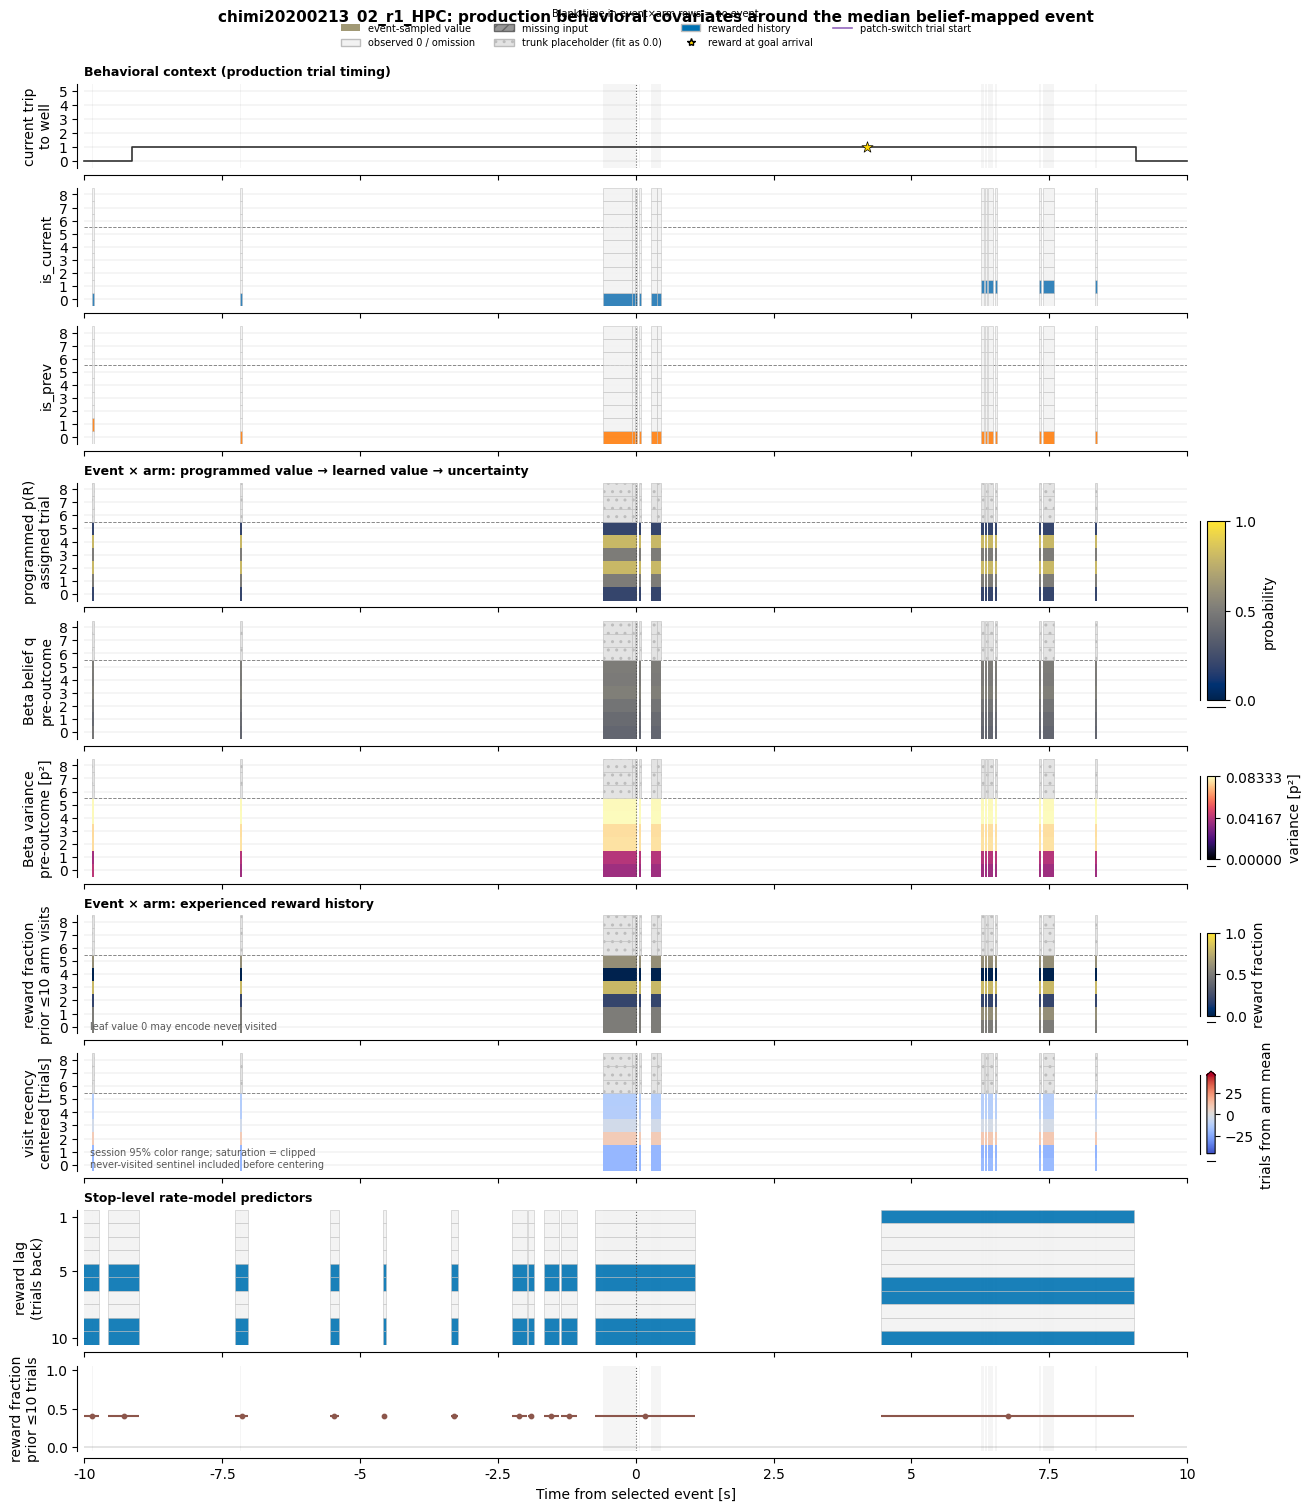

In [30]:
belief_event_times = event_table.loc[
    event_table["event_id"].isin(mapped_belief_events), "event_midpoint_time"
].sort_values()
if belief_event_times.empty:
    raise ValueError("no belief-mapped replay event is available for the audit figure")

audit_center = float(belief_event_times.iloc[len(belief_event_times) // 2])
audit_half_width_s = 10.0
audit_window = (
    max(float(posterior.time.values[0]), audit_center - audit_half_width_s),
    min(float(posterior.time.values[-1]), audit_center + audit_half_width_s),
)
audit_panels = (
    "trial_rail",
    "is_current",
    "is_prev",
    *BEHAVIORAL_MODEL_PANELS,
    "reward_rate_arm_k10",
    "visit_recency_demeaned",
    "reward_lag_kernel",
    "reward_rate_trial_k10",
)

fig, mismatch_table = plot_session_tables(
    data={"trials": trials, "track_graph": track_graph, "environment": env},
    detector=None,
    results=posterior,
    event_table=event_table,
    event_arm_table=event_arm_table,
    event_sequence_table=event_sequence_table,
    stop_table=stop_table,
    event_patch_table=event_patch_table,
    time_window=audit_window,
    panels=audit_panels,
    figsize=(13, 15),
    time_reference=audit_center,
    xlabel="Time from selected event [s]",
    title=(
        f"{SESSION_ID}: production behavioral covariates around the "
        "median belief-mapped event"
    ),
    panel_group_labels={
        "trial_rail": "Behavioral context (production trial timing)",
        "p_reward_arm": "Event × arm: programmed value → learned value → uncertainty",
        "reward_rate_arm_k10": "Event × arm: experienced reward history",
        "reward_lag_kernel": "Stop-level rate-model predictors",
    },
)
assert mismatch_table["match"].all(), mismatch_table.loc[~mismatch_table["match"]]
print(
    "trial-context audit:",
    f"{int((~mismatch_table['match']).sum())}/{len(mismatch_table)} mismatches",
)

### 6c. Where does decoded content land? (unadjusted)

Empirical share of MAP timebins per arm across all events in this epoch, with
the current/previous-arm masses highlighted. This is a bin-weighted,
unadjusted description — not the M1 coefficient. M1 conditions within event
and controls static arm occupancy with arm fixed effects.

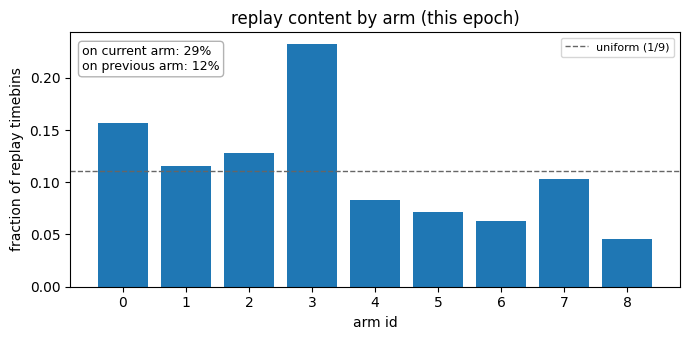

In [31]:
arm_mass = event_arm_table.groupby("arm")["arm_count_hard"].sum()
arm_mass = arm_mass / arm_mass.sum()
frac_current = (
    (event_arm_table["arm_count_hard"] * event_arm_table["is_current"]).sum()
    / event_arm_table["arm_count_hard"].sum()
)
frac_prev = (
    (event_arm_table["arm_count_hard"] * event_arm_table["is_prev"]).sum()
    / event_arm_table["arm_count_hard"].sum()
)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(arm_mass.index, arm_mass.values, color="C0")
ax.axhline(1 / 9, color="0.4", ls="--", lw=1, label="uniform (1/9)")
ax.set(xlabel="arm id", ylabel="fraction of replay timebins",
       title="replay content by arm (this epoch)")
ax.set_xticks(range(9))
ax.legend(fontsize=8)
ax.text(0.02, 0.95,
        f"on current arm: {frac_current:.0%}\non previous arm: {frac_prev:.0%}",
        transform=ax.transAxes, va="top", fontsize=9,
        bbox=dict(boxstyle="round", fc="white", ec="0.7"))
fig.tight_layout()

### 6d. Model-light uncertainty/content view

`build_trial_leaf_table` aggregates repeated stops to one row per behavioral
trial × reward well and deliberately retains zero-replay trials. Uncertainty
quartiles are assigned **within session and well**, so a persistently more
uncertain physical well cannot create the trend by itself. The production
profile helper first estimates each physical well and then weights wells
equally; its absolute-rate estimand is a ratio of summed posterior mass to
summed immobility exposure. We focus descriptively on unchosen destination
wells: this conditioning uses the realized trial destination, so it is not a
predictor-safe causal control. The conditional panel asks how observed replay
content is allocated, while the absolute panel also retains no-replay trials.

belief/replay coverage: stops=99.3%, events=99.2%, posterior mass=99.0%


uncertainty_quartile     value  sem  arm_uncertainty  n_animals
estimand                                                                                  
conditional_event_share 0                   1.0  0.098623  NaN         0.042544          1
                        1                   2.0  0.091230  NaN         0.058932          1
                        2                   3.0  0.104670  NaN         0.072009          1
                        3                   4.0  0.116067  NaN         0.081616          1
absolute_rate           0                   1.0  3.978427  NaN         0.042704          1
                        1                   2.0  4.061652  NaN         0.058844          1
                        2                   3.0  3.632655  NaN         0.071939          1
                        3                   4.0  5.586077  NaN         0.081595          1

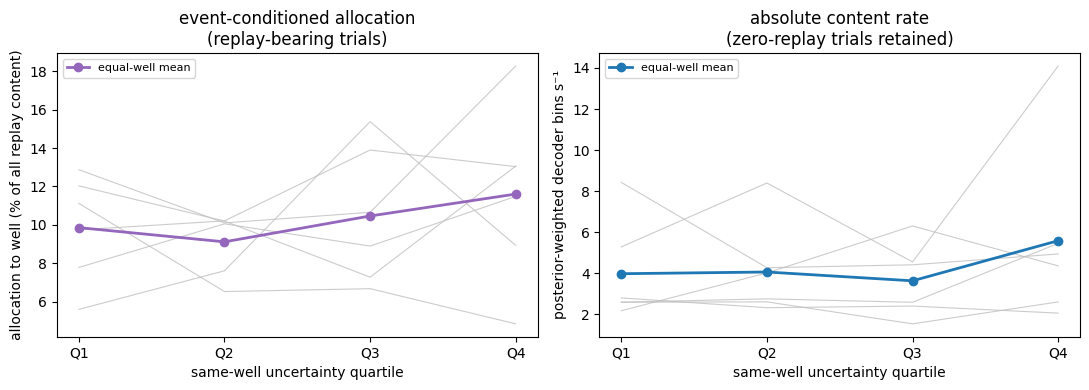

In [32]:
trial_leaf_table, belief_replay_audit = build_trial_leaf_table(
    event_arm_table, stop_table, qvals_session
)
trial_group = ["session_id", "trial_number_by_epoch"]
assert len(trial_leaf_table) == 6 * trial_leaf_table[trial_group].drop_duplicates().shape[0]
assert (
    trial_leaf_table.groupby(trial_group, observed=True)["arm"].nunique() == 6
).all()

print(
    "belief/replay coverage:",
    f"stops={belief_replay_audit['stop_qvals_coverage']:.1%},",
    f"events={belief_replay_audit['event_qvals_coverage']:.1%},",
    f"posterior mass={belief_replay_audit['posterior_mass_qvals_coverage']:.1%}",
)

conditional_profiles = hierarchical_quartile_profile(
    trial_leaf_table,
    numerator_col="posterior_event_share",
    scope="unchosen",
)
absolute_profiles = hierarchical_quartile_profile(
    trial_leaf_table,
    numerator_col="posterior_mass",
    denominator_col="immobility_time",
    scope="unchosen",
)
conditional_overall = conditional_profiles["overall"]
absolute_overall = absolute_profiles["overall"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for _arm, group in conditional_profiles["arm"].groupby("arm", observed=True):
    x = group["uncertainty_quartile"].to_numpy(dtype=float)
    axes[0].plot(
        x, 100 * group["value"], color="0.75", lw=0.8, alpha=0.8
    )
for _arm, group in absolute_profiles["arm"].groupby("arm", observed=True):
    x = group["uncertainty_quartile"].to_numpy(dtype=float)
    axes[1].plot(x, group["value"], color="0.75", lw=0.8, alpha=0.8)

x = conditional_overall["uncertainty_quartile"].to_numpy(dtype=float)
axes[0].plot(
    x,
    100 * conditional_overall["value"],
    "o-",
    color="C4",
    lw=2,
    label="equal-well mean",
)
x = absolute_overall["uncertainty_quartile"].to_numpy(dtype=float)
axes[1].plot(
    x,
    absolute_overall["value"],
    "o-",
    color="C0",
    lw=2,
    label="equal-well mean",
)
axes[0].set(
    xlabel="same-well uncertainty quartile",
    ylabel="allocation to well (% of all replay content)",
    title="event-conditioned allocation\n(replay-bearing trials)",
)
axes[1].set(
    xlabel="same-well uncertainty quartile",
    ylabel="posterior-weighted decoder bins s⁻¹",
    title="absolute content rate\n(zero-replay trials retained)",
)
for ax in axes:
    ax.set_xticks([1, 2, 3, 4], labels=["Q1", "Q2", "Q3", "Q4"])
    ax.legend(fontsize=8)
fig.tight_layout()
display(  # noqa: F821
    pd.concat(
        {
            "conditional_event_share": conditional_overall,
            "absolute_rate": absolute_overall,
        },
        names=["estimand"],
    )
)

### 6e. Within-arm exploit/explore sensitivity

Beta forgetting makes uncertainty rise when a well has not been visited, and
Beta variance also depends nonlinearly on mean value. An unadjusted uncertainty
plot therefore cannot distinguish these ingredients. The production
sensitivity fit restricts to non-current reward wells, removes each arm's mean,
and co-fits uncertainty, learned value, distance, and visit recency. The
production helper standardizes raw value, distance, and recency over the
pooled **non-current leaf** subset; uncertainty retains the persisted
all-event/all-arm standardization (including structural trunk zeros). These
are fixed cross-session scales, but not identical reference populations. This
cell therefore reads the small session-coefficient artifact produced by the
full-table workflow rather than re-standardizing this epoch
(`scripts/replay_models/content/analyze_uncertainty_content.py`). The result is a
descriptive OLS association after adjustment—not an independent uncertainty
effect, a conditional-Poisson rate ratio, or population inference.
`SWR` here means SWR-overlapping non-local events, not all detected SWRs.
The response is hard-MAP `arm_fraction`; the posterior-weighted profiles above
are a separate robustness estimand.
Schema and row-count checks below establish cohort compatibility with this
build; regenerating the production artifact remains the coefficient-freshness
guarantee.

In [33]:
all_horserace = pd.read_csv(HORSERACE_COEFS_FILE)
horse_coef_columns = [
    "coef_arm_uncertainty_z",
    "coef_q_arm_z",
    "coef_dist_to_arm_z",
    "coef_visit_recency_z",
]
horse_required_columns = {
    "animal",
    "session_id",
    "population",
    "n_rows",
    "cond_number",
    *horse_coef_columns,
}
missing_horse_columns = sorted(horse_required_columns - set(all_horserace.columns))
if missing_horse_columns:
    raise ValueError(
        f"horse-race artifact is missing columns: {missing_horse_columns}"
    )
selected_horserace_id = "/".join(
    str(event_arm_table[col].iloc[0]) for col in ("animal", "day", "epoch")
)
belief_horserace = all_horserace.loc[
    all_horserace["session_id"].eq(selected_horserace_id)
].copy()
del all_horserace
if belief_horserace.empty:
    raise ValueError(f"no horse-race result for {selected_horserace_id}")
expected_populations = {"all", "SWR", "non_SWR"}
if (
    set(belief_horserace["population"]) != expected_populations
    or belief_horserace["population"].duplicated().any()
):
    raise ValueError(
        "horse-race artifact must have exactly one selected-session row for "
        f"each population: {sorted(expected_populations)}"
    )
selected_animal = str(event_arm_table["animal"].iloc[0])
if not belief_horserace["animal"].astype(str).eq(selected_animal).all():
    raise ValueError("horse-race artifact animal disagrees with the selected epoch")
horse_numeric_columns = ["n_rows", "cond_number", *horse_coef_columns]
if not np.isfinite(
    belief_horserace[horse_numeric_columns].to_numpy(dtype=float)
).all():
    raise ValueError("selected horse-race diagnostics and coefficients must be finite")
horse_predictors = [
    "arm_fraction",
    "arm_uncertainty_z",
    "q_arm",
    "dist_to_arm",
    "visit_recency",
]
local_horse_rows = event_arm_table.loc[
    event_arm_table["arm"].le(5) & event_arm_table["is_current"].eq(0)
]
population_masks = {
    "all": pd.Series(True, index=local_horse_rows.index),
    "SWR": local_horse_rows["is_swr"].astype(bool),
    "non_SWR": ~local_horse_rows["is_swr"].astype(bool),
}
for population, mask in population_masks.items():
    expected_rows = len(local_horse_rows.loc[mask, horse_predictors].dropna())
    observed_rows = int(
        belief_horserace.loc[
            belief_horserace["population"].eq(population), "n_rows"
        ].item()
    )
    assert observed_rows == expected_rows
horserace_columns = [
    "population",
    "n_rows",
    "cond_number",
    *horse_coef_columns,
]
belief_horserace[horserace_columns].set_index("population").round(4)

,n_rows,cond_number,coef_arm_uncertainty_z,coef_q_arm_z,coef_dist_to_arm_z,coef_visit_recency_z
population,,,,,,
all,8420,3.3598,0.0254,-0.0065,0.0074,0.0078
SWR,3820,3.5895,0.0552,0.0026,-0.0044,-0.0008
non_SWR,4600,3.7500,0.0044,-0.0170,0.0080,0.0073


## 7. Regression models (this epoch = one production unit)

All four families are fit on **this single session's** events/stops. Arm and
patch content condition on event; choice conditions on stop; the rate model
is instead an ordinary Poisson GLM with an intercept and a log-exposure
offset. Arm, patch, and choice comparison blocks use the same union
complete-case unit gate as their production comparison workflows. The
per-stop rate block instead calls each production fitter on the original
`stop_table`, preserving the rate runner's per-rung complete-case cohorts.
Consequently, rate AIC gains are shown only when parent and child use the
exact same stop IDs (not merely the same count); held-out log likelihood and
the reported `n_units` remain the primary production-parity diagnostics.

The thin adapter below derives each displayed model block's predictor union;
the package's production selector performs all cohort filtering. The other
helpers only present fields returned by the package fitters.

In [34]:
def freeze_complete_case_units(
    frame: pd.DataFrame,
    specs: dict,
    *,
    unit_col: str,
    required_cols: tuple[str, ...],
    response_col: str | None = None,
    offset_col: str | None = None,
    drop_zero_response: bool = False,
    choice_response_col: str | None = None,
) -> tuple[pd.DataFrame, dict[str, object]]:
    """Thin notebook adapter over the production common-cohort selector."""
    predictors = sorted(
        {predictor for spec in specs.values() for predictor in spec.predictors}
    )
    return freeze_common_cohort(
        frame,
        unit_col=unit_col,
        required_cols=(*required_cols, *predictors),
        response_col=response_col,
        drop_zero_response=drop_zero_response,
        offset_col=offset_col,
        choice_response_col=choice_response_col,
    )


def cohort_count_summary(report: dict[str, object]) -> dict[str, object]:
    """Compact presentation of the production selector's full audit report."""
    fields = (
        "n_units_before",
        "n_missing_units",
        "n_nonpositive_offset_units",
        "n_zero_response_units",
        "n_invalid_choice_units",
        "n_units_after",
        "n_rows_after",
    )
    return {field: report[field] for field in fields}


def fits_to_stat_frame(
    fits: dict[str, dict | None],
    spec_map: dict,
    *,
    cohort_ids: dict[str, tuple] | None = None,
) -> pd.DataFrame:
    """Tidy per-model fit statistics from fitter return dicts (presentation only).

    The four fitters return slightly different key sets — the conditional
    Poisson emits ``aic``/``pseudo_r2``; the rate GLM emits ``aic`` and
    ``n_stops``; the conditional logit emits only the partial ``llf`` (no
    AIC). AIC gains are reported only against each specification's declared
    parent, preserving declared reporting branches such as Rlag ← R0;
    positive means the child has lower AIC and is favored.
    """
    rows = []
    for name, res in fits.items():
        spec = spec_map[name]
        if res is None:
            rows.append(
                {
                    "model": name,
                    "status": "skipped (insufficient/rank-deficient)",
                    "n_predictors": len(spec.predictors),
                }
            )
            continue
        status = "fit"
        if res.get("converged") is False:
            status = "nonconverged"
        elif res.get("separated") is True:
            status = "separated"
        rows.append(
            {
                "model": name,
                "n_predictors": len(spec.predictors),
                "n_units": res.get("n_events", res.get("n_stops")),
                "n_rows": res.get("n_rows"),
                "llf": res.get("llf"),
                "aic": res.get("aic"),
                "bic": res.get("bic"),
                "pseudo_r2": res.get("pseudo_r2"),
                "converged": res.get("converged"),
                "separated": res.get("separated"),
                "n_fit_warnings": res.get("n_convergence_warnings"),
                "cv_ll_per_stop_mean": res.get("cv_ll_per_stop_mean"),
                "cv_ll_per_stop_std": res.get("cv_ll_per_stop_std"),
                "cv_ll_per_event_mean": res.get("cv_ll_per_event_mean"),
                "cv_ll_per_event_std": res.get("cv_ll_per_event_std"),
                "cv_ll_per_timebin_mean": res.get("cv_ll_per_timebin_mean"),
                "cv_ll_per_timebin_std": res.get("cv_ll_per_timebin_std"),
                "cv_n_folds": res.get("cv_n_folds"),
                "cv_n_nonconverged_folds": res.get(
                    "cv_n_nonconverged_folds"
                ),
                "cv_n_separated_folds": res.get("cv_n_separated_folds"),
                "status": status,
            }
        )
    out = pd.DataFrame(rows).set_index("model")
    # Drop columns a given family never populates (e.g. no AIC for the logit).
    out = out.dropna(axis=1, how="all")
    if "aic" in out:
        out["aic_gain_vs_parent"] = np.nan
        for name in out.index:
            parent = spec_map[name].parent
            if cohort_ids is None:
                # Arm/patch blocks are passed one already-frozen common frame.
                same_cohort = (
                    "n_units" in out
                    and parent in out.index
                    and pd.notna(out.loc[parent, "n_units"])
                    and out.loc[parent, "n_units"] == out.loc[name, "n_units"]
                )
            else:
                # Per-rung rate fits start from the original stop table. Exact
                # IDs, not equal counts, are required for an AIC comparison.
                same_cohort = (
                    parent in cohort_ids
                    and name in cohort_ids
                    and cohort_ids[parent] == cohort_ids[name]
                )
            if (
                parent in out.index
                and out.loc[parent, "status"] == "fit"
                and out.loc[name, "status"] == "fit"
                and pd.notna(out.loc[name, "aic"])
                and same_cohort
            ):
                out.loc[name, "aic_gain_vs_parent"] = (
                    out.loc[parent, "aic"] - out.loc[name, "aic"]
                )
    return out


def coefs_to_frame(res: dict, spec) -> pd.DataFrame:
    """Coefficient / SE / p-value table for one fitted model."""
    rows = []
    for p in spec.predictors:
        rows.append({
            "predictor": p,
            "coef": res.get(f"coef_{p}"),
            "se": res.get(f"bse_{p}"),
            "pval": res.get(f"pval_{p}"),
            "rate_ratio": res.get(f"rr_{p}"),
            "vif": res.get(f"vif_{p}"),
        })
    return pd.DataFrame(rows).set_index("predictor").dropna(axis=1, how="all")


def fit_is_reliable(res: dict | None) -> bool:
    """Whether a fit is safe to summarize beyond its diagnostic row."""
    return (
        res is not None
        and res.get("converged", True) is not False
        and not bool(res.get("separated", False))
    )

### 7a. Arm content — M0–M7 (conditional Poisson)

Response `arm_count_hard`, grouped by `event_id`, 9 arms per event. M0 is the
uniform null; M0a adds arm geometry; M1–M7 add spatial context, value/memory,
and SWR interactions in nested steps. Parent→child AIC comparisons require
the exact same events, so the union complete-case cohort is frozen first.

In [35]:
arm_fit_table, arm_cohort = freeze_complete_case_units(
    event_arm_table,
    ARM_MODELS,
    unit_col="event_id",
    required_cols=("arm_count_hard",),
    response_col="arm_count_hard",
    drop_zero_response=True,
)
print("arm common cohort:", cohort_count_summary(arm_cohort))

arm_fits = {
    name: fit_conditional_poisson(
        arm_fit_table,
        predictors=list(spec.predictors),
        response_col="arm_count_hard",
        event_col="event_id",
        n_categories=9,
    )
    for name, spec in ARM_MODELS.items()
}
arm_stats = fits_to_stat_frame(arm_fits, ARM_MODELS)
assert arm_stats.loc[arm_stats["n_units"].notna(), "n_units"].nunique() <= 1
arm_stats

arm common cohort: {'n_units_before': 1714, 'n_missing_units': 17, 'n_nonpositive_offset_units': 0, 'n_zero_response_units': 0, 'n_invalid_choice_units': 0, 'n_units_after': 1697, 'n_rows_after': 15273}


,n_predictors,n_units,n_rows,llf,aic,bic,pseudo_r2,converged,separated,n_fit_warnings,status,aic_gain_vs_parent
model,,,,,,,,,,,,
M0,0,1697,15273,-143030.531086,286061.062173,286061.062173,0.000000,None,None,NaN,fit,NaN
M0a,8,1697,15273,-135713.935988,271443.871976,271487.364914,0.051154,True,False,0.0,fit,14617.190197
M1,9,1697,15273,-130985.992085,261989.984169,262038.913725,0.084210,True,False,0.0,fit,9453.887806
M2,10,1697,15273,-130685.050716,261390.101432,261444.467605,0.086314,True,False,0.0,fit,599.882737
M3,11,1697,15273,-130681.774601,261385.549201,261445.351991,0.086337,True,False,0.0,fit,4.552231
M4,12,1697,15273,-130208.729431,260441.458863,260506.698270,0.089644,True,False,0.0,fit,944.090339
M5,13,1697,15273,-130193.779446,260413.558892,260484.234917,0.089748,True,False,0.0,fit,27.899970
M6,15,1697,15273,-128472.070129,256974.140257,257055.689516,0.101786,True,False,0.0,fit,3439.418635
M7,18,1697,15273,-125182.705584,250401.411167,250499.270278,0.124783,True,False,0.0,fit,6572.729090


Coefficients of the full model (M7). Because M7 carries `swr_x_*`, each main
spatial/value coefficient is the non-SWR reference effect; its SWR counterpart
is main + interaction. Exponentiating a coefficient gives a conditional
arm-allocation ratio, not events/second. `vif` flags near-collinearity within
this session.

In [36]:
if fit_is_reliable(arm_fits["M7"]):
    m7_coefs = coefs_to_frame(arm_fits["M7"], ARM_MODELS["M7"])
    display(m7_coefs.round(3))  # noqa: F821 (IPython display)
else:
    print("M7 is unavailable or flagged; coefficients are suppressed (see diagnostics).")

,coef,se,pval,vif
predictor,,,,
arm_fe_0,0.842,0.025,0.0,2.715
arm_fe_1,1.002,0.025,0.0,2.557
arm_fe_2,0.720,0.026,0.0,2.732
arm_fe_3,1.503,0.027,0.0,3.932
arm_fe_4,0.531,0.023,0.0,1.796
arm_fe_5,0.470,0.027,0.0,2.862
arm_fe_6,0.325,0.024,0.0,1.778
arm_fe_7,0.813,0.022,0.0,1.778
is_current,1.126,0.015,0.0,2.248


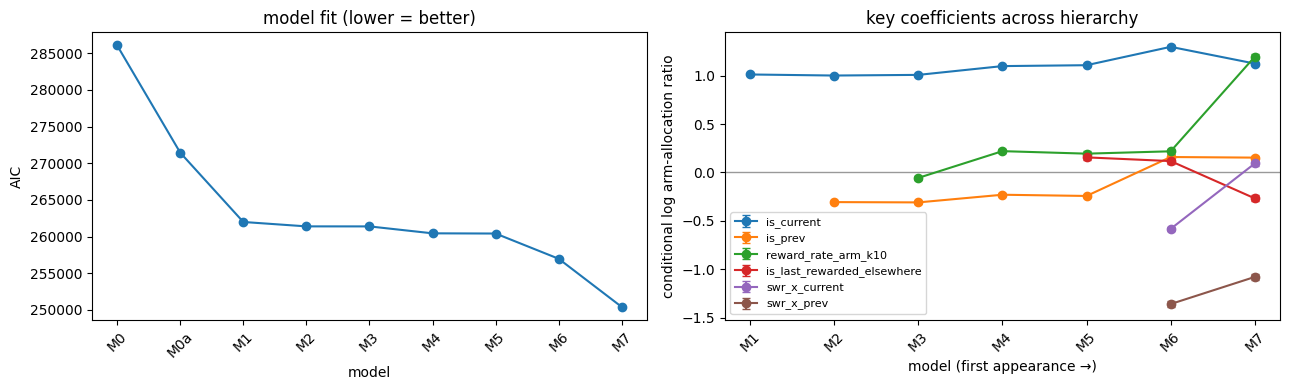

In [37]:
# AIC trajectory + key non-geometry coefficients across the hierarchy.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

fit_models = arm_stats[arm_stats["status"] == "fit"]
axes[0].plot(fit_models.index, fit_models["aic"], "o-", color="C0")
axes[0].set(xlabel="model", ylabel="AIC", title="model fit (lower = better)")
axes[0].tick_params(axis="x", rotation=45)

# Track a few interpretable coefficients where present.
track = ["is_current", "is_prev", "reward_rate_arm_k10",
         "is_last_rewarded_elsewhere", "swr_x_current", "swr_x_prev"]
for predictor in track:
    xs, ys, es = [], [], []
    for name, res in arm_fits.items():
        if fit_is_reliable(res) and f"coef_{predictor}" in res:
            xs.append(name)
            ys.append(res[f"coef_{predictor}"])
            es.append(res.get(f"bse_{predictor}", np.nan))
    if xs:
        axes[1].errorbar(xs, ys, yerr=es, marker="o", capsize=3, label=predictor)
axes[1].axhline(0, color="0.6", lw=1)
axes[1].set(xlabel="model (first appearance →)",
            ylabel="conditional log arm-allocation ratio",
            title="key coefficients across hierarchy")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(fontsize=8)
fig.tight_layout()

### 7b. Behavioral value and uncertainty branches

These comparisons isolate the behavioral-belief story on one frozen cohort:

* **M5 → Mv** adds the two-degree-of-freedom nominal + learned-value block;
* **M5 → Mu** adds model-derived Beta uncertainty after the M5 spatial,
  empirical reward-history, recency, and arm-identity adjustments;
* **Mu → Mvu** adds learned value conditional on uncertainty;
* **P3 → Pv** adds nominal + learned value after collapsing each pair of
  reward wells into a patch.

Mv and Mvu are not nested: Mv includes nominal value whereas Mvu replaces it
with uncertainty, so no parent-relative gain is reported between them. The
arm-level raw `p_reward_arm`/`q_arm` coefficients are per 1.0 probability,
while `arm_uncertainty_z` is per pooled-global SD. The coefficient table below
therefore also puts all three on the persisted global-SD scale for
presentation. VIFs remain visible because value, variance, recency, and arm
identity are substantially coupled in a single epoch.

All M/P models ask **where content is allocated given a detected event**; they
do not estimate whether an event occurs. AIC is in-sample. Five-fold
event-held-out conditional log likelihood is shown beside it because a large
AIC gain need not imply a large held-out improvement. These values are one
illustrative session, not population evidence.

In [38]:
belief_arm_fit_table, belief_arm_cohort = freeze_complete_case_units(
    event_arm_table,
    BELIEF_ARM_MODELS,
    unit_col="event_id",
    required_cols=("arm_count_hard",),
    response_col="arm_count_hard",
    drop_zero_response=True,
)
print("behavioral arm common cohort:", cohort_count_summary(belief_arm_cohort))

belief_arm_fits = {}
for name, spec in BELIEF_ARM_MODELS.items():
    fit = fit_conditional_poisson(
        belief_arm_fit_table,
        predictors=list(spec.predictors),
        response_col="arm_count_hard",
        event_col="event_id",
        n_categories=9,
    )
    cv = cross_validate_conditional_poisson(
        belief_arm_fit_table,
        predictors=list(spec.predictors),
        response_col="arm_count_hard",
        event_col="event_id",
        n_categories=9,
    )
    if fit is not None and cv is not None:
        fit.update(cv)
    belief_arm_fits[name] = fit

belief_arm_stats = fits_to_stat_frame(belief_arm_fits, BELIEF_ARM_MODELS)
assert belief_arm_stats.loc[
    belief_arm_stats["n_units"].notna(), "n_units"
].nunique() <= 1
display(  # noqa: F821
    belief_arm_stats.reindex(
        columns=[
            "n_units",
            "aic",
            "aic_gain_vs_parent",
            "cv_ll_per_event_mean",
            "cv_ll_per_event_std",
            "cv_n_nonconverged_folds",
            "cv_n_separated_folds",
            "status",
        ]
    ).round(3)
)

behavioral arm common cohort: {'n_units_before': 1714, 'n_missing_units': 30, 'n_nonpositive_offset_units': 0, 'n_zero_response_units': 0, 'n_invalid_choice_units': 0, 'n_units_after': 1684, 'n_rows_after': 15156}


,n_units,aic,aic_gain_vs_parent,cv_ll_per_event_mean,cv_ll_per_event_std,cv_n_nonconverged_folds,cv_n_separated_folds,status
model,,,,,,,,
M5,1684,258880.362,NaN,-77.233,2.765,0,0,fit
Mv,1684,258251.290,629.072,-77.100,2.716,0,0,fit
Mu,1684,258298.741,581.621,-77.093,2.969,0,0,fit
Mvu,1684,258225.577,73.164,-77.084,2.946,0,0,fit


In [39]:
belief_arm_terms = {
    "Mv": ("p_reward_arm", "q_arm"),
    "Mu": ("arm_uncertainty_z",),
    "Mvu": ("q_arm", "arm_uncertainty_z"),
}
belief_effect_rows = []
for name, predictors in belief_arm_terms.items():
    fit = belief_arm_fits[name]
    if not fit_is_reliable(fit):
        continue
    for predictor in predictors:
        if predictor.endswith("_z"):
            scale = 1.0
            input_unit = "1 pooled-global SD"
        else:
            scale = used_arm_z_reference[predictor]["std"]
            input_unit = "1.0 reward probability"
        coefficient = fit.get(f"coef_{predictor}", np.nan)
        beta_sd = coefficient * scale
        belief_effect_rows.append(
            {
                "model": name,
                "predictor": predictor,
                "input_unit": input_unit,
                "coef_in_fit_units": coefficient,
                "se_in_fit_units": fit.get(f"bse_{predictor}", np.nan),
                "pval_within_session": fit.get(f"pval_{predictor}", np.nan),
                "vif": fit.get(f"vif_{predictor}", np.nan),
                "coef_per_global_sd": beta_sd,
                "allocation_ratio_per_global_sd": np.exp(beta_sd),
            }
        )
if belief_effect_rows:
    belief_arm_effects = pd.DataFrame(belief_effect_rows).set_index(
        ["model", "predictor"]
    )
    display(belief_arm_effects.round(3))  # noqa: F821
else:
    print("No behavioral arm fit is both available and unflagged.")

input_unit  coef_in_fit_units  se_in_fit_units  pval_within_session     vif  coef_per_global_sd  \
model predictor                                                                                                                        
Mv    p_reward_arm       1.0 reward probability             -0.625            0.028                  0.0   4.184              -0.175   
      q_arm              1.0 reward probability             -0.217            0.062                  0.0  16.535              -0.054   
Mu    arm_uncertainty_z      1 pooled-global SD              0.313            0.013                  0.0  12.131               0.313   
Mvu   q_arm              1.0 reward probability             -0.519            0.060                  0.0  15.359              -0.129   
      arm_uncertainty_z      1 pooled-global SD              0.301            0.013                  0.0  12.138               0.301   

                         allocation_ratio_per_global_sd  
model predictor                                          
Mv    p_reward_arm                                0.839  
      q_arm                                       0.947  
Mu    arm_uncertainty_z                           1.367  
Mvu   q_arm                                       0.879  
      arm_uncertainty_z                           1.352

In [40]:
belief_patch_fit_table, belief_patch_cohort = freeze_complete_case_units(
    event_patch_table,
    BELIEF_PATCH_MODELS,
    unit_col="event_id",
    required_cols=("patch_count_hard",),
    response_col="patch_count_hard",
    drop_zero_response=True,
)
print("behavioral patch common cohort:", cohort_count_summary(belief_patch_cohort))

belief_patch_fits = {}
for name, spec in BELIEF_PATCH_MODELS.items():
    fit = fit_conditional_poisson(
        belief_patch_fit_table,
        predictors=list(spec.predictors),
        response_col="patch_count_hard",
        event_col="event_id",
        n_categories=3,
    )
    cv = cross_validate_conditional_poisson(
        belief_patch_fit_table,
        predictors=list(spec.predictors),
        response_col="patch_count_hard",
        event_col="event_id",
        n_categories=3,
    )
    if fit is not None and cv is not None:
        fit.update(cv)
    belief_patch_fits[name] = fit

belief_patch_stats = fits_to_stat_frame(belief_patch_fits, BELIEF_PATCH_MODELS)
assert belief_patch_stats.loc[
    belief_patch_stats["n_units"].notna(), "n_units"
].nunique() <= 1
display(  # noqa: F821
    belief_patch_stats.reindex(
        columns=[
            "n_units",
            "aic",
            "aic_gain_vs_parent",
            "cv_ll_per_event_mean",
            "cv_ll_per_event_std",
            "cv_n_nonconverged_folds",
            "cv_n_separated_folds",
            "status",
        ]
    ).round(3)
)
if fit_is_reliable(belief_patch_fits["Pv"]):
    pv_coefs = coefs_to_frame(belief_patch_fits["Pv"], BELIEF_PATCH_MODELS["Pv"])
    display(  # noqa: F821
        pv_coefs.loc[["p_reward_arm_patch", "q_arm_patch"]].round(3)
    )
else:
    print("Pv is unavailable or flagged; coefficients are suppressed.")

behavioral patch common cohort: {'n_units_before': 1714, 'n_missing_units': 30, 'n_nonpositive_offset_units': 0, 'n_zero_response_units': 0, 'n_invalid_choice_units': 0, 'n_units_after': 1684, 'n_rows_after': 5052}


,n_units,aic,aic_gain_vs_parent,cv_ll_per_event_mean,cv_ll_per_event_std,cv_n_nonconverged_folds,cv_n_separated_folds,status
model,,,,,,,,
P3,1684,137855.170,NaN,-41.045,1.403,0,0,fit
Pv,1684,136624.583,1230.587,-40.757,1.580,0,0,fit


,coef,se,pval,vif
predictor,,,,
p_reward_arm_patch,1.125,0.041,0.0,1.376
q_arm_patch,0.830,0.092,0.0,1.788


### 7c. Patch content — P0–P4 (conditional Poisson, 3 categories)

Same estimator, arms collapsed to the three patches. Requires ≥10 events per
session (`fit_conditional_poisson` rejects below `2 × n_predictors` events;
the event-source comparison runner also gates patch fits at 10). P0–P4 share
the union complete-case event cohort; the qvals-dependent P3→Pv comparison is
kept in the separate matched-cohort branch above. Patch value is the mean of
the two leaf values, not a value-to-go estimate. Coefficients are conditional
log patch-allocation ratios, not event-rate effects.

In [41]:
patch_fit_table, patch_cohort = freeze_complete_case_units(
    event_patch_table,
    PATCH_MODELS,
    unit_col="event_id",
    required_cols=("patch_count_hard",),
    response_col="patch_count_hard",
    drop_zero_response=True,
)
print("patch common cohort:", cohort_count_summary(patch_cohort))

patch_fits = {
    name: fit_conditional_poisson(
        patch_fit_table,
        predictors=list(spec.predictors),
        response_col="patch_count_hard",
        event_col="event_id",
        n_categories=3,
    )
    for name, spec in PATCH_MODELS.items()
}
patch_stats = fits_to_stat_frame(patch_fits, PATCH_MODELS)
assert patch_stats.loc[patch_stats["n_units"].notna(), "n_units"].nunique() <= 1
patch_stats

patch common cohort: {'n_units_before': 1714, 'n_missing_units': 17, 'n_nonpositive_offset_units': 0, 'n_zero_response_units': 0, 'n_invalid_choice_units': 0, 'n_units_after': 1697, 'n_rows_after': 5091}


,n_predictors,n_units,n_rows,llf,aic,bic,pseudo_r2,converged,separated,n_fit_warnings,status,aic_gain_vs_parent
model,,,,,,,,,,,,
P0,0,1697,5091,-71515.265543,143030.531086,143030.531086,0.000000,None,None,NaN,fit,NaN
P1,1,1697,5091,-69615.238316,139232.476631,139237.913248,0.026568,True,False,0.0,fit,3798.054455
P2,2,1697,5091,-69593.191238,139190.382476,139201.255710,0.026876,True,False,0.0,fit,42.094155
P3,3,1697,5091,-69481.908117,138969.816234,138986.126085,0.028432,True,False,0.0,fit,220.566242
P4,5,1697,5091,-69279.104871,138568.209743,138595.392829,0.031268,True,True,0.0,separated,NaN


In [42]:
if fit_is_reliable(patch_fits["P4"]):
    display(coefs_to_frame(patch_fits["P4"], PATCH_MODELS["P4"]).round(3))  # noqa: F821
else:
    print("P4 is unavailable or flagged; coefficients are suppressed (see diagnostics).")

P4 is unavailable or flagged; coefficients are suppressed (see diagnostics).


### 7d. Event rate — R0–R2, Rlag (Poisson GLM, log-time offset)

`fit_per_stop_rate_model` regresses a count per stop with a
`log(immobility_time)` offset, so coefficients act on events/second rather
than raw counts. The current Family-A runner repeats the same ladder for four
canonical outcomes: detected SWRs (positive control), all non-local events,
and the SWR-overlap/non-SWR split of non-local events. Unit = stop;
production gate is ≥20 valid stops per session.

`R0 → R1 → R2` is nested: R1 adds past-only `reward_lag1` plus
switch context; R2 adds the trailing 10-trial reward rate. `Rlag` estimates
reward lags 1–10 separately. The declared reporting parents are R0→R1→R2
and R0→Rlag. As in production, each rung receives the original stop table and
`fit_per_stop_rate_model` applies that rung's own missingness/exposure gate.
Early R0–R2 stops therefore need not all appear in Rlag. The table reports
`n_units` for every rung and suppresses parent-relative AIC gain unless the
exact stop IDs match. Production's five-fold held-out log likelihood is
computed by the same package function here; higher `cv_ll_per_stop_mean` is
better. Treat CV values from different rung-specific cohorts as production-
parity diagnostics, not paired improvements. Compare fits only within the
same outcome and identical cohort, never across the four response
distributions.

This is **Family A**, the literature-comparable per-stop layer. The
time-resolved per-bin conditional-intensity ladder (**Family B**,
`MODEL_PER_BIN_RATE`) is not walked in this notebook — see
`docs/rate_models.md` and `scripts/replay_models/rate/fit_per_bin_rate_models.py`.

In [43]:
rate_fits = {}
rate_cohort_sizes = {}
rate_stat_frames = {}
reward_lag_cols = [f"reward_lag{lag}" for lag in range(1, N_REWARD_LAGS + 1)]
np.testing.assert_allclose(
    stop_table["reward_rate_trial_k10"].to_numpy(dtype=float),
    stop_table[reward_lag_cols].mean(axis=1).to_numpy(dtype=float),
    rtol=0,
    atol=1e-12,
    equal_nan=True,
)

for outcome, response_col in PER_STOP_RATE_OUTCOMES.items():
    fits = {}
    outcome_cohort_ids = {}
    for name, spec in RATE_MODELS.items():
        _, selection = freeze_common_cohort(
            stop_table,
            unit_col="stop_id",
            required_cols=(response_col, *spec.predictors),
            response_col=response_col,
            offset_col="immobility_time",
        )
        outcome_cohort_ids[name] = selection["included_ids"]
        fits[name] = fit_per_stop_rate_model(
            stop_table,
            list(spec.predictors),
            response_col=response_col,
            offset_col="immobility_time",
            min_stops=20,
        )
        if fits[name] is not None:
            assert fits[name]["n_stops"] == len(outcome_cohort_ids[name])
    for name, spec in RATE_MODELS.items():
        cv = cross_validate_per_stop_rate_model(
            stop_table,
            list(spec.predictors),
            response_col=response_col,
            offset_col="immobility_time",
            min_stops=20,
        )
        if fits[name] is not None and cv is not None:
            fits[name].update(cv)
    stats = fits_to_stat_frame(
        fits, RATE_MODELS, cohort_ids=outcome_cohort_ids
    )
    rate_fits[outcome] = fits
    rate_cohort_sizes[outcome] = {
        name: None if fit is None else int(fit["n_stops"])
        for name, fit in fits.items()
    }
    rate_stat_frames[outcome] = stats

print("production per-rung rate cohort sizes:", rate_cohort_sizes)
rate_stats = pd.concat(rate_stat_frames, names=["outcome", "model"])
rate_stats

production per-rung rate cohort sizes: {'swr': {'R0': 2238, 'R1': 2227, 'R2': 2227, 'Rlag': 2148}, 'non_local': {'R0': 2238, 'R1': 2227, 'R2': 2227, 'Rlag': 2148}, 'non_local_swr': {'R0': 2238, 'R1': 2227, 'R2': 2227, 'Rlag': 2148}, 'non_local_no_swr': {'R0': 2238, 'R1': 2227, 'R2': 2227, 'Rlag': 2148}}


n_predictors  n_units          llf          aic          bic  converged  separated  n_fit_warnings  cv_ll_per_stop_mean  \
outcome          model                                                                                                                            
swr              R0                0     2238  -791.603032  1585.206065  1590.919403       True      False               0            -0.354051   
                 R1                2     2227  -711.701522  1429.403045  1446.528277       True      False               0            -0.323070   
                 R2                3     2227  -710.135924  1428.271849  1451.105491       True      False               0            -0.322445   
                 Rlag             11     2148  -681.928160  1387.856319  1455.923829       True      False               0            -0.325196   
non_local        R0                0     2238 -1541.534148  3085.068295  3090.781633       True      False               0            -0.689328   
                 R1                2     2227 -1519.370010  3044.740020  3061.865252       True      False               0            -0.686855   
                 R2                3     2227 -1516.319794  3040.639589  3063.473232       True      False               0            -0.686864   
                 Rlag             11     2148 -1432.606484  2889.212967  2957.280477       True      False               0            -0.677440   
non_local_swr    R0                0     2238  -778.528610  1559.057220  1564.770558       True      False               0            -0.348457   
                 R1                2     2227  -700.715428  1407.430855  1424.556087       True      False               0            -0.318843   
                 R2                3     2227  -699.489421  1406.978843  1429.812486       True      False               0            -0.318376   
                 Rlag             11     2148  -672.763515  1369.527031  1437.594540       True      False               0            -0.320207   
non_local_no_swr R0                0     2238 -1421.637360  2845.274720  2850.988058       True      False               0            -0.636338   
                 R1                2     2227 -1386.593240  2779.186480  2796.311712       True      False               0            -0.626278   
                 R2                3     2227 -1384.566849  2777.133697  2799.967340       True      False               0            -0.627678   
                 Rlag             11     2148 -1275.586498  2575.172995  2643.240505       True      False               0            -0.609316   

                        cv_ll_per_stop_std  cv_n_folds  cv_n_nonconverged_folds  cv_n_separated_folds status  aic_gain_vs_parent  
outcome          model                                                                                                            
swr              R0               0.019142           5                        0                     0    fit                 NaN  
                 R1               0.019378           5                        0                     0    fit                 NaN  
                 R2               0.019517           5                        0                     0    fit            1.131196  
                 Rlag             0.028438           5                        0                     0    fit                 NaN  
non_local        R0               0.042074           5                        0                     0    fit                 NaN  
                 R1               0.033502           5                        0                     0    fit                 NaN  
                 R2               0.030861           5                        0                     0    fit            4.100431  
                 Rlag             0.026295           5                        0                     0    fit                 NaN  
non_local_swr    R0               0.021472           5             

In [44]:
r2_coefs = {
    outcome: coefs_to_frame(fits["R2"], RATE_MODELS["R2"])
    for outcome, fits in rate_fits.items()
    if fit_is_reliable(fits["R2"])
}
if r2_coefs:
    display(pd.concat(r2_coefs, names=["outcome", "predictor"]).round(3))  # noqa: F821
else:
    print("No R2 fit is both available and unflagged (see diagnostics).")

coef     se   pval  rate_ratio
outcome          predictor                                             
swr              reward_lag1            1.244  0.119  0.000       3.468
                 is_after_switch       -0.429  0.155  0.006       0.651
                 reward_rate_trial_k10 -0.395  0.223  0.077       0.674
non_local        reward_lag1            0.268  0.063  0.000       1.307
                 is_after_switch       -0.126  0.095  0.186       0.882
                 reward_rate_trial_k10 -0.369  0.149  0.014       0.692
non_local_swr    reward_lag1            1.217  0.119  0.000       3.376
                 is_after_switch       -0.477  0.160  0.003       0.621
                 reward_rate_trial_k10 -0.352  0.225  0.118       0.703
non_local_no_swr reward_lag1           -0.273  0.079  0.001       0.761
                 is_after_switch        0.124  0.118  0.295       1.132
                 reward_rate_trial_k10 -0.402  0.200  0.045       0.669

### 7e. Next-arm choice — C_* (conditional logit)

Is replay content associated with where the animal *goes next*, beyond a
behavioral baseline? `build_choice_dataset` makes a stop × candidate-arm
table: six well arms minus the current arm = five alternatives, with trunk
arms excluded. The current production workflow fits a primary block
(`C_replay_only`, `C_behavior`, `C_full`) and a separate SWR/non-SWR replay
block (`C_behavior`, `C_full_swr_split`), each on its own frozen stop cohort.
These are in-sample conditional-logit fits; there is no held-out choice CV.
`replay_frac` is the unweighted mean of per-event arm fractions within a stop;
the SWR-split terms are the corresponding event-type-restricted means. It is
not a duration- or decoder-bin-pooled fraction.
Coefficients are within-stop log relative-choice-odds (utility) slopes, not
calibrated predictive performance.

In [45]:
choice_df = build_choice_dataset(event_table, event_arm_table, stop_table)
if choice_df.empty:
    raise ValueError("this session has no valid replay stops with a next-arm choice")

choice_sizes = choice_df.groupby("stop_id").size()
chosen_per_stop = choice_df.groupby("stop_id")["chosen"].sum()
assert (choice_sizes == 5).all()
assert (chosen_per_stop == 1).all()
print(
    "choice_df:",
    choice_df.shape,
    f"({choice_df['stop_id'].nunique()} stops × 5 candidate well arms)",
)

choice_fit_table, choice_cohort = freeze_complete_case_units(
    choice_df,
    CHOICE_MODELS,
    unit_col="stop_id",
    required_cols=("chosen",),
    choice_response_col="chosen",
)
choice_split_fit_table, choice_split_cohort = freeze_complete_case_units(
    choice_df,
    CHOICE_SPLIT_MODELS,
    unit_col="stop_id",
    required_cols=("chosen",),
    choice_response_col="chosen",
)
print("choice primary cohort:", cohort_count_summary(choice_cohort))
print("choice SWR-split cohort:", cohort_count_summary(choice_split_cohort))

choice_fits = {
    name: fit_choice_model(
        choice_fit_table, list(spec.predictors), stop_col="stop_id"
    )
    for name, spec in CHOICE_MODELS.items()
}
choice_split_fits = {
    name: fit_choice_model(
        choice_split_fit_table, list(spec.predictors), stop_col="stop_id"
    )
    for name, spec in CHOICE_SPLIT_MODELS.items()
}
choice_primary_stats = fits_to_stat_frame(choice_fits, CHOICE_MODELS)
choice_split_stats = fits_to_stat_frame(choice_split_fits, CHOICE_SPLIT_MODELS)
assert choice_primary_stats.loc[
    choice_primary_stats["n_units"].notna(), "n_units"
].nunique() <= 1
assert choice_split_stats.loc[
    choice_split_stats["n_units"].notna(), "n_units"
].nunique() <= 1
choice_stats = pd.concat(
    {"primary": choice_primary_stats, "swr_split": choice_split_stats},
    names=["block", "model"],
)
choice_stats

choice_df: (1940, 21) (388 stops × 5 candidate well arms)
choice primary cohort: {'n_units_before': 388, 'n_missing_units': 6, 'n_nonpositive_offset_units': 0, 'n_zero_response_units': 0, 'n_invalid_choice_units': 0, 'n_units_after': 382, 'n_rows_after': 1910}
choice SWR-split cohort: {'n_units_before': 388, 'n_missing_units': 213, 'n_nonpositive_offset_units': 0, 'n_zero_response_units': 0, 'n_invalid_choice_units': 0, 'n_units_after': 175, 'n_rows_after': 875}


n_predictors  n_units  n_rows         llf  converged  separated  n_fit_warnings status
block     model                                                                                                   
primary   C_replay_only                1      382    1910 -613.732749       True      False               0    fit
          C_behavior                   4      382    1910 -213.845155       True      False               0    fit
          C_full                       5      382    1910 -213.842988       True      False               0    fit
swr_split C_behavior                   4      175     875  -51.985291       True      False               0    fit
          C_full_swr_split             6      175     875  -50.518358       True      False               0    fit

The partial-log-likelihood gains below quantify incremental **in-sample fit**.
They are guaranteed to be nonnegative when an identifiable predictor is added
and are not evidence of out-of-sample predictive improvement. The coefficient
p-value is the fitter's within-session Wald test.

In [46]:
if fit_is_reliable(choice_fits["C_full"]) and fit_is_reliable(
    choice_fits["C_behavior"]
):
    d_llf = choice_fits["C_full"]["llf"] - choice_fits["C_behavior"]["llf"]
    print(f"C_behavior partial llf : {choice_fits['C_behavior']['llf']:.2f}")
    print(f"C_full     partial llf : {choice_fits['C_full']['llf']:.2f}")
    print(f"2Δllf from +replay_frac: {2 * d_llf:.2f}  (1 added parameter)")
    print(f"replay_frac coef       : {choice_fits['C_full']['coef_replay_frac']:.3f}"
          f"  (p = {choice_fits['C_full']['pval_replay_frac']:.3g})")
else:
    print("C_full / C_behavior are not both available and unflagged.")

if (
    fit_is_reliable(choice_split_fits["C_full_swr_split"])
    and fit_is_reliable(choice_split_fits["C_behavior"])
):
    split_d_llf = (
        choice_split_fits["C_full_swr_split"]["llf"]
        - choice_split_fits["C_behavior"]["llf"]
    )
    print(f"2Δllf from SWR + non-SWR replay: {2 * split_d_llf:.2f} (2 added parameters)")
else:
    print("C_full_swr_split / C_behavior are not both available and unflagged.")

C_behavior partial llf : -213.85
C_full     partial llf : -213.84
2Δllf from +replay_frac: 0.00  (1 added parameter)
replay_frac coef       : 0.027  (p = 0.949)
2Δllf from SWR + non-SWR replay: 2.93 (2 added parameters)


In [47]:
if fit_is_reliable(choice_fits["C_full"]):
    display(coefs_to_frame(choice_fits["C_full"], CHOICE_MODELS["C_full"]).round(3))  # noqa: F821
else:
    print("C_full is unavailable or flagged; coefficients are suppressed.")

if fit_is_reliable(choice_split_fits["C_full_swr_split"]):
    display(  # noqa: F821
        coefs_to_frame(
            choice_split_fits["C_full_swr_split"],
            CHOICE_SPLIT_MODELS["C_full_swr_split"],
        ).round(3)
    )
else:
    print("C_full_swr_split is unavailable or flagged; coefficients are suppressed.")

,coef,se,pval
predictor,,,
visit_recency,0.007,0.003,0.018
cumulative_reward,0.417,0.098,0.000
reward_rate_arm_k10,0.830,0.422,0.049
arm_dist_rank,-0.597,0.037,0.000
replay_frac,0.027,0.423,0.949


,coef,se,pval
predictor,,,
visit_recency,0.011,0.006,0.060
cumulative_reward,0.656,0.208,0.002
reward_rate_arm_k10,1.412,0.899,0.116
arm_dist_rank,-0.805,0.090,0.000
replay_frac_swr,1.108,1.552,0.475
replay_frac_non_swr,1.466,0.902,0.104


## 8. Summary

| Family | Estimator | Unit | Asks |
|---|---|---|---|
| **M0–M7** | conditional Poisson (9 arms) | event | *Which arm* does replay represent? |
| **M5/Mv/Mu/Mvu** | conditional Poisson (9 arms) | event | Does conditional content allocation track nominal value, learned value, or Beta uncertainty? |
| **P0–P4** | conditional Poisson (3 patches) | event | *Which patch* does replay represent? |
| **P3/Pv** | conditional Poisson (3 patches) | event | Does conditional patch allocation track nominal and learned value? |
| **R0–R2, Rlag** × 4 outcomes | Poisson GLM + log-time offset | stop | *How often* do events occur? (Family A) |
| **C_\*** | conditional logit | stop | Is replay content associated with the *next choice*? |

The behavioral section now shows the model state itself, model-light
conditional-allocation and absolute-rate estimands, the production-scaled
within-arm sensitivity analysis, and the value/uncertainty content branches.
The valid nested paths are M5→Mv, M5→Mu, Mu→Mvu, and P3→Pv; Mv↔Mvu is not a
nested comparison. Content AIC and event-held-out likelihood, rate AIC and
held-out per-stop likelihood, choice partial-likelihood gains, coefficients,
VIFs, and explicit fit diagnostics expose both signal and fragility.

`q_arm` is a learned immediate reward probability, `arm_uncertainty` is its
model-derived Beta variance, and both are pre-outcome. Uncertainty remains
coupled to mean value and forgetting/recency; the adjusted association should
not be called causal or fully independent. Structural trunk zeros define the
design matrix, but scientific interpretation of these belief covariates is
restricted to reward-well arms. The current epoch is an illustrative fitting
unit—population conclusions still require the multi-session aggregation.

**Caveat — single-session estimates are noisy and correlational.** Some models
can fail the sample-size, rank, convergence, or separation checks surfaced
above. The population runners aggregate the retained per-session fits with
session-level inference, per-animal sign consistency, cohort audits, and
multiple-comparison control. Read this notebook as one audited fitting unit,
not as the scientific result.